# Data analysis

In [1]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import os
from collections import defaultdict
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [2]:
def pad_and_stack(arrs):
    max_len = max(len(a) for a in arrs)
    padded = np.empty((len(arrs), max_len))
    for j, a in enumerate(arrs):
        padded[j, :len(a)] = a
        padded[j, len(a):] = a[-1] 
    return padded

# BFGS with exposure = 3 s

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_0_run_0.npz
H_0


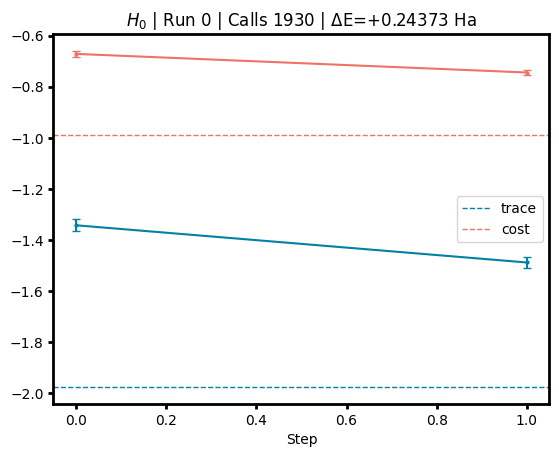

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_0_run_1.npz
H_0


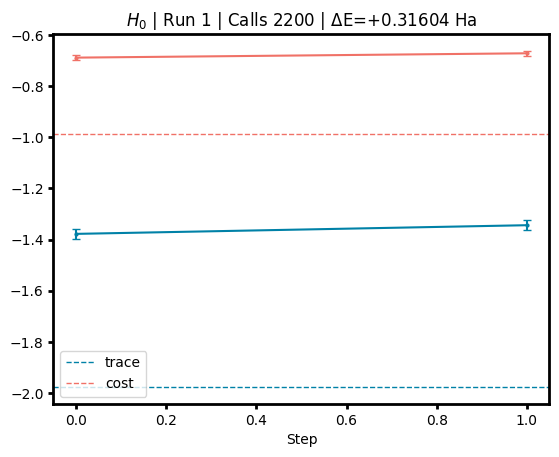

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_0_run_2.npz
H_0


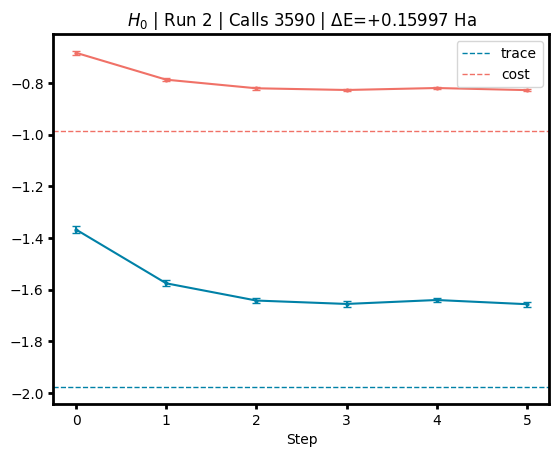

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_1_run_0.npz
H_1


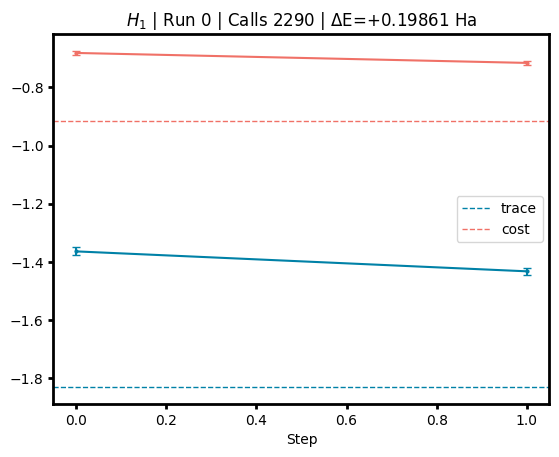

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_1_run_1.npz
H_1


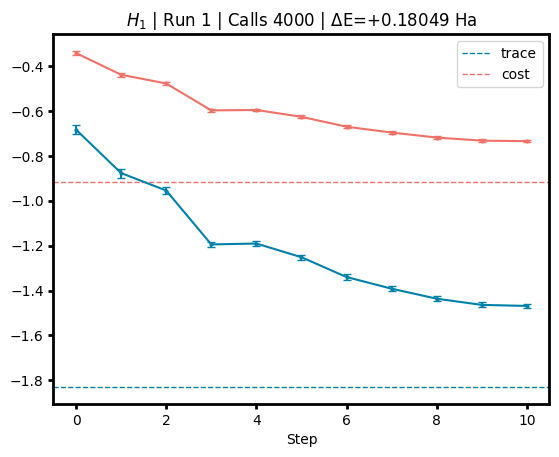

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_2_run_0.npz
H_2


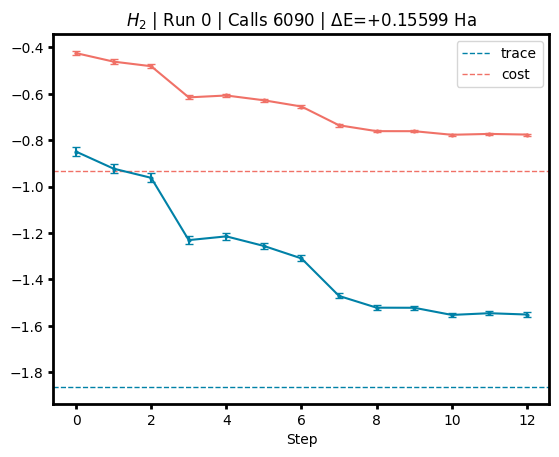

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_2_run_1.npz
H_2


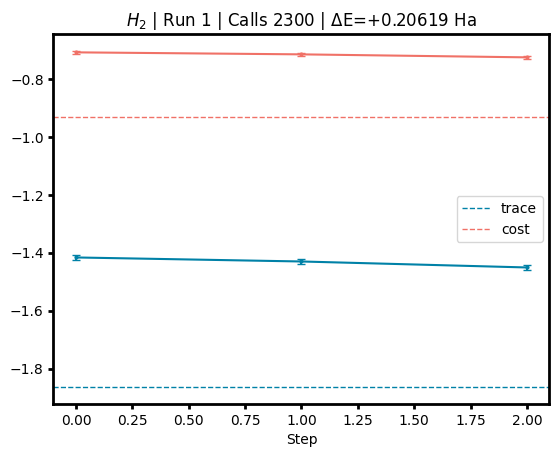

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_3_run_0.npz
H_3


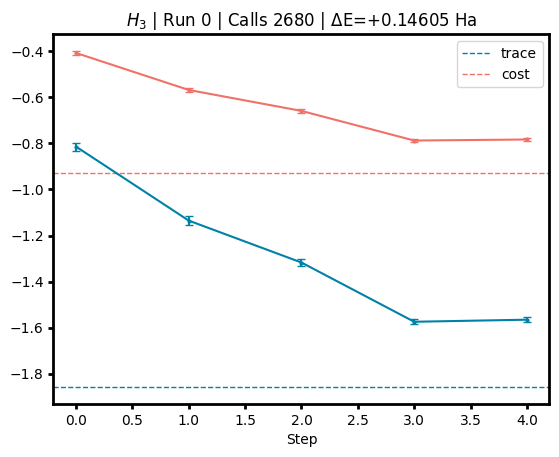

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_3_run_1.npz
H_3


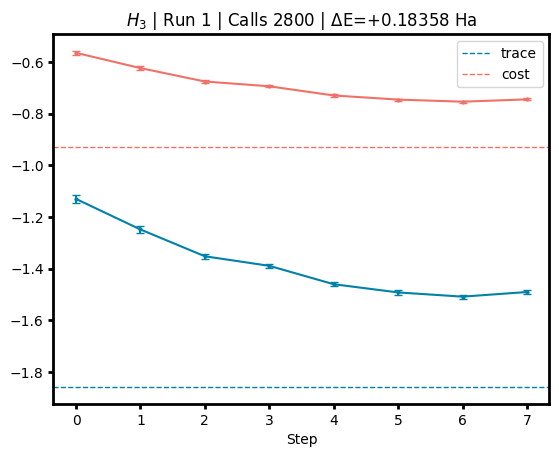

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_4_run_0.npz
H_4


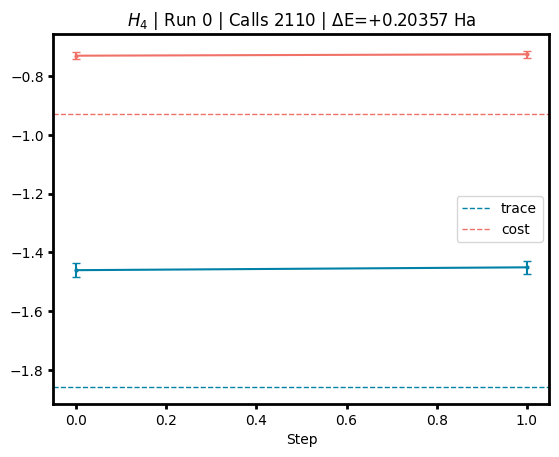

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_4_run_1.npz
H_4


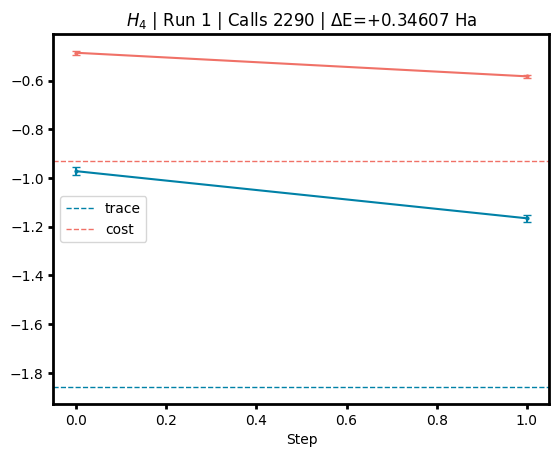

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_5_run_0.npz
H_5


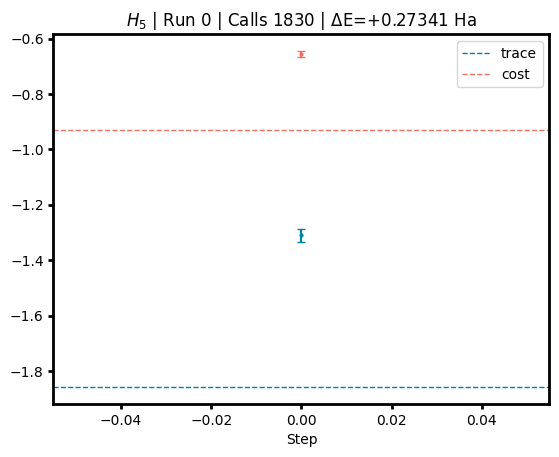

Loaded file ..\measurements\reorganized_files\BFGS exposure=3\H_5_run_1.npz
H_5


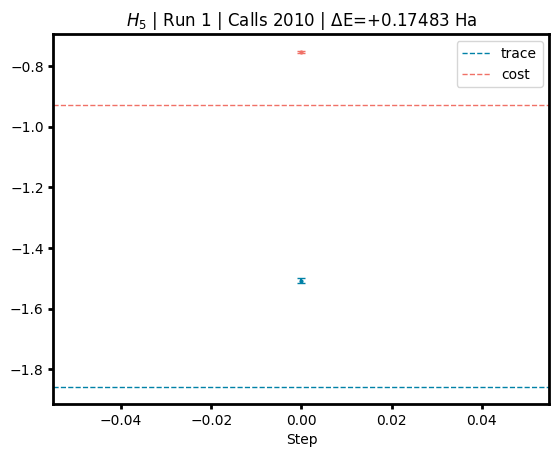

In [3]:
colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

location = Path("../measurements/reorganized_files/BFGS exposure=3")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        print(H)
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        density = np.array(data['density'])
        error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[1]
        fig, ax = plt.subplots()
        ax.spines[:].set_linewidth(2)
        ax.tick_params(width=2)
        xs = np.arange(len(cost))
    
        ax.set_xlabel("Step")
        ax.axhline(y=trace_true, color=colors[0], linewidth=1, ls='--',  label='trace')
        ax.axhline(y=cost_true, color=colors[5], linewidth=1, ls='--', label='cost')
        ax.errorbar(xs, trace, trace_e, marker='o', color = colors[0], markersize=2, capsize=3)
        ax.errorbar(xs, cost, cost_e, marker='o', color = colors[5], markersize=2, capsize=3)
        ax.set_title(f"${H}$ | Run {run} | Calls {calls} | ΔE={cost[-1]-cost_true:+.5f} Ha")
        ax.legend()
        plt.show()

In [13]:
sim_data = np.load(f'../Simulations/8-mode chip/BFGS_exp=3s/simulations.npz', allow_pickle=True)
cost_mean = sim_data['cost_mean'].item()
cost_std = sim_data['cost_std'].item()
trace_mean = sim_data['trace_mean'].item()
trace_std = sim_data['trace_std'].item()
cost_final_mean = sim_data['cost_final_mean'].item()
th_values_by_H = sim_data['th_values_by_H'].item()

## Recap plot

Final errors |cost_final - cost_true| per Hamiltonian and run:
  H1 run 0: 0.243729
  H1 run 1: 0.316038
  H1 run 2: 0.159975
  -> H1 min = 0.159975, mean = 0.239914
  H2 run 0: 0.198612
  H2 run 1: 0.180490
  -> H2 min = 0.180490, mean = 0.189551
  H3 run 0: 0.155990
  H3 run 1: 0.206193
  -> H3 min = 0.155990, mean = 0.181092
  H4 run 0: 0.146052
  H4 run 1: 0.183578
  -> H4 min = 0.146052, mean = 0.164815
  H5 run 0: 0.203567
  H5 run 1: 0.346070
  -> H5 min = 0.203567, mean = 0.274818
  H6 run 0: 0.273414
  H6 run 1: 0.174829
  -> H6 min = 0.174829, mean = 0.224121


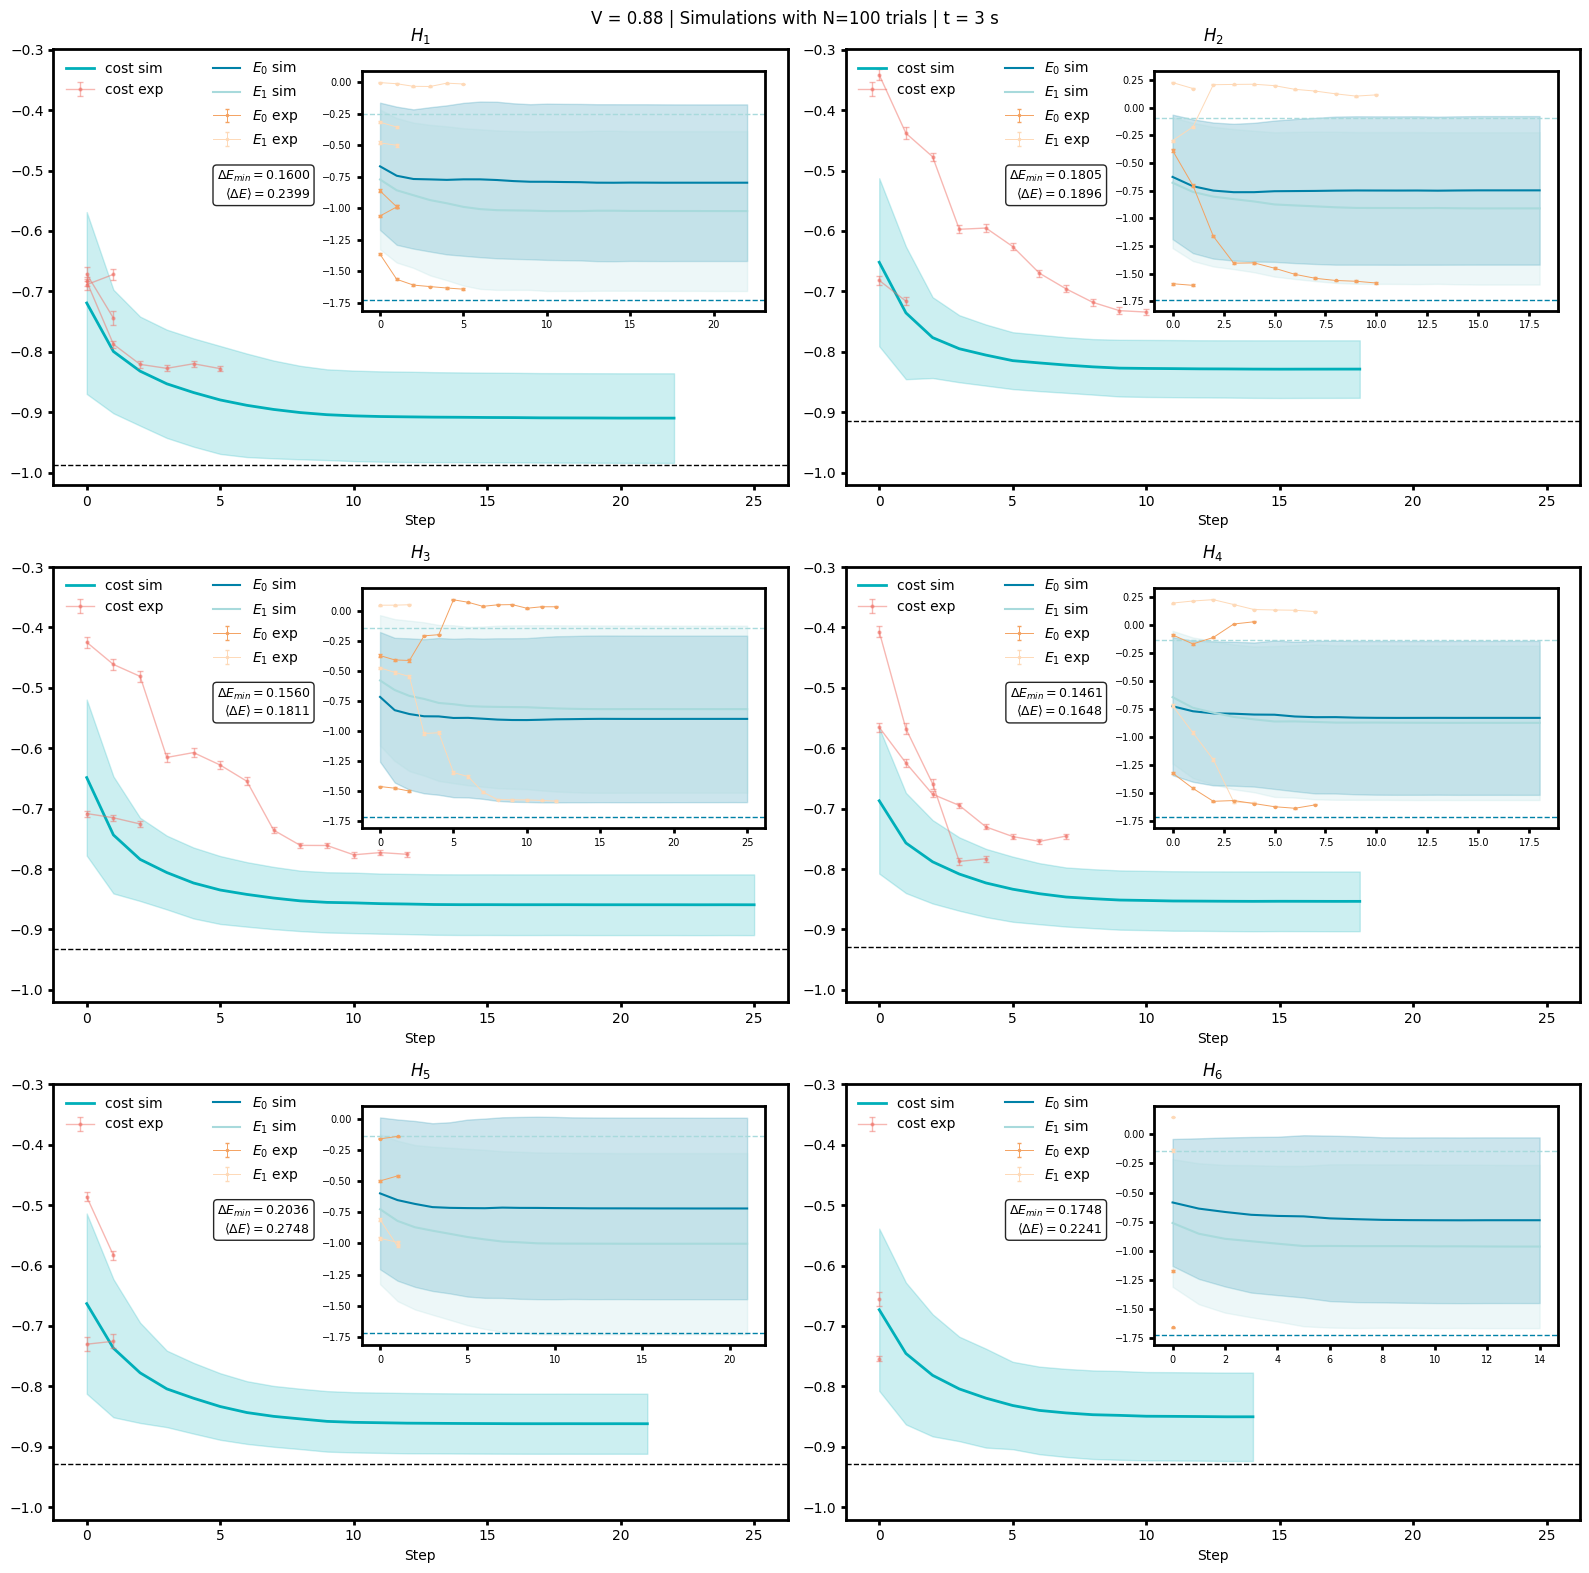

In [118]:
colors = ['#0081A7', '#00AFB9', '#A8DADC', '#FED9B7', '#F4A261', '#F07167']
N_H = 6

c_cost_sim, c_E1_sim, c_E2_sim = colors[1], colors[0], colors[2]
c_cost_exp, c_E1_exp, c_E2_exp = colors[5], colors[4], colors[3]

# ============================================================
# --- Simulation data (mean/std bands) ---
# ============================================================
sim_location = Path('../Simulations/8-mode chip/BFGS_exp=3s/')

sim_cost_by_H = defaultdict(list)
sim_E1_by_H = defaultdict(list)
sim_E2_by_H = defaultdict(list)
sim_true_by_H = {}  # (cost_true, E1_true, E2_true)

for file in sorted(sim_location.glob('trial*.npz')):
    with np.load(file) as data:
        H = int(file.name[16:19][2]) 

        cost = np.array(data['cost'])
        E1 = np.array(data['E1'])
        E2 = np.array(data['E2'])
        energies = np.array(data['energies'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        E1_true, E2_true = energies[0], energies[1]

    sim_cost_by_H[H].append(cost)
    sim_E1_by_H[H].append(E1)
    sim_E2_by_H[H].append(E2)
    sim_true_by_H[H] = (cost_true, E1_true, E2_true)

sim_steps = {}
sim_cost_mean, sim_cost_std = {}, {}
sim_E1_mean, sim_E1_std = {}, {}
sim_E2_mean, sim_E2_std = {}, {}

for H in range(1, N_H + 1):
    cost_pad = pad_and_stack(sim_cost_by_H[H])
    E1_pad = pad_and_stack(sim_E1_by_H[H])
    E2_pad = pad_and_stack(sim_E2_by_H[H])

    sim_steps[H] = np.arange(cost_pad.shape[1])
    sim_cost_mean[H] = np.nanmean(cost_pad, axis=0)
    sim_cost_std[H] = np.nanstd(cost_pad, axis=0)
    sim_E1_mean[H] = np.nanmean(E1_pad, axis=0)
    sim_E1_std[H] = np.nanstd(E1_pad, axis=0)
    sim_E2_mean[H] = np.nanmean(E2_pad, axis=0)
    sim_E2_std[H] = np.nanstd(E2_pad, axis=0)
n_sim = len(sim_cost_by_H[1])

# ============================================================
# --- Experimental data (all runs, grouped by H) ---
# ============================================================
exp_location = Path("../measurements/reorganized_files/BFGS exposure=3")

exp_by_H = defaultdict(list)  # H -> list of dicts (one per run)

for file in sorted(exp_location.glob('*.npz')):
    with np.load(file) as data:
        H = int(file.name[:3][2]) +1
        run = file.name[8]

        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        E1 = np.array(data['E1'])
        E1_e = np.array(data['E1_e'])
        E2 = np.array(data['E2'])
        E2_e = np.array(data['E2_e'])
        calls = np.array(data['calls'])

    exp_by_H[H].append({
        'run': run, 'calls': calls,
        'cost': cost, 'cost_e': cost_e,
        'E1': E1, 'E1_e': E1_e,
        'E2': E2, 'E2_e': E2_e,
    })

# ============================================================
# --- Plot: simulation band + all experimental runs, cost + E1/E2 inset ---
# ============================================================
fig, axs = plt.subplots(3, 2, figsize=(16,16), sharey=True, sharex=True)

final_errors_by_H = defaultdict(list)

for H in range(1, N_H + 1):
    ax = axs[(H - 1) // 2, (H - 1) % 2]
    xs = sim_steps[H]
    cost_true, E1_true, E2_true = sim_true_by_H[H]

    # --- main plot: cost ---
    ax.axhline(y=cost_true, color='k', linewidth=1, ls='--')

    ax.plot(xs, sim_cost_mean[H], color=c_cost_sim, lw=2, label='cost sim')
    ax.fill_between(xs, sim_cost_mean[H] - sim_cost_std[H], sim_cost_mean[H] + sim_cost_std[H],
                     color=c_cost_sim, alpha=0.2)

    for k, run_data in enumerate(exp_by_H[H]):
        run_xs = np.arange(len(run_data['cost']))
        ax.errorbar(run_xs, run_data['cost'], run_data['cost_e'],
                     marker='o', color=c_cost_exp, markersize=2, capsize=2,
                     lw=1, alpha=0.5, label='cost exp' if k == 0 else None)
        # --- final error for this run ---
        final_error = run_data['cost'][-1] - cost_true
        final_errors_by_H[H].append((run_data['run'], final_error))
        
    ax.set_xlabel("Step")
    ax.set_title(f"$H_{H}$")
    ax.legend(loc='upper left', frameon=False)

    # --- box with min/mean final error for this Hamiltonian ---
    errors_this_H =[e for _, e in final_errors_by_H[H]]

    if errors_this_H:
        min_err = min(errors_this_H)
        mean_err = np.mean(errors_this_H)
        textstr = rf"$\Delta E_{{min}} = {min_err:.4f}$" +"\n" + rf"$\langle\Delta E\rangle = {mean_err:.4f}$"
        ax.text(0.35, 0.65, textstr, transform=ax.transAxes,
                fontsize=9, va='bottom', ha='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='k'))
        
    # --- inset: E1 and E2 ---
    inset = ax.inset_axes([0.42, 0.40, 0.55, 0.55])
    inset.axhline(y=E1_true, color=c_E1_sim, linewidth=1, ls='--')
    inset.axhline(y=E2_true, color=c_E2_sim, linewidth=1, ls='--')

    inset.plot(xs, sim_E1_mean[H], color=c_E1_sim, lw=1.5, label='$E_0$ sim')
    inset.fill_between(xs, sim_E1_mean[H] - sim_E1_std[H], sim_E1_mean[H] + sim_E1_std[H],
                        color=c_E1_sim, alpha=0.2)

    inset.plot(xs, sim_E2_mean[H], color=c_E2_sim, lw=1.5, label='$E_1$ sim')
    inset.fill_between(xs, sim_E2_mean[H] - sim_E2_std[H], sim_E2_mean[H] + sim_E2_std[H],
                        color=c_E2_sim, alpha=0.2)

    for k, run_data in enumerate(exp_by_H[H]):
        run_xs = np.arange(len(run_data['E1']))
        inset.errorbar(run_xs, run_data['E1'], run_data['E1_e'],
                        marker='o', color=c_E1_exp, markersize=1.5, capsize=1.5,
                        lw=0.7, alpha=1, label='$E_0$ exp' if k == 0 else None)
        inset.errorbar(run_xs, run_data['E2'], run_data['E2_e'],
                        marker='o', color=c_E2_exp, markersize=1.5, capsize=1.5,
                        lw=0.7, alpha=1, label='$E_1$ exp' if k == 0 else None)

    inset.tick_params(labelsize=7, width=2)
    inset.legend(loc='upper left',
                 bbox_to_anchor=(0.2, 1.005), bbox_transform=ax.transAxes,
                 frameon=False)
    inset.spines[:].set_linewidth(2)

for ax in axs.ravel():
    ax.spines[:].set_linewidth(2)
    ax.tick_params(width=2, labelbottom=True, labelleft=True)
plt.suptitle(f'V = 0.88 | Simulations with N={n_sim} trials | t = 3 s')

plt.tight_layout()
plt.savefig(f'../Figures/BFGS_exp=3s_all_runs.png')
plt.savefig(f'../Figures/BFGS_exp=3s_all_runs.pdf')

# ============================================================
# --- Print final errors for all experimental runs ---
# ============================================================
print("Final errors |cost_final - cost_true| per Hamiltonian and run:")
for H in range(1, N_H + 1):
    for run, err in final_errors_by_H[H]:
        print(f"  H{H} run {run}: {err:.6f}")
    if final_errors_by_H[H]:
        errs = [e for _, e in final_errors_by_H[H]]
        print(f"  -> H{H} min = {min(errs):.6f}, mean = {np.mean(errs):.6f}")

# COBYLA with exposure = 3 s

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_0_run_0.npz
H_0


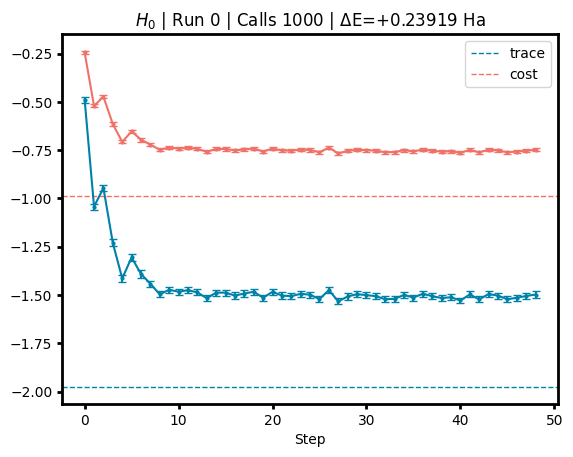

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_0_run_1.npz
H_0


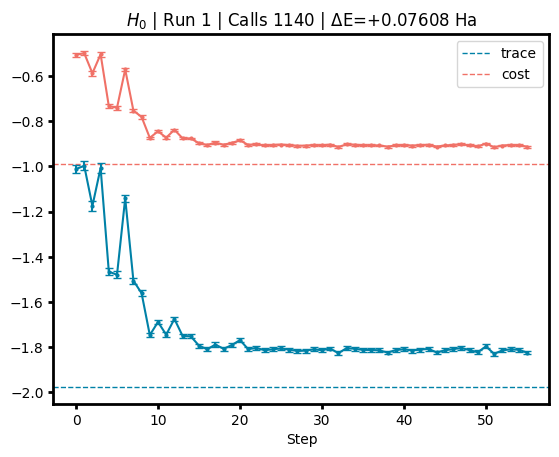

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_0_run_2.npz
H_0


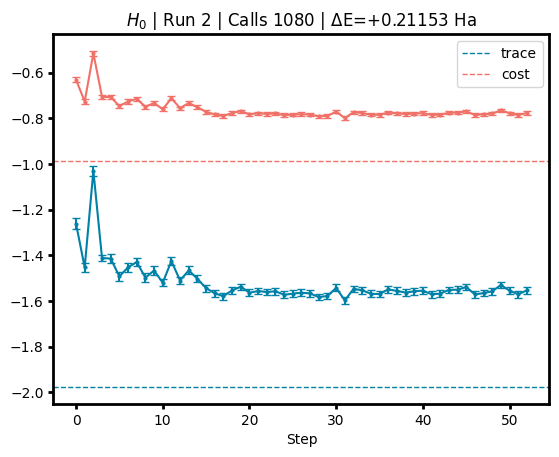

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_1_run_0.npz
H_1


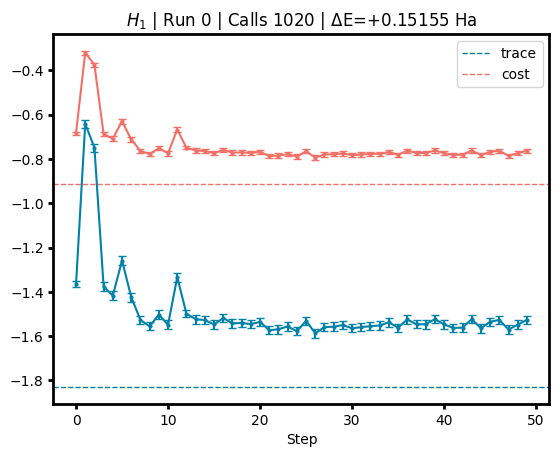

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_1_run_1.npz
H_1


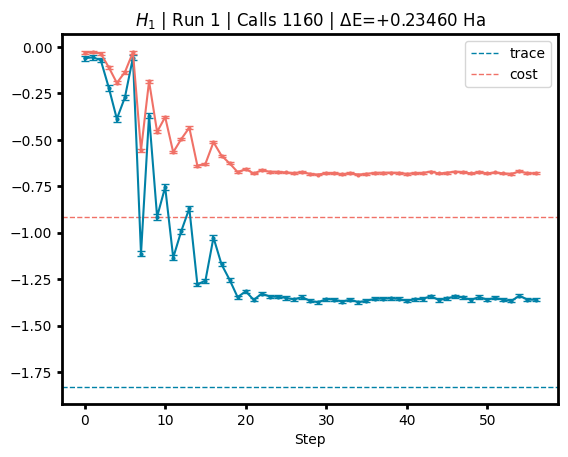

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_1_run_2.npz
H_1


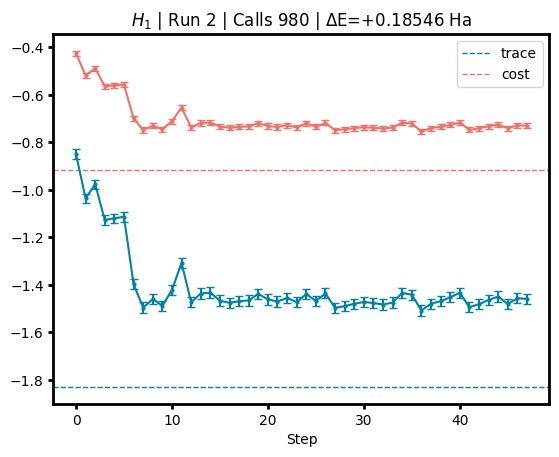

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_2_run_0.npz
H_2


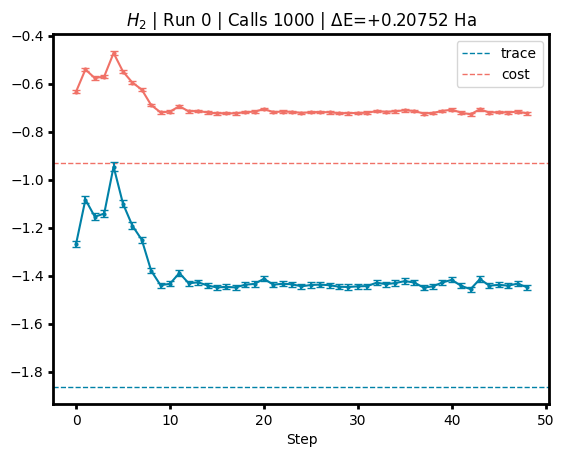

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_2_run_1.npz
H_2


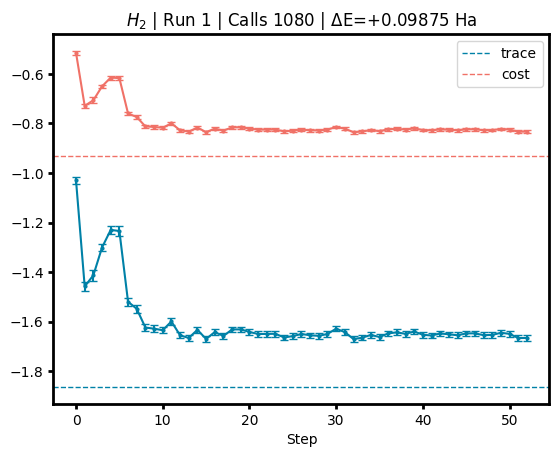

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_2_run_2.npz
H_2


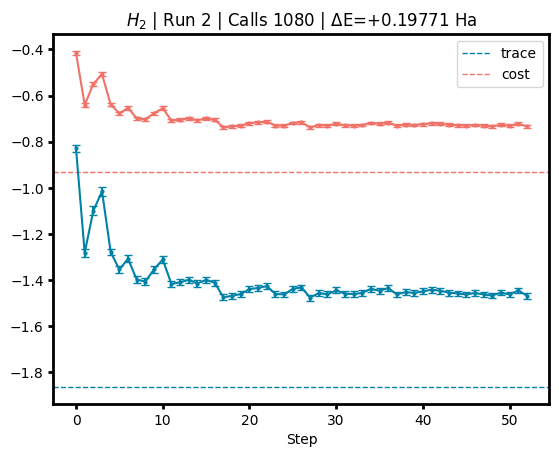

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_3_run_0.npz
H_3


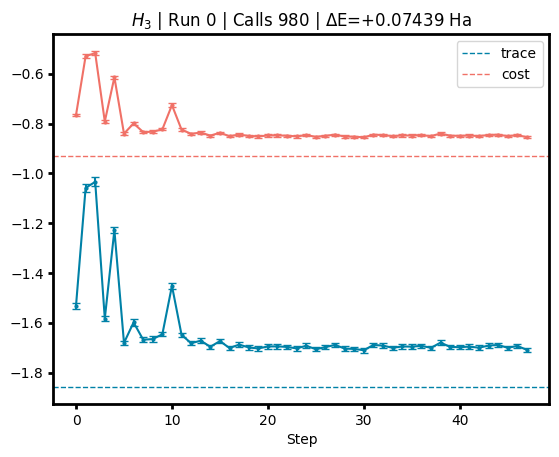

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_3_run_1.npz
H_3


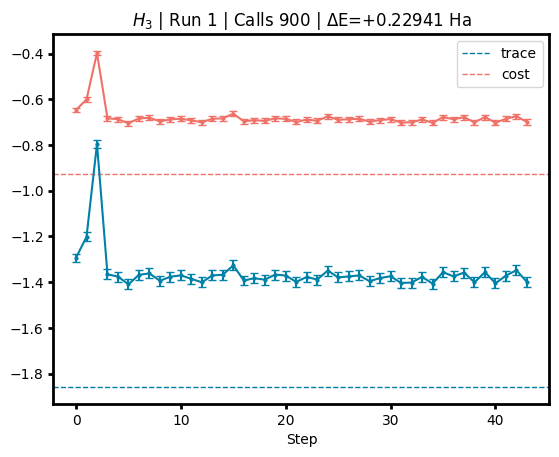

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_4_run_0.npz
H_4


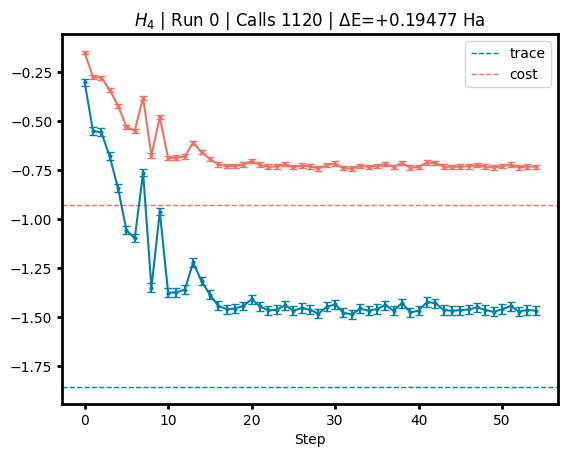

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_4_run_1.npz
H_4


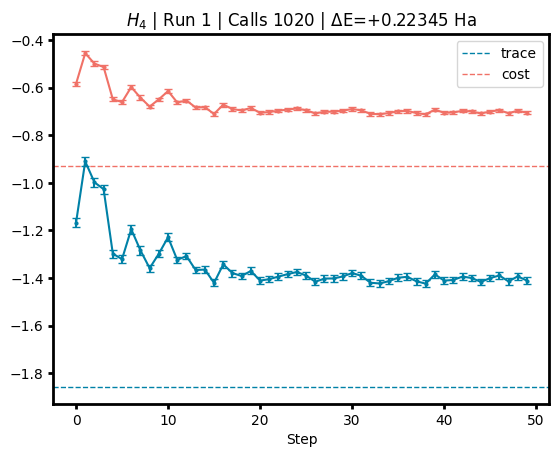

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_5_run_0.npz
H_5


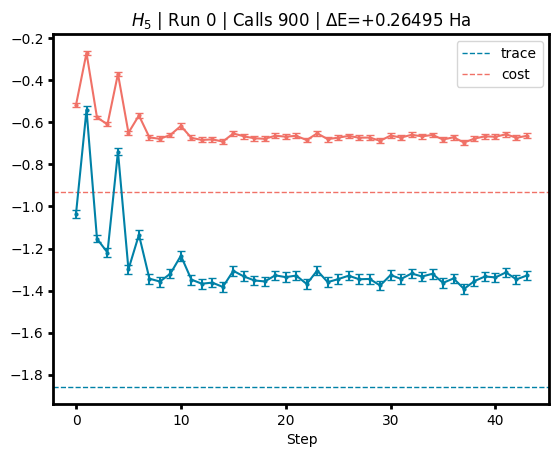

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_5_run_1.npz
H_5


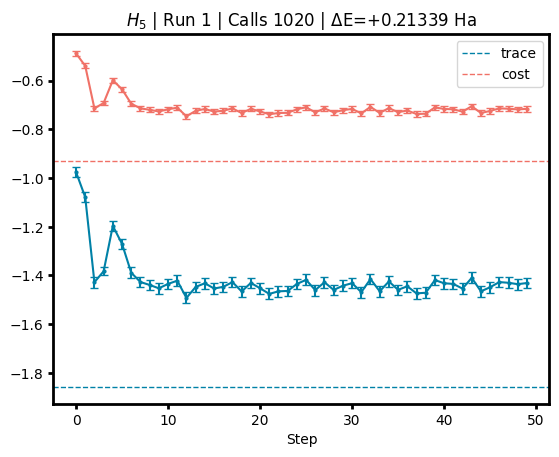

In [44]:
colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

location = Path("../measurements/reorganized_files/COBYLA exposure=3")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        print(H)
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        density = np.array(data['density']).real
        error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[1]
        fig, ax = plt.subplots()
        ax.spines[:].set_linewidth(2)
        ax.tick_params(width=2)
        xs = np.arange(len(cost))
    
        ax.set_xlabel("Step")
        ax.axhline(y=trace_true, color=colors[0], linewidth=1, ls='--',  label='trace')
        ax.axhline(y=cost_true, color=colors[5], linewidth=1, ls='--', label='cost')
        ax.errorbar(xs, trace, trace_e, marker='o', color = colors[0], markersize=2, capsize=3)
        ax.errorbar(xs, cost, cost_e, marker='o', color = colors[5], markersize=2, capsize=3)
        ax.set_title(f"${H}$ | Run {run} | Calls {calls} | ΔE={cost[-1]-cost_true:+.5f} Ha")
        ax.legend()

        plt.show()

Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_0_run_0.npz
H_0
Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_0_run_1.npz
H_0
Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_0_run_2.npz
H_0
Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_1_run_0.npz
H_1
Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_1_run_1.npz
H_1
Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_1_run_2.npz
H_1
Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_2_run_0.npz
H_2
Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_2_run_1.npz
H_2
Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_2_run_2.npz
H_2
Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_3_run_0.npz
H_3
Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_3_run_1.npz
H_3
Loaded file ..\measurements\reorganized_files\COBYLA exposure=3\H_4_run_0.npz
H_4
Loaded file ..\m

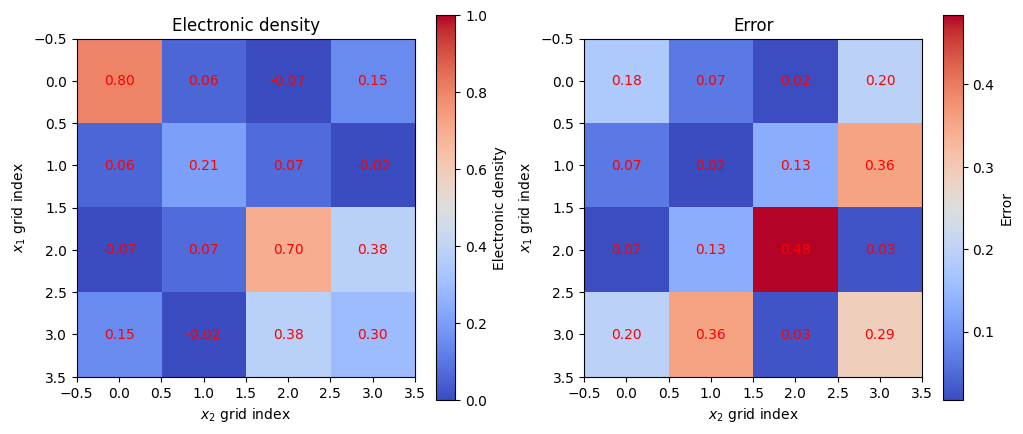

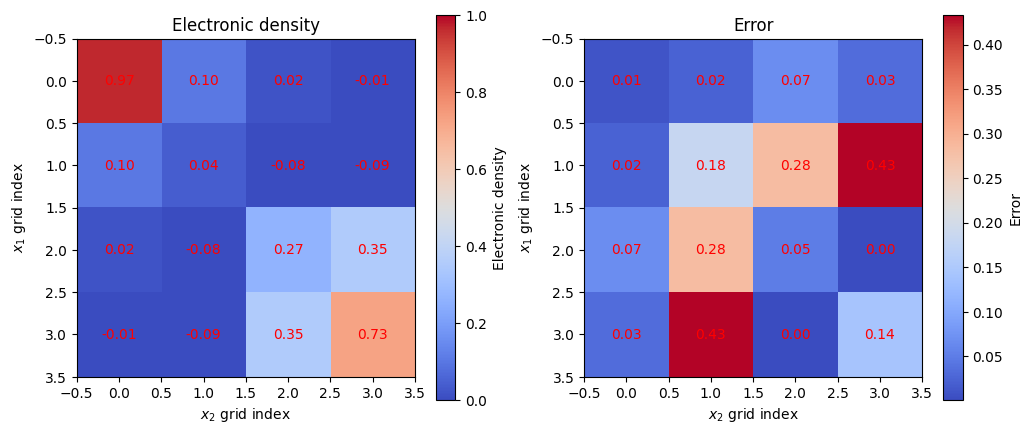

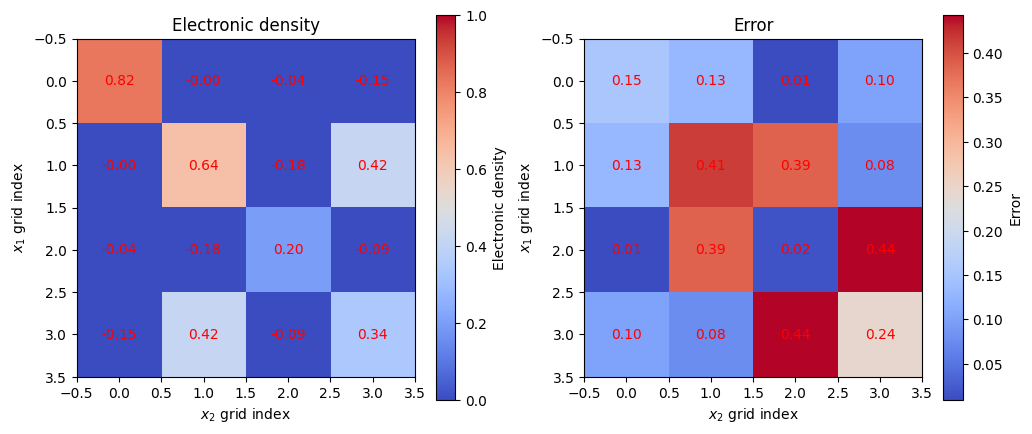

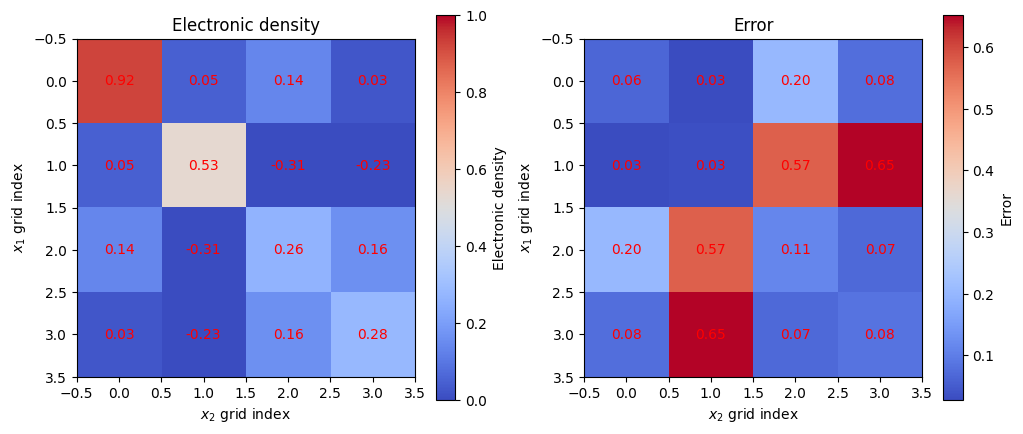

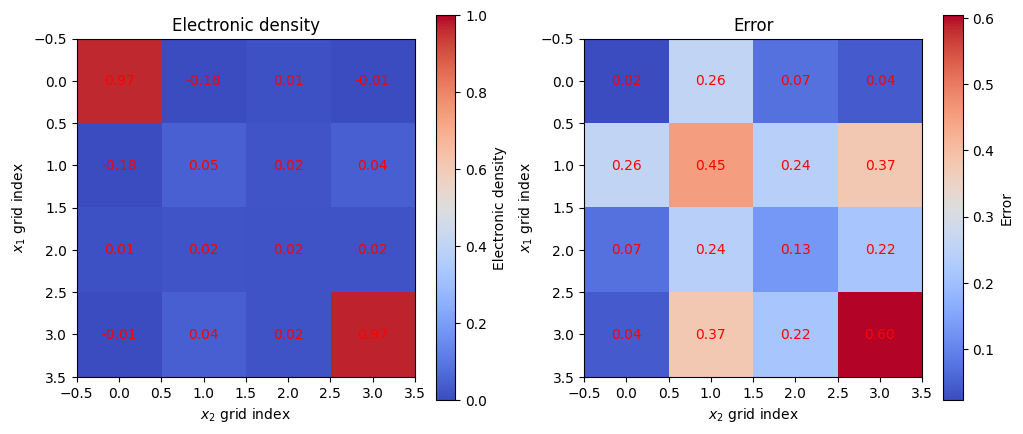

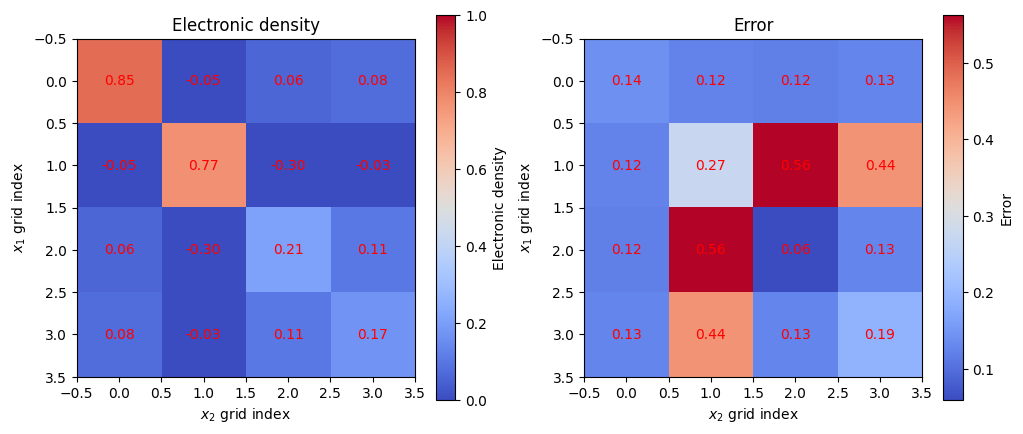

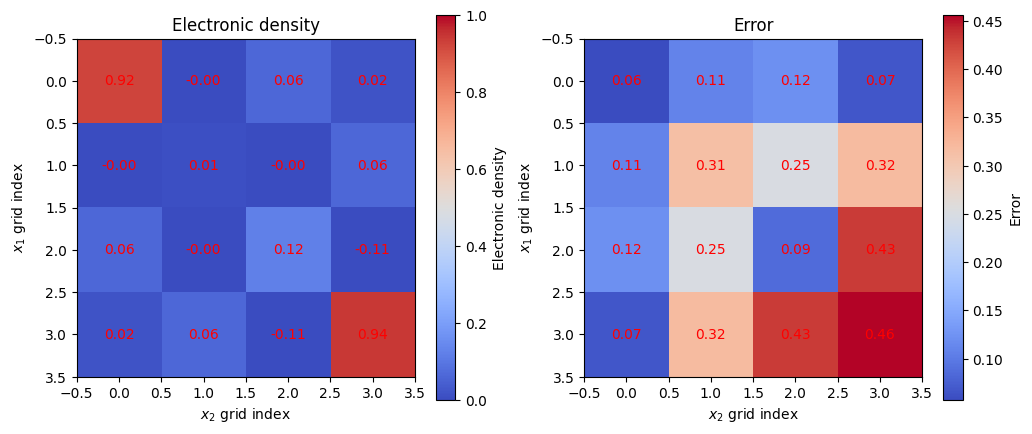

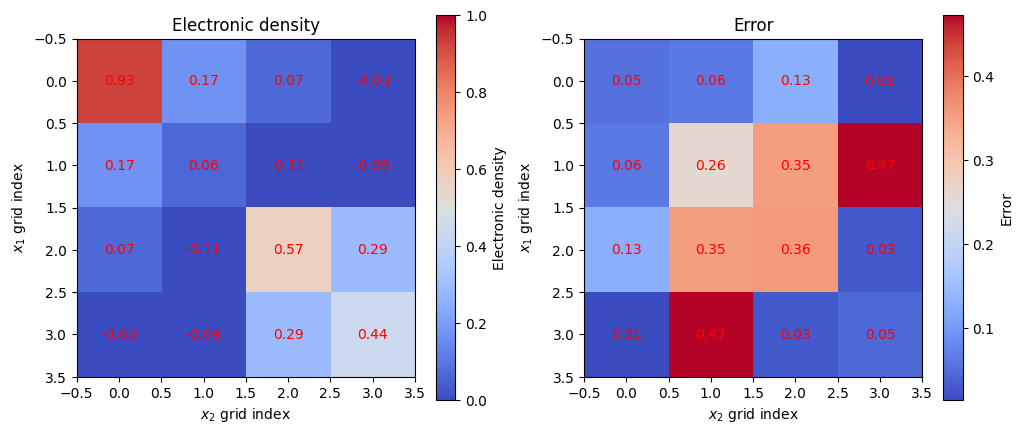

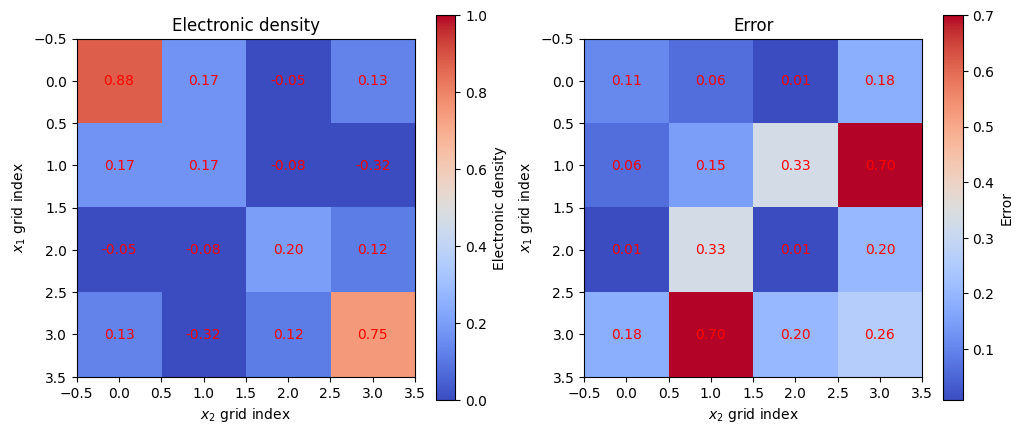

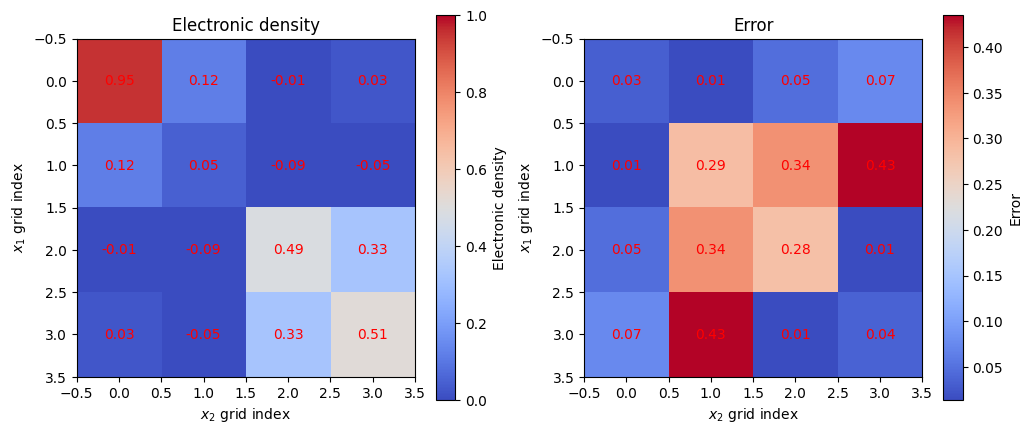

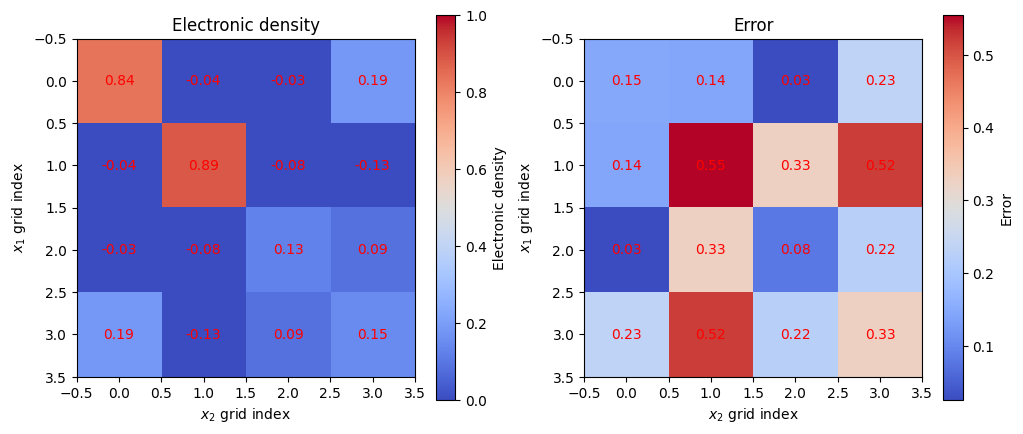

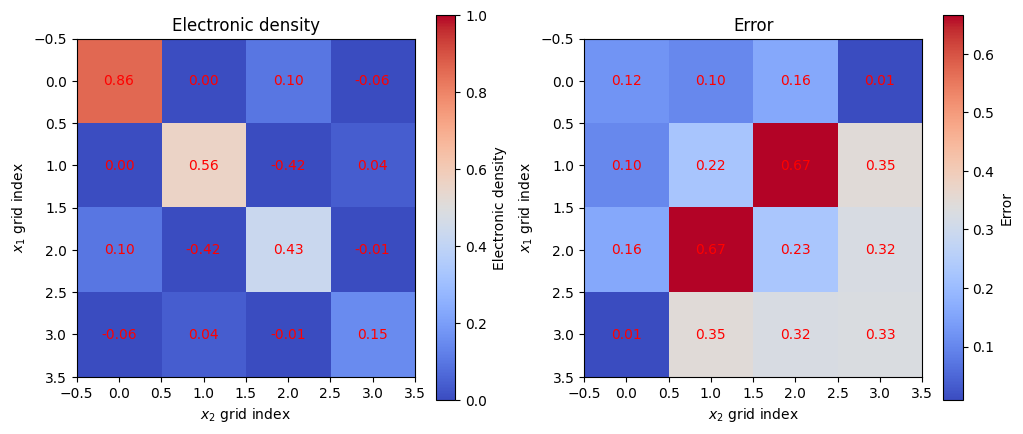

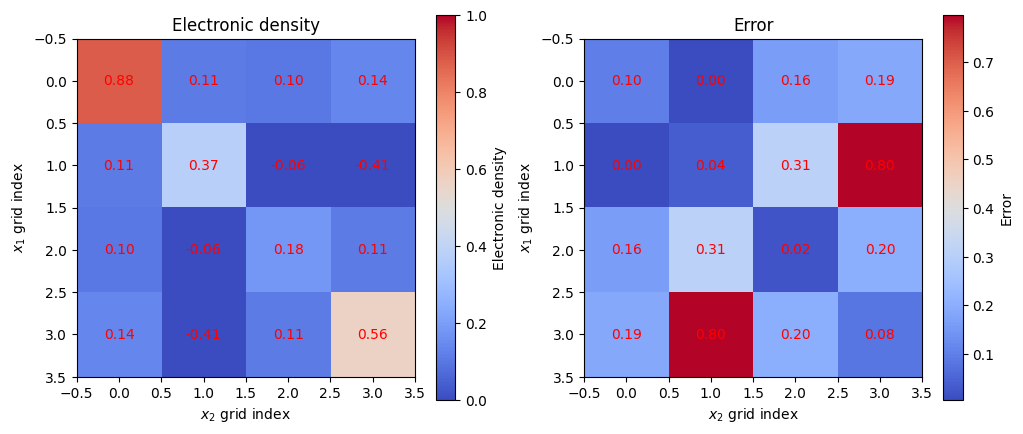

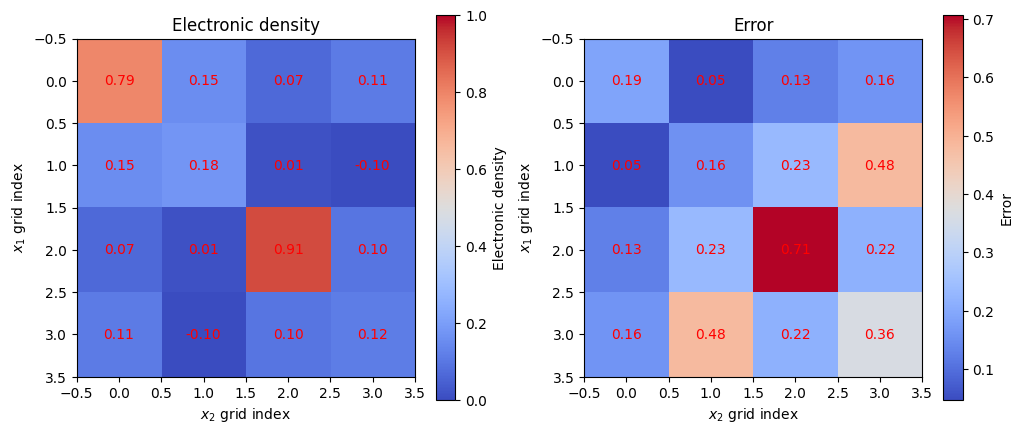

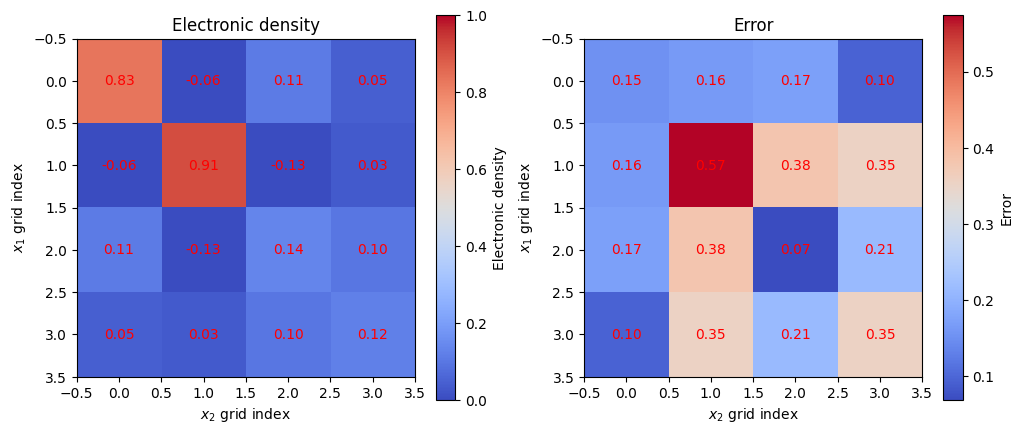

In [36]:
colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

location = Path("../measurements/reorganized_files/COBYLA exposure=3")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        print(H)
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        density = np.array(data['density']).real
        error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[0]
        fig, axs = plt.subplots(1,2, figsize=(12,5))
        im1 = axs[0].imshow(density, cmap='coolwarm', aspect='equal', interpolation='nearest', vmin=0, vmax=1)
        for k in range(density.shape[0]):
            for l in range(density.shape[0]):
                axs[0].text(l, k, f"{density[k, l]:.2f}", ha='center', va='center', color='red')
        axs[0].set_title(f'Electronic density')
        axs[0].set_xlabel(f"$x_2$ grid index")

        im2 = axs[1].imshow(error_D, cmap='coolwarm', aspect='equal', interpolation='nearest')
        for k in range(density.shape[0]):
            for l in range(density.shape[0]):
                axs[1].text(l, k, f"{error_D[k, l]:.2f}", ha='center', va='center', color='red')
        axs[1].set_title(f'Error')
        axs[1].set_xlabel(f"$x_2$ grid index")
    
        fig.colorbar(im1, ax=axs[0], label="Electronic density")
        fig.colorbar(im2, ax=axs[1], label="Error")
        
        axs[0].set_ylabel(f"$x_1$ grid index")
        axs[1].set_ylabel(f"$x_1$ grid index")

## Recap plot

Final errors |cost_final - cost_true| per Hamiltonian and run:
  H1 run 0: 0.239185
  H1 run 1: 0.076084
  H1 run 2: 0.211525
  -> H1 min = 0.076084, mean = 0.175598
  H2 run 0: 0.151551
  H2 run 1: 0.234604
  H2 run 2: 0.185456
  -> H2 min = 0.151551, mean = 0.190537
  H3 run 0: 0.207523
  H3 run 1: 0.098751
  H3 run 2: 0.197714
  -> H3 min = 0.098751, mean = 0.167996
  H4 run 0: 0.074385
  H4 run 1: 0.229414
  -> H4 min = 0.074385, mean = 0.151900
  H5 run 0: 0.194766
  H5 run 1: 0.223451
  -> H5 min = 0.194766, mean = 0.209109
  H6 run 0: 0.264949
  H6 run 1: 0.213392
  -> H6 min = 0.213392, mean = 0.239170


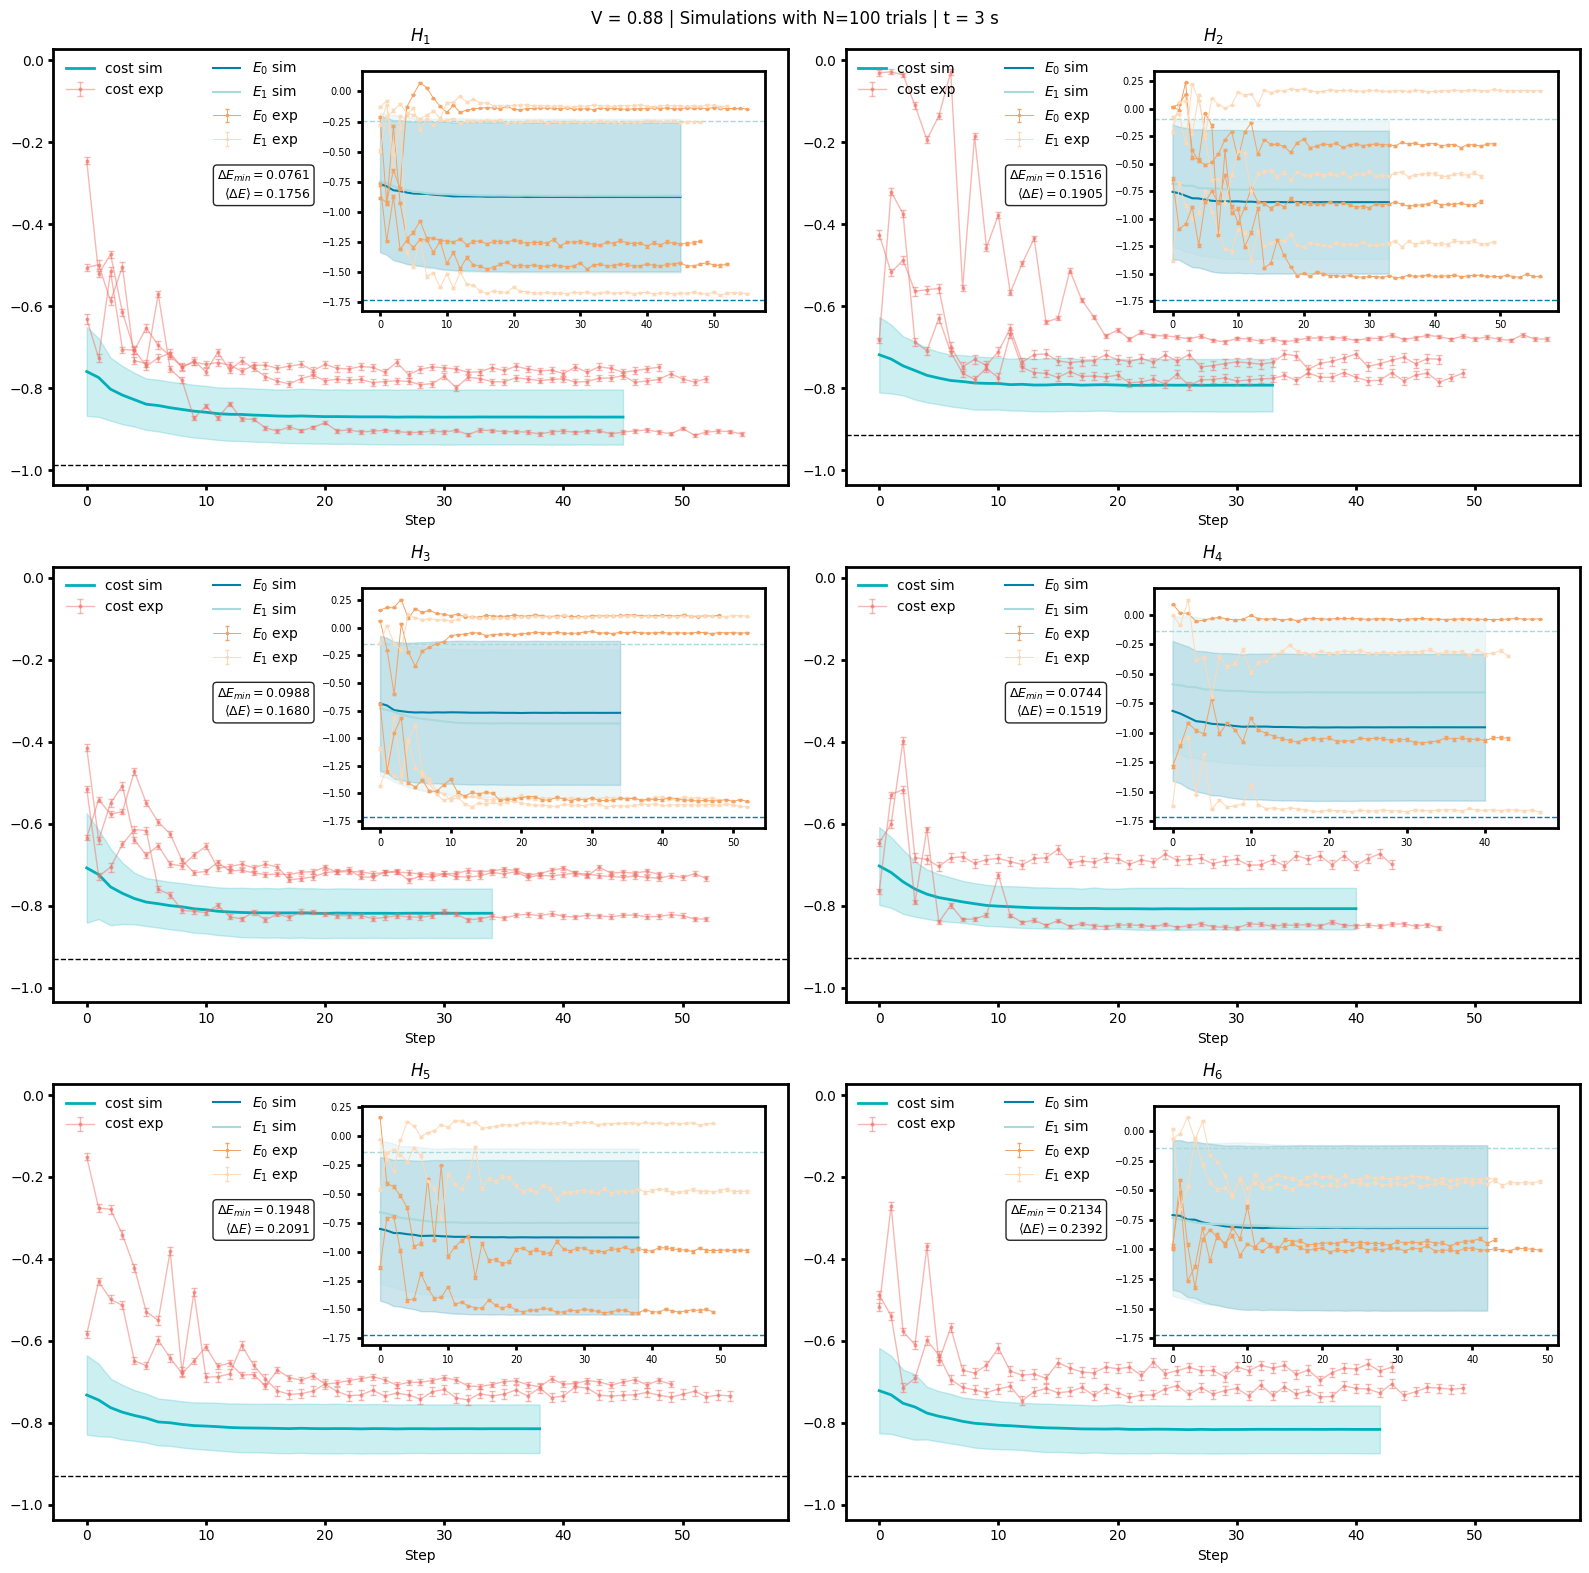

In [119]:
colors = ['#0081A7', '#00AFB9', '#A8DADC', '#FED9B7', '#F4A261', '#F07167']
N_H = 6

c_cost_sim, c_E1_sim, c_E2_sim = colors[1], colors[0], colors[2]
c_cost_exp, c_E1_exp, c_E2_exp = colors[5], colors[4], colors[3]

# ============================================================
# --- Simulation data (mean/std bands) ---
# ============================================================
sim_location = Path('../Simulations/8-mode chip/COBYLA_exp=3s/')

sim_cost_by_H = defaultdict(list)
sim_E1_by_H = defaultdict(list)
sim_E2_by_H = defaultdict(list)
sim_true_by_H = {}  # (cost_true, E1_true, E2_true)

for file in sorted(sim_location.glob('trial*.npz')):
    with np.load(file) as data:
        H = int(file.name[16:19][2]) 

        cost = np.array(data['cost'])
        E1 = np.array(data['E1'])
        E2 = np.array(data['E2'])
        energies = np.array(data['energies'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        E1_true, E2_true = energies[0], energies[1]

    sim_cost_by_H[H].append(cost)
    sim_E1_by_H[H].append(E1)
    sim_E2_by_H[H].append(E2)
    sim_true_by_H[H] = (cost_true, E1_true, E2_true)

sim_steps = {}
sim_cost_mean, sim_cost_std = {}, {}
sim_E1_mean, sim_E1_std = {}, {}
sim_E2_mean, sim_E2_std = {}, {}

for H in range(1, N_H + 1):
    cost_pad = pad_and_stack(sim_cost_by_H[H])
    E1_pad = pad_and_stack(sim_E1_by_H[H])
    E2_pad = pad_and_stack(sim_E2_by_H[H])

    sim_steps[H] = np.arange(cost_pad.shape[1])
    sim_cost_mean[H] = np.nanmean(cost_pad, axis=0)
    sim_cost_std[H] = np.nanstd(cost_pad, axis=0)
    sim_E1_mean[H] = np.nanmean(E1_pad, axis=0)
    sim_E1_std[H] = np.nanstd(E1_pad, axis=0)
    sim_E2_mean[H] = np.nanmean(E2_pad, axis=0)
    sim_E2_std[H] = np.nanstd(E2_pad, axis=0)
n_sim = len(sim_cost_by_H[1])

# ============================================================
# --- Experimental data (all runs, grouped by H) ---
# ============================================================
exp_location = Path("../measurements/reorganized_files/COBYLA exposure=3")

exp_by_H = defaultdict(list)  # H -> list of dicts (one per run)

for file in sorted(exp_location.glob('*.npz')):
    with np.load(file) as data:
        H = int(file.name[:3][2]) +1
        run = file.name[8]

        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        E1 = np.array(data['E1'])
        E1_e = np.array(data['E1_e'])
        E2 = np.array(data['E2'])
        E2_e = np.array(data['E2_e'])
        calls = np.array(data['calls'])

    exp_by_H[H].append({
        'run': run, 'calls': calls,
        'cost': cost, 'cost_e': cost_e,
        'E1': E1, 'E1_e': E1_e,
        'E2': E2, 'E2_e': E2_e,
    })

# ============================================================
# --- Plot: simulation band + all experimental runs, cost + E1/E2 inset ---
# ============================================================
fig, axs = plt.subplots(3, 2, figsize=(16,16), sharey=True, sharex=True)

final_errors_by_H = defaultdict(list)

for H in range(1, N_H + 1):
    ax = axs[(H - 1) // 2, (H - 1) % 2]
    xs = sim_steps[H]
    cost_true, E1_true, E2_true = sim_true_by_H[H]

    # --- main plot: cost ---
    ax.axhline(y=cost_true, color='k', linewidth=1, ls='--')

    ax.plot(xs, sim_cost_mean[H], color=c_cost_sim, lw=2, label='cost sim')
    ax.fill_between(xs, sim_cost_mean[H] - sim_cost_std[H], sim_cost_mean[H] + sim_cost_std[H],
                     color=c_cost_sim, alpha=0.2)

    for k, run_data in enumerate(exp_by_H[H]):
        run_xs = np.arange(len(run_data['cost']))
        ax.errorbar(run_xs, run_data['cost'], run_data['cost_e'],
                     marker='o', color=c_cost_exp, markersize=2, capsize=2,
                     lw=1, alpha=0.5, label='cost exp' if k == 0 else None)
        # --- final error for this run ---
        final_error = run_data['cost'][-1] - cost_true
        final_errors_by_H[H].append((run_data['run'], final_error))
        
    ax.set_xlabel("Step")
    ax.set_title(f"$H_{H}$")
    ax.legend(loc='upper left', frameon=False)

    # --- box with min/mean final error for this Hamiltonian ---
    errors_this_H =[e for _, e in final_errors_by_H[H]]

    if errors_this_H:
        min_err = min(errors_this_H)
        mean_err = np.mean(errors_this_H)
        textstr = rf"$\Delta E_{{min}} = {min_err:.4f}$" +"\n" + rf"$\langle\Delta E\rangle = {mean_err:.4f}$"
        ax.text(0.35, 0.65, textstr, transform=ax.transAxes,
                fontsize=9, va='bottom', ha='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='k'))
        
    # --- inset: E1 and E2 ---
    inset = ax.inset_axes([0.42, 0.40, 0.55, 0.55])
    inset.axhline(y=E1_true, color=c_E1_sim, linewidth=1, ls='--')
    inset.axhline(y=E2_true, color=c_E2_sim, linewidth=1, ls='--')

    inset.plot(xs, sim_E1_mean[H], color=c_E1_sim, lw=1.5, label='$E_0$ sim')
    inset.fill_between(xs, sim_E1_mean[H] - sim_E1_std[H], sim_E1_mean[H] + sim_E1_std[H],
                        color=c_E1_sim, alpha=0.2)

    inset.plot(xs, sim_E2_mean[H], color=c_E2_sim, lw=1.5, label='$E_1$ sim')
    inset.fill_between(xs, sim_E2_mean[H] - sim_E2_std[H], sim_E2_mean[H] + sim_E2_std[H],
                        color=c_E2_sim, alpha=0.2)

    for k, run_data in enumerate(exp_by_H[H]):
        run_xs = np.arange(len(run_data['E1']))
        inset.errorbar(run_xs, run_data['E1'], run_data['E1_e'],
                        marker='o', color=c_E1_exp, markersize=1.5, capsize=1.5,
                        lw=0.7, alpha=1, label='$E_0$ exp' if k == 0 else None)
        inset.errorbar(run_xs, run_data['E2'], run_data['E2_e'],
                        marker='o', color=c_E2_exp, markersize=1.5, capsize=1.5,
                        lw=0.7, alpha=1, label='$E_1$ exp' if k == 0 else None)

    inset.tick_params(labelsize=7, width=2)
    inset.legend(loc='upper left',
                 bbox_to_anchor=(0.2, 1.005), bbox_transform=ax.transAxes,
                 frameon=False)
    inset.spines[:].set_linewidth(2)

for ax in axs.ravel():
    ax.spines[:].set_linewidth(2)
    ax.tick_params(width=2, labelbottom=True, labelleft=True)
plt.suptitle(f'V = 0.88 | Simulations with N={n_sim} trials | t = 3 s')

plt.tight_layout()
plt.savefig(f'../Figures/COBYLA_exp=3s_all_runs.png')
plt.savefig(f'../Figures/COBYLA_exp=3s_all_runs.pdf')

# ============================================================
# --- Print final errors for all experimental runs ---
# ============================================================
print("Final errors |cost_final - cost_true| per Hamiltonian and run:")
for H in range(1, N_H + 1):
    for run, err in final_errors_by_H[H]:
        print(f"  H{H} run {run}: {err:.6f}")
    if final_errors_by_H[H]:
        errs = [e for _, e in final_errors_by_H[H]]
        print(f"  -> H{H} min = {min(errs):.6f}, mean = {np.mean(errs):.6f}")

# COBYLA with exposure = 6 s

Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_0_run_0.npz
H_0


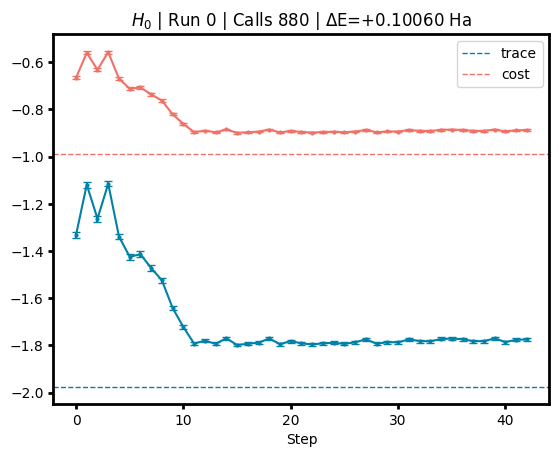

Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_0_run_1.npz
H_0


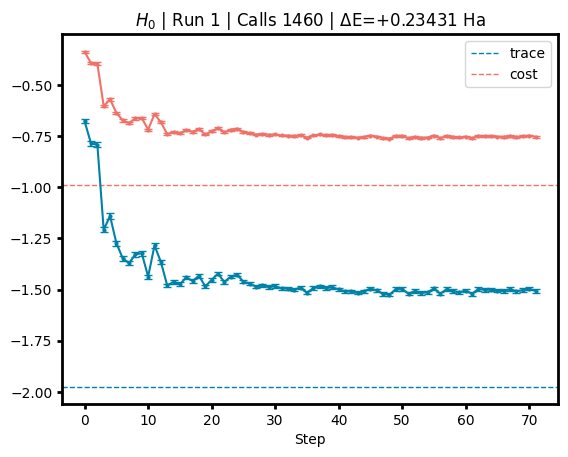

Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_1_run_0.npz
H_1


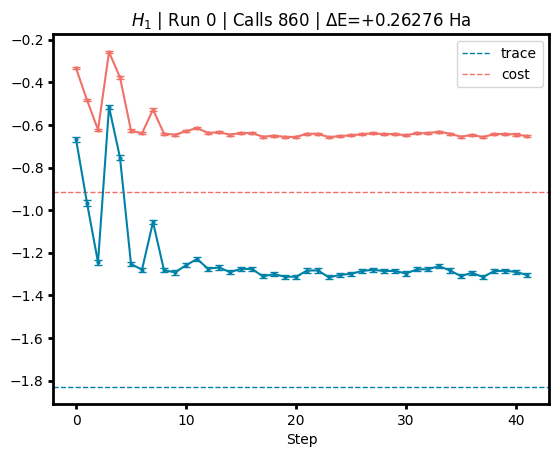

Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_2_run_0.npz
H_2


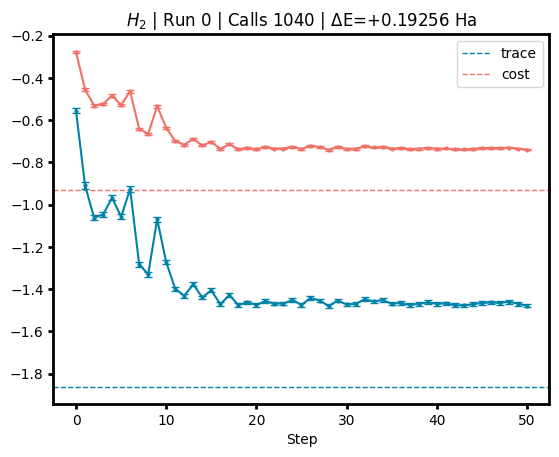

Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_3_run_0.npz
H_3


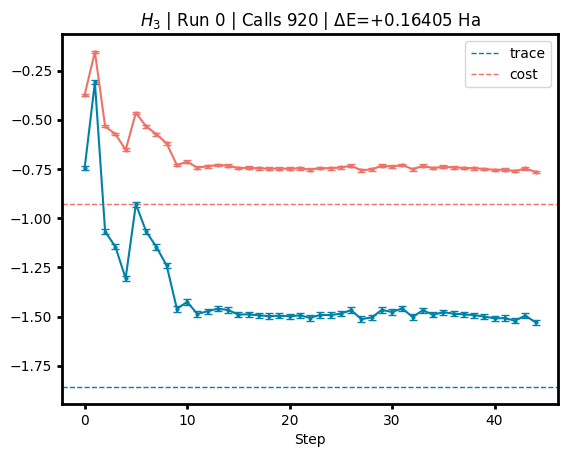

Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_4_run_0.npz
H_4


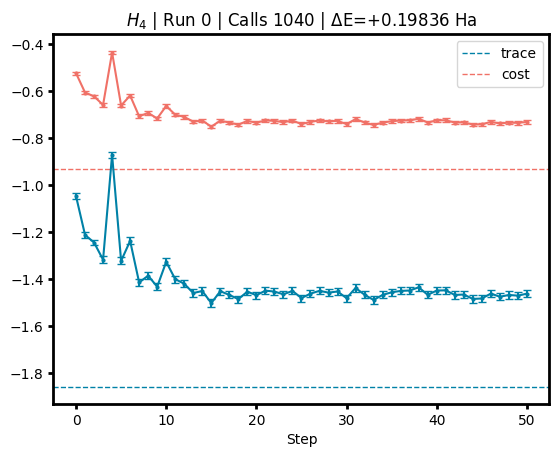

Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_5_run_0.npz
H_5


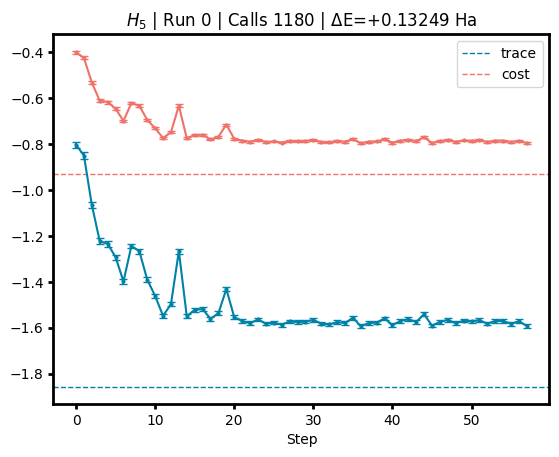

In [38]:
colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

location = Path("../measurements/reorganized_files/COBYLA exposure=6")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        print(H)
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        density = np.array(data['density']).real
        error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[1]
        fig, ax = plt.subplots()
        ax.spines[:].set_linewidth(2)
        ax.tick_params(width=2)
        xs = np.arange(len(cost))
    
        ax.set_xlabel("Step")
        ax.axhline(y=trace_true, color=colors[0], linewidth=1, ls='--',  label='trace')
        ax.axhline(y=cost_true, color=colors[5], linewidth=1, ls='--', label='cost')
        ax.errorbar(xs, trace, trace_e, marker='o', color = colors[0], markersize=2, capsize=3)
        ax.errorbar(xs, cost, cost_e, marker='o', color = colors[5], markersize=2, capsize=3)
        ax.set_title(f"${H}$ | Run {run} | Calls {calls} | ΔE={cost[-1]-cost_true:+.5f} Ha")
        ax.legend()

        plt.show()

Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_0_run_0.npz
H_0
Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_0_run_1.npz
H_0
Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_1_run_0.npz
H_1
Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_2_run_0.npz
H_2
Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_3_run_0.npz
H_3
Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_4_run_0.npz
H_4
Loaded file ..\measurements\reorganized_files\COBYLA exposure=6\H_5_run_0.npz
H_5


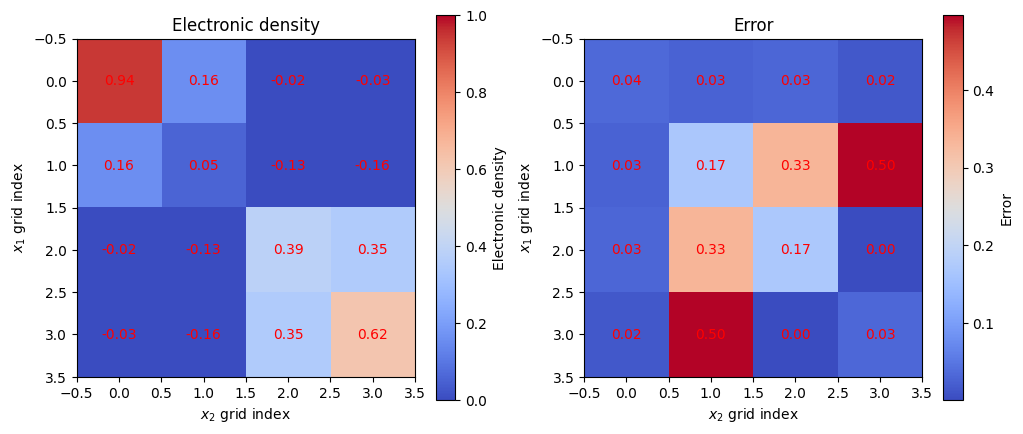

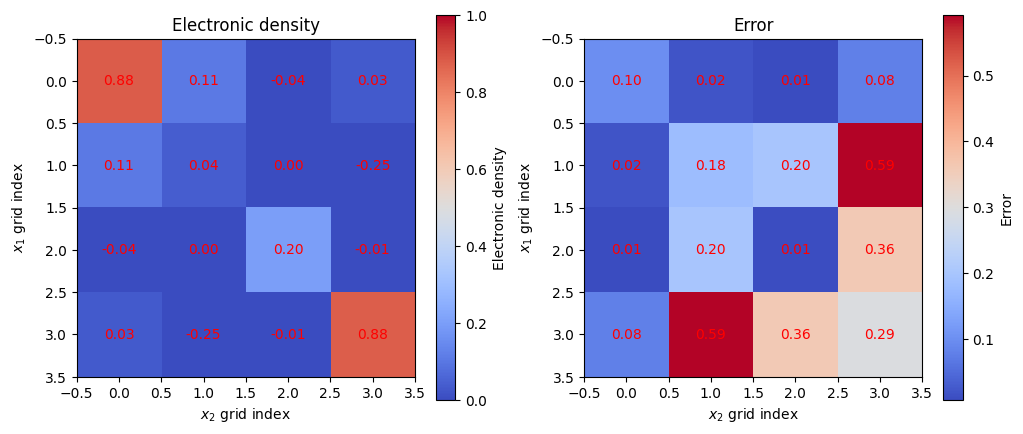

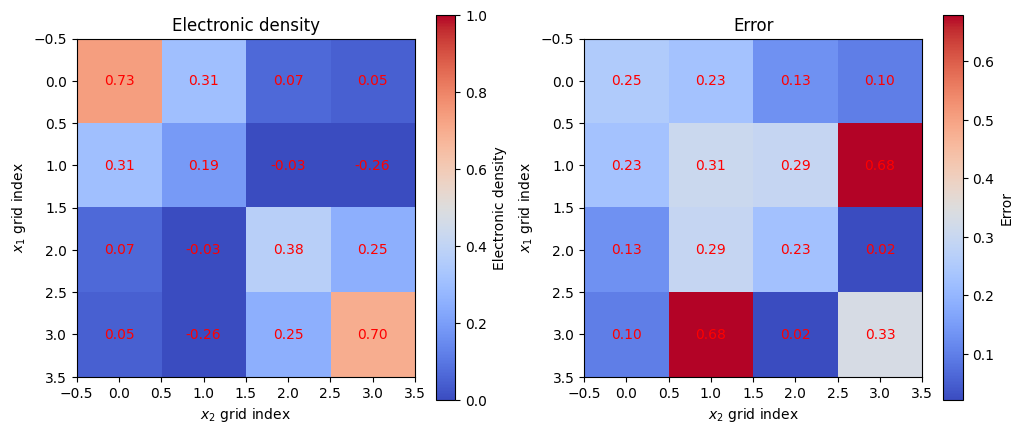

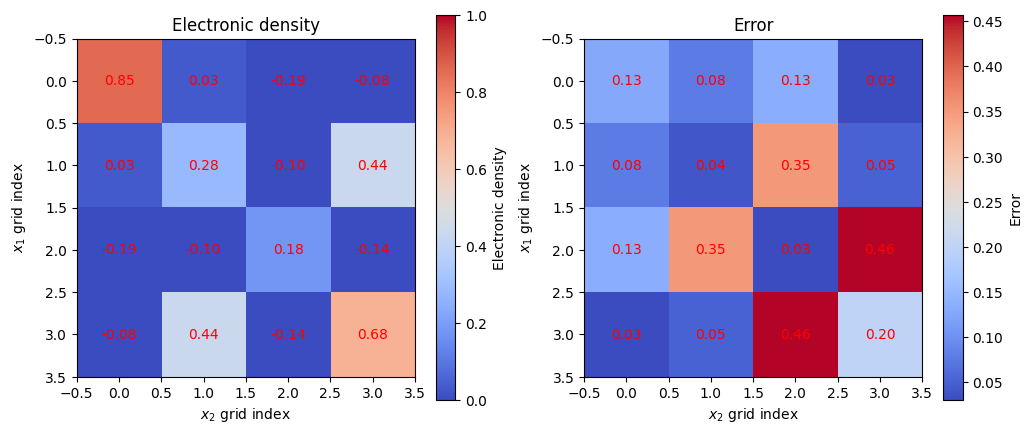

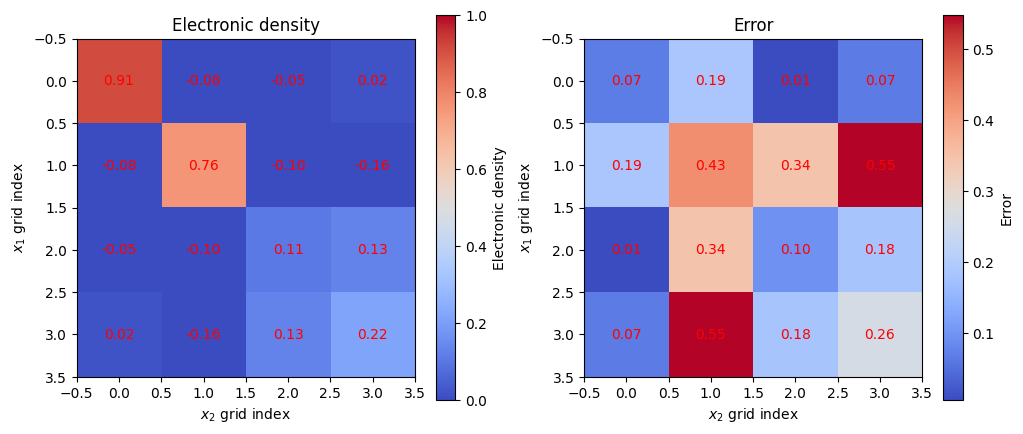

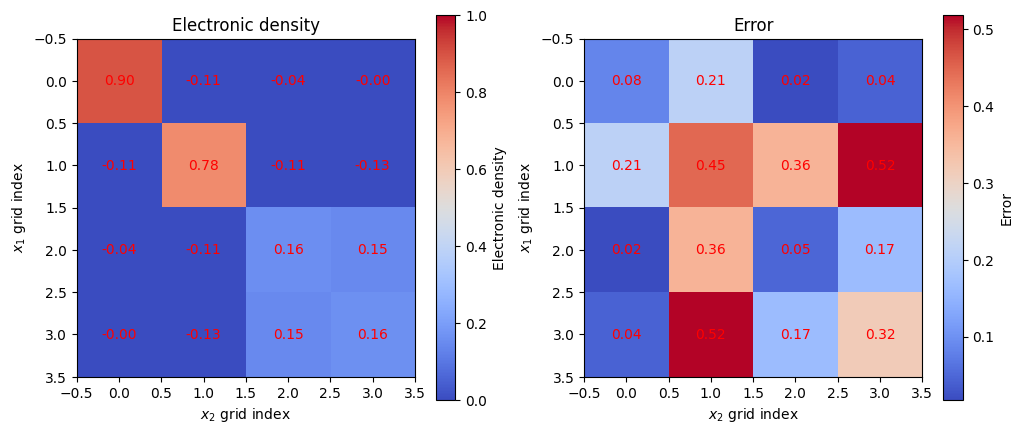

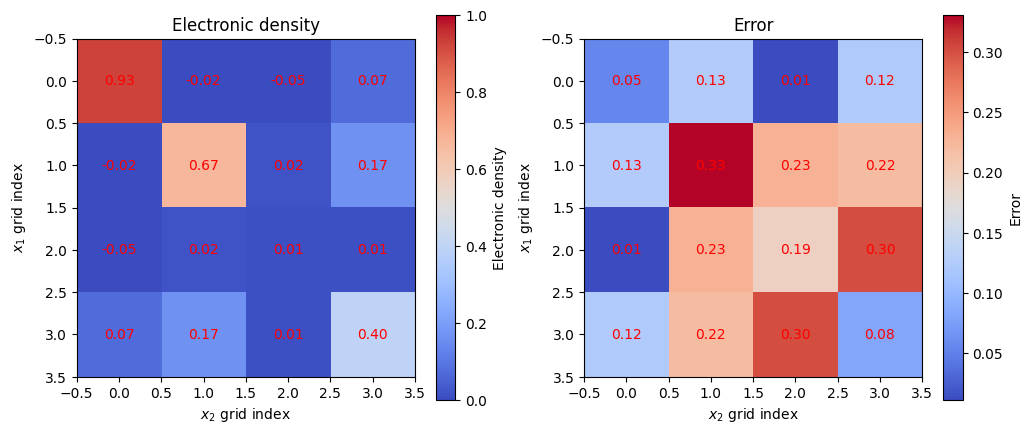

In [39]:
colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

location = Path("../measurements/reorganized_files/COBYLA exposure=6")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        print(H)
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        density = np.array(data['density']).real
        error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[0]
        fig, axs = plt.subplots(1,2, figsize=(12,5))
        im1 = axs[0].imshow(density, cmap='coolwarm', aspect='equal', interpolation='nearest', vmin=0, vmax=1)
        for k in range(density.shape[0]):
            for l in range(density.shape[0]):
                axs[0].text(l, k, f"{density[k, l]:.2f}", ha='center', va='center', color='red')
        axs[0].set_title(f'Electronic density')
        axs[0].set_xlabel(f"$x_2$ grid index")

        im2 = axs[1].imshow(error_D, cmap='coolwarm', aspect='equal', interpolation='nearest')
        for k in range(density.shape[0]):
            for l in range(density.shape[0]):
                axs[1].text(l, k, f"{error_D[k, l]:.2f}", ha='center', va='center', color='red')
        axs[1].set_title(f'Error')
        axs[1].set_xlabel(f"$x_2$ grid index")
    
        fig.colorbar(im1, ax=axs[0], label="Electronic density")
        fig.colorbar(im2, ax=axs[1], label="Error")
        
        axs[0].set_ylabel(f"$x_1$ grid index")
        axs[1].set_ylabel(f"$x_1$ grid index")

## Recap plot

Final errors |cost_final - cost_true| per Hamiltonian and run:
  H1 run 0: 0.100599
  H1 run 1: 0.234310
  -> H1 min = 0.100599, mean = 0.167454
  H2 run 0: 0.262758
  -> H2 min = 0.262758, mean = 0.262758
  H3 run 0: 0.192556
  -> H3 min = 0.192556, mean = 0.192556
  H4 run 0: 0.164045
  -> H4 min = 0.164045, mean = 0.164045
  H5 run 0: 0.198359
  -> H5 min = 0.198359, mean = 0.198359
  H6 run 0: 0.132490
  -> H6 min = 0.132490, mean = 0.132490


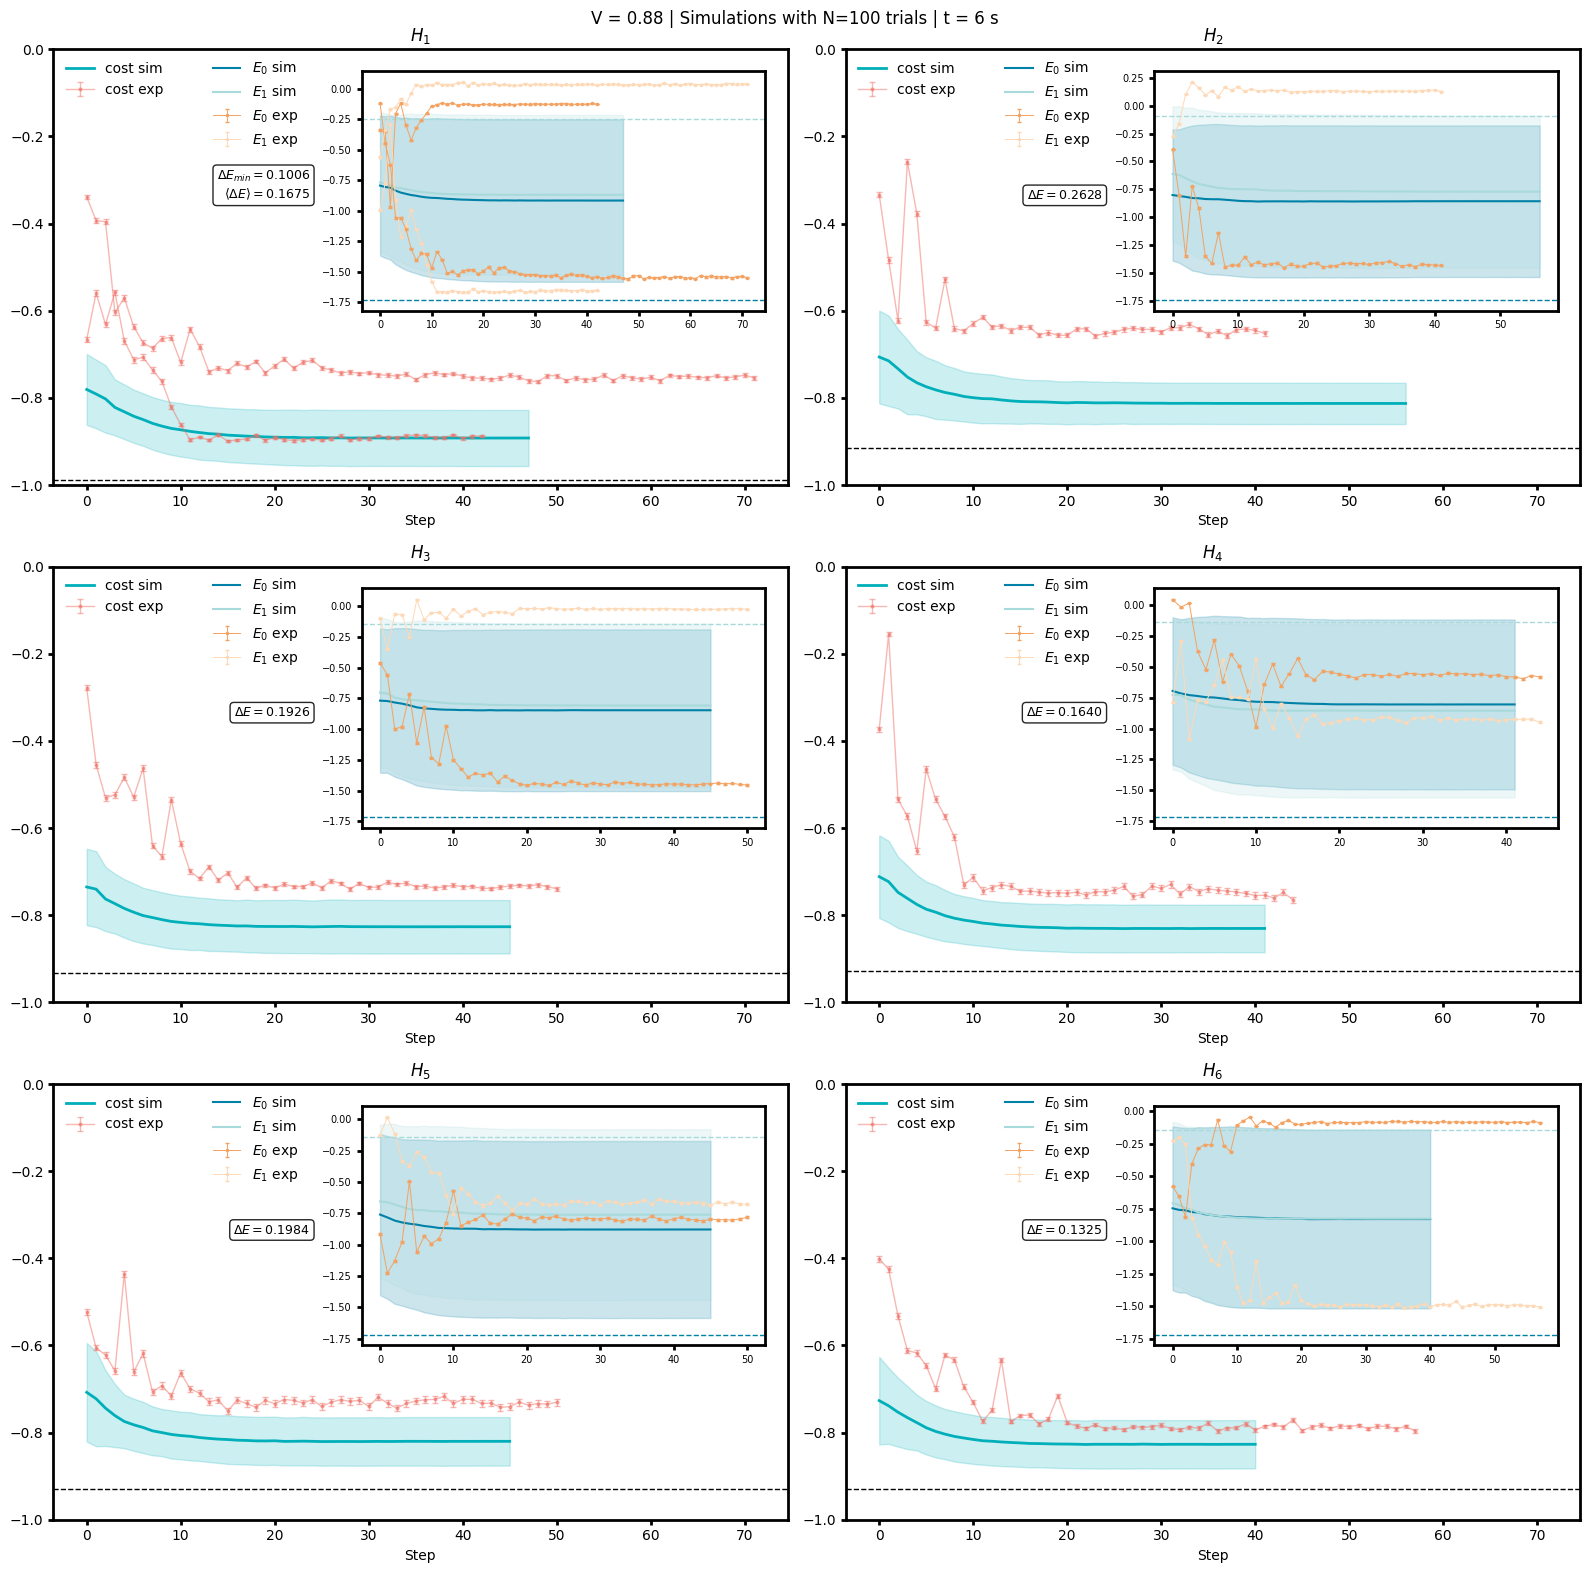

In [120]:
colors = ['#0081A7', '#00AFB9', '#A8DADC', '#FED9B7', '#F4A261', '#F07167']
N_H = 6

c_cost_sim, c_E1_sim, c_E2_sim = colors[1], colors[0], colors[2]
c_cost_exp, c_E1_exp, c_E2_exp = colors[5], colors[4], colors[3]

# ============================================================
# --- Simulation data (mean/std bands) ---
# ============================================================
sim_location = Path('../Simulations/8-mode chip/COBYLA_exp=6s/')

sim_cost_by_H = defaultdict(list)
sim_E1_by_H = defaultdict(list)
sim_E2_by_H = defaultdict(list)
sim_true_by_H = {}  # (cost_true, E1_true, E2_true)

for file in sorted(sim_location.glob('trial*.npz')):
    with np.load(file) as data:
        H = int(file.name[16:19][2]) 

        cost = np.array(data['cost'])
        E1 = np.array(data['E1'])
        E2 = np.array(data['E2'])
        energies = np.array(data['energies'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        E1_true, E2_true = energies[0], energies[1]

    sim_cost_by_H[H].append(cost)
    sim_E1_by_H[H].append(E1)
    sim_E2_by_H[H].append(E2)
    sim_true_by_H[H] = (cost_true, E1_true, E2_true)

sim_steps = {}
sim_cost_mean, sim_cost_std = {}, {}
sim_E1_mean, sim_E1_std = {}, {}
sim_E2_mean, sim_E2_std = {}, {}

for H in range(1, N_H + 1):
    cost_pad = pad_and_stack(sim_cost_by_H[H])
    E1_pad = pad_and_stack(sim_E1_by_H[H])
    E2_pad = pad_and_stack(sim_E2_by_H[H])

    sim_steps[H] = np.arange(cost_pad.shape[1])
    sim_cost_mean[H] = np.nanmean(cost_pad, axis=0)
    sim_cost_std[H] = np.nanstd(cost_pad, axis=0)
    sim_E1_mean[H] = np.nanmean(E1_pad, axis=0)
    sim_E1_std[H] = np.nanstd(E1_pad, axis=0)
    sim_E2_mean[H] = np.nanmean(E2_pad, axis=0)
    sim_E2_std[H] = np.nanstd(E2_pad, axis=0)
n_sim = len(sim_cost_by_H[1])

# ============================================================
# --- Experimental data (all runs, grouped by H) ---
# ============================================================
exp_location = Path("../measurements/reorganized_files/COBYLA exposure=6")

exp_by_H = defaultdict(list)  # H -> list of dicts (one per run)

for file in sorted(exp_location.glob('*.npz')):
    with np.load(file) as data:
        H = int(file.name[:3][2]) +1
        run = file.name[8]

        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        E1 = np.array(data['E1'])
        E1_e = np.array(data['E1_e'])
        E2 = np.array(data['E2'])
        E2_e = np.array(data['E2_e'])
        calls = np.array(data['calls'])

    exp_by_H[H].append({
        'run': run, 'calls': calls,
        'cost': cost, 'cost_e': cost_e,
        'E1': E1, 'E1_e': E1_e,
        'E2': E2, 'E2_e': E2_e,
    })

# ============================================================
# --- Plot: simulation band + all experimental runs, cost + E1/E2 inset ---
# ============================================================
fig, axs = plt.subplots(3, 2, figsize=(16,16), sharey=True, sharex=True)

final_errors_by_H = defaultdict(list)

for H in range(1, N_H + 1):
    ax = axs[(H - 1) // 2, (H - 1) % 2]
    xs = sim_steps[H]
    cost_true, E1_true, E2_true = sim_true_by_H[H]

    # --- main plot: cost ---
    ax.axhline(y=cost_true, color='k', linewidth=1, ls='--')

    ax.plot(xs, sim_cost_mean[H], color=c_cost_sim, lw=2, label='cost sim')
    ax.fill_between(xs, sim_cost_mean[H] - sim_cost_std[H], sim_cost_mean[H] + sim_cost_std[H],
                     color=c_cost_sim, alpha=0.2)

    for k, run_data in enumerate(exp_by_H[H]):
        run_xs = np.arange(len(run_data['cost']))
        ax.errorbar(run_xs, run_data['cost'], run_data['cost_e'],
                     marker='o', color=c_cost_exp, markersize=2, capsize=2,
                     lw=1, alpha=0.5, label='cost exp' if k == 0 else None)
        # --- final error for this run ---
        final_error = run_data['cost'][-1] - cost_true
        final_errors_by_H[H].append((run_data['run'], final_error))
    
    ax.set_xlabel("Step")
    ax.set_title(f"$H_{H}$")
    ax.legend(loc='upper left', frameon=False)

    # --- box with min/mean final error for this Hamiltonian ---
    errors_this_H = [e for _, e in final_errors_by_H[H]]

    if errors_this_H:
        min_err = min(errors_this_H)
        mean_err = np.mean(errors_this_H)
        if H == 1:
            textstr = rf"$\Delta E_{{min}} = {min_err:.4f}$" +"\n" + rf"$\langle\Delta E\rangle = {mean_err:.4f}$"
        else:
            textstr = rf"$\Delta E = {min_err:.4f}$"
        ax.text(0.35, 0.65, textstr, transform=ax.transAxes,
                fontsize=9, va='bottom', ha='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='k'))
    
    # --- inset: E1 and E2 ---
    inset = ax.inset_axes([0.42, 0.40, 0.55, 0.55])
    inset.axhline(y=E1_true, color=c_E1_sim, linewidth=1, ls='--')
    inset.axhline(y=E2_true, color=c_E2_sim, linewidth=1, ls='--')

    inset.plot(xs, sim_E1_mean[H], color=c_E1_sim, lw=1.5, label='$E_0$ sim')
    inset.fill_between(xs, sim_E1_mean[H] - sim_E1_std[H], sim_E1_mean[H] + sim_E1_std[H],
                        color=c_E1_sim, alpha=0.2)

    inset.plot(xs, sim_E2_mean[H], color=c_E2_sim, lw=1.5, label='$E_1$ sim')
    inset.fill_between(xs, sim_E2_mean[H] - sim_E2_std[H], sim_E2_mean[H] + sim_E2_std[H],
                        color=c_E2_sim, alpha=0.2)

    for k, run_data in enumerate(exp_by_H[H]):
        run_xs = np.arange(len(run_data['E1']))
        inset.errorbar(run_xs, run_data['E1'], run_data['E1_e'],
                        marker='o', color=c_E1_exp, markersize=1.5, capsize=1.5,
                        lw=0.7, alpha=1, label='$E_0$ exp' if k == 0 else None)
        inset.errorbar(run_xs, run_data['E2'], run_data['E2_e'],
                        marker='o', color=c_E2_exp, markersize=1.5, capsize=1.5,
                        lw=0.7, alpha=1, label='$E_1$ exp' if k == 0 else None)

    inset.tick_params(width=2, labelsize=7)
    inset.legend(loc='upper left',
                 bbox_to_anchor=(0.2, 1.005), bbox_transform=ax.transAxes,
                 frameon=False)
    inset.spines[:].set_linewidth(2)

for ax in axs.ravel():
    ax.spines[:].set_linewidth(2)
    ax.tick_params(width=2, labelbottom=True, labelleft=True)
    ax.set_ylim([-1,0])
plt.suptitle(f'V = 0.88 | Simulations with N={n_sim} trials | t = 6 s')

plt.tight_layout()
plt.savefig(f'../Figures/COBYLA_exp=6s_all_runs.png')
plt.savefig(f'../Figures/COBYLA_exp=6s_all_runs.pdf')

# ============================================================
# --- Print final errors for all experimental runs ---
# ============================================================
print("Final errors |cost_final - cost_true| per Hamiltonian and run:")
for H in range(1, N_H + 1):
    for run, err in final_errors_by_H[H]:
        print(f"  H{H} run {run}: {err:.6f}")
    if final_errors_by_H[H]:
        errs = [e for _, e in final_errors_by_H[H]]
        print(f"  -> H{H} min = {min(errs):.6f}, mean = {np.mean(errs):.6f}")

# COBYLA with exposure = 10 s

Loaded file ..\measurements\reorganized_files\COBYLA exposure=10s\H_0_run_0.npz
H_0


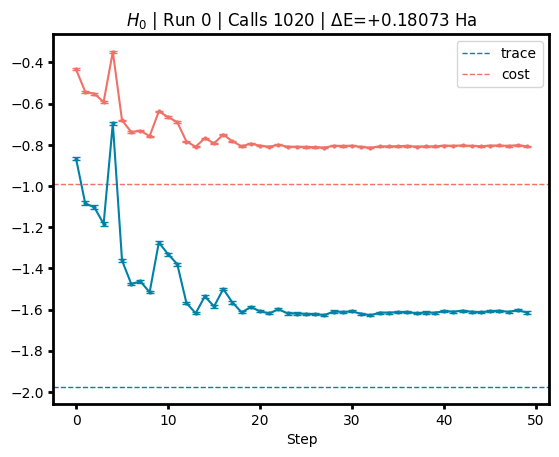

Loaded file ..\measurements\reorganized_files\COBYLA exposure=10s\H_0_run_0_0.npz
H_0


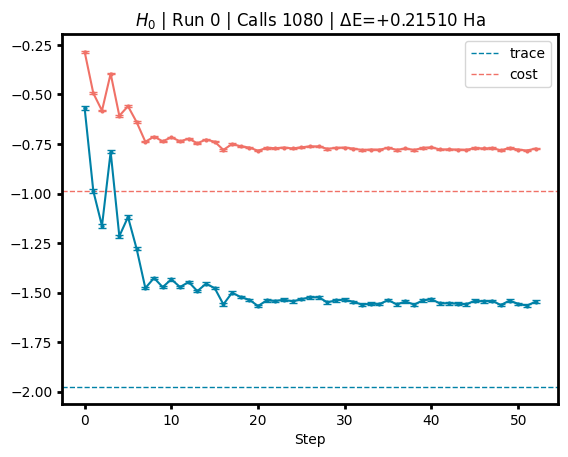

Loaded file ..\measurements\reorganized_files\COBYLA exposure=10s\H_0_run_1.npz
H_0


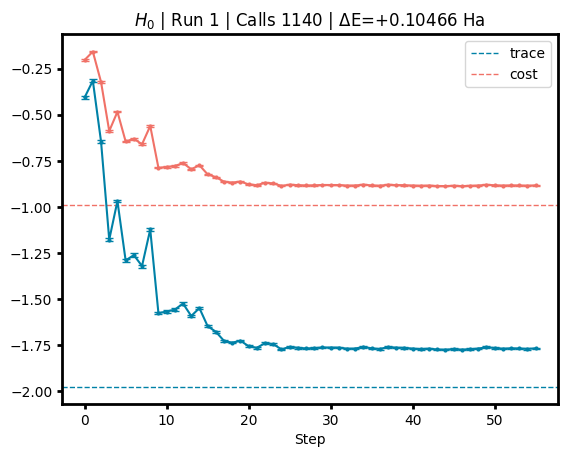

Loaded file ..\measurements\reorganized_files\COBYLA exposure=10s\H_0_run_2.npz
H_0


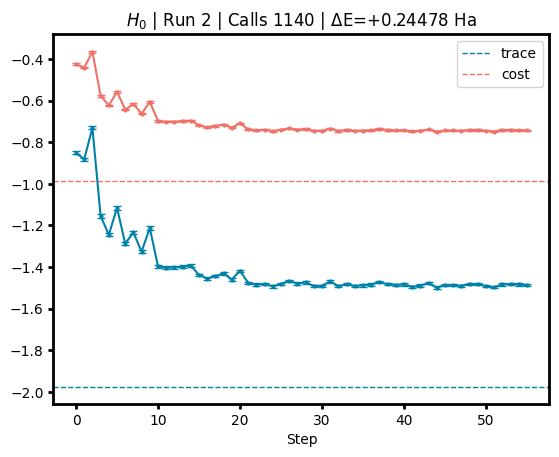

Loaded file ..\measurements\reorganized_files\COBYLA exposure=10s\H_0_run_3.npz
H_0


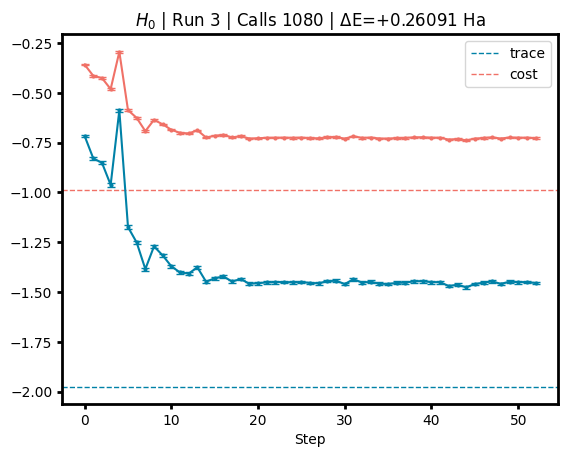

Loaded file ..\measurements\reorganized_files\COBYLA exposure=10s\H_0_run_4.npz
H_0


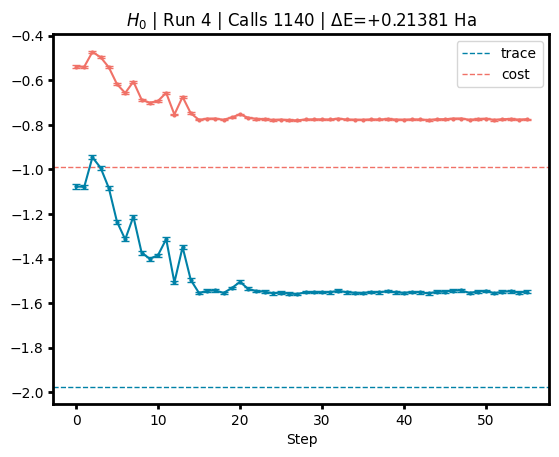

In [5]:
colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

location = Path("../measurements/reorganized_files/COBYLA exposure=10s")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        print(H)
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        density = np.array(data['density']).real
        error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[1]
        fig, ax = plt.subplots()
        ax.spines[:].set_linewidth(2)
        ax.tick_params(width=2)
        xs = np.arange(len(cost))
    
        ax.set_xlabel("Step")
        ax.axhline(y=trace_true, color=colors[0], linewidth=1, ls='--',  label='trace')
        ax.axhline(y=cost_true, color=colors[5], linewidth=1, ls='--', label='cost')
        ax.errorbar(xs, trace, trace_e, marker='o', color = colors[0], markersize=2, capsize=3)
        ax.errorbar(xs, cost, cost_e, marker='o', color = colors[5], markersize=2, capsize=3)
        ax.set_title(f"${H}$ | Run {run} | Calls {calls} | ΔE={cost[-1]-cost_true:+.5f} Ha")
        ax.legend()

        plt.show()

Loaded file ..\measurements\reorganized_files\COBYLA exposure=10s\H_0_run_0.npz
H_0
Loaded file ..\measurements\reorganized_files\COBYLA exposure=10s\H_0_run_0_0.npz
H_0
Loaded file ..\measurements\reorganized_files\COBYLA exposure=10s\H_0_run_1.npz
H_0
Loaded file ..\measurements\reorganized_files\COBYLA exposure=10s\H_0_run_2.npz
H_0
Loaded file ..\measurements\reorganized_files\COBYLA exposure=10s\H_0_run_3.npz
H_0
Loaded file ..\measurements\reorganized_files\COBYLA exposure=10s\H_0_run_4.npz
H_0


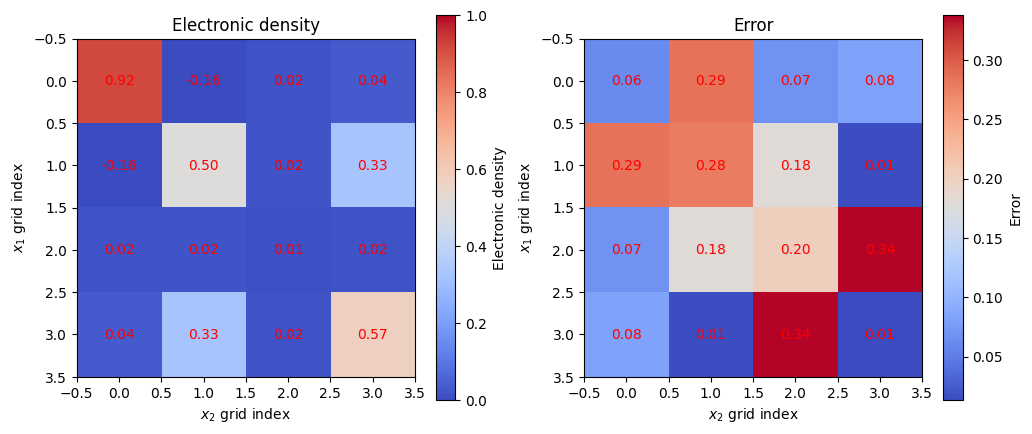

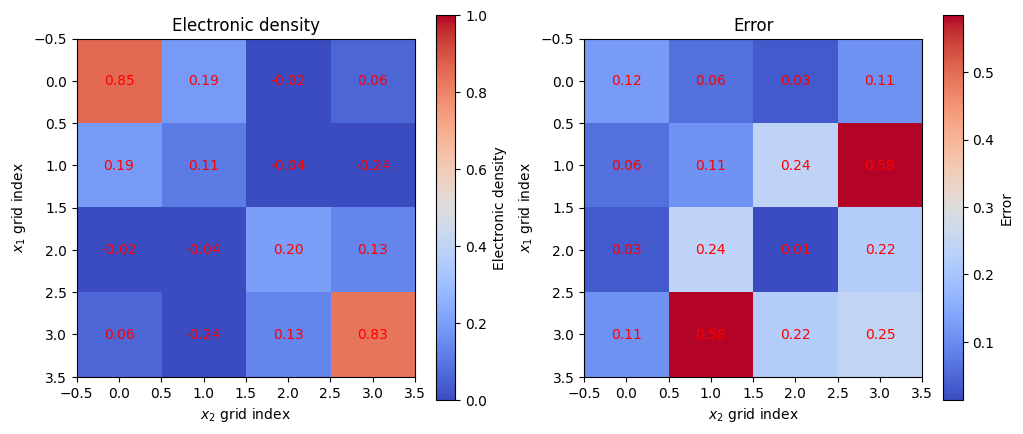

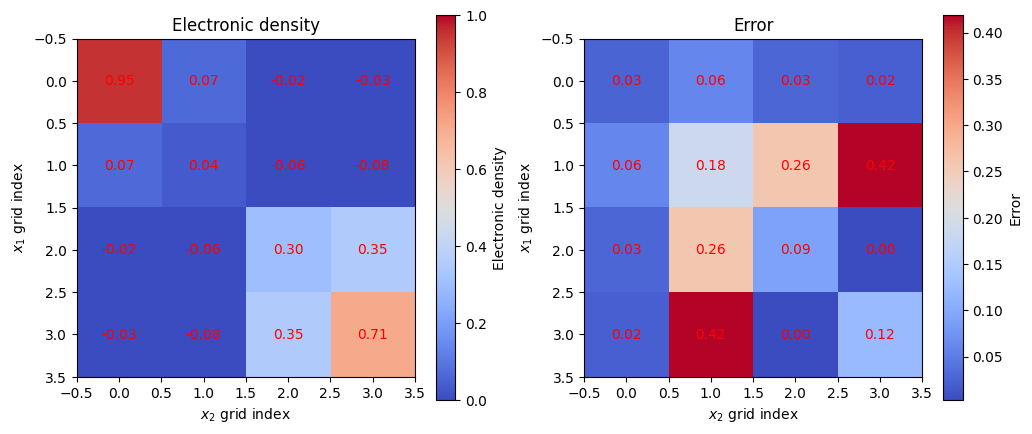

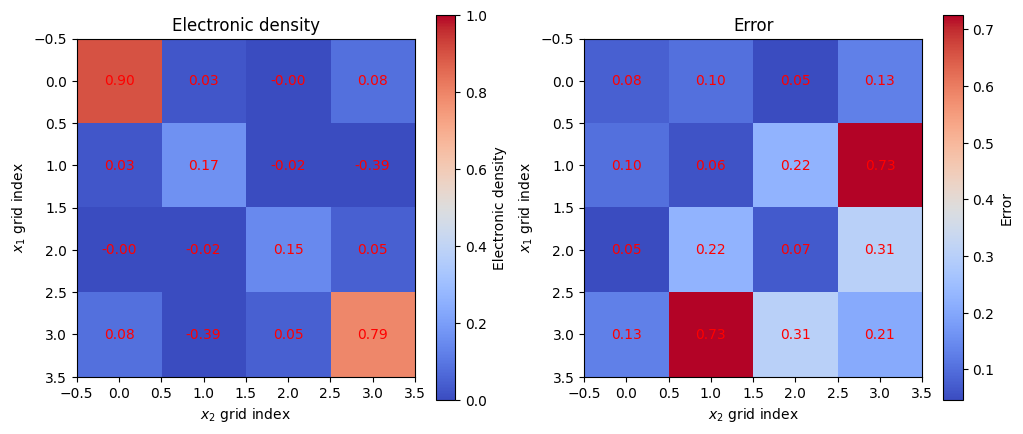

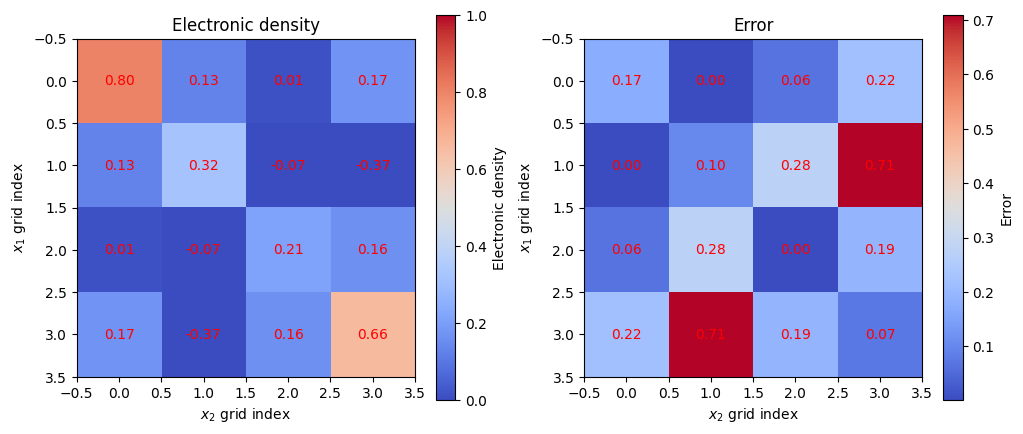

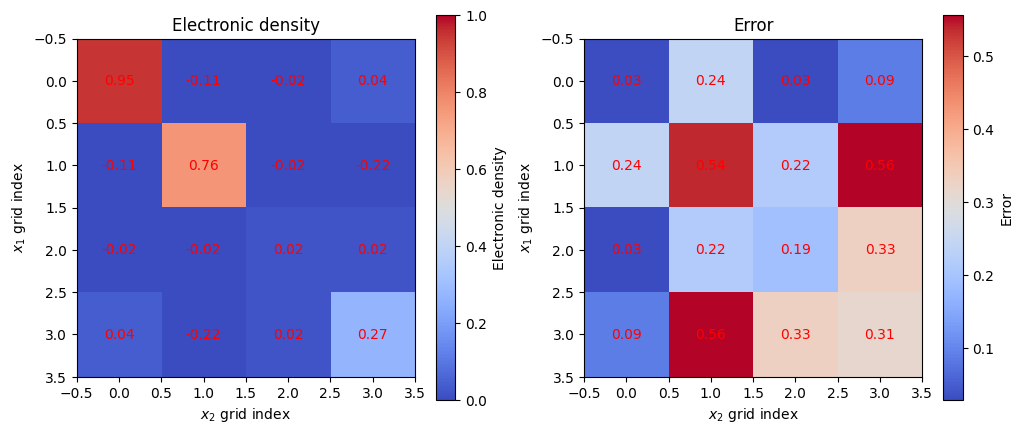

In [6]:
colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

location = Path("../measurements/reorganized_files/COBYLA exposure=10s")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        print(H)
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        density = np.array(data['density']).real
        error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[0]
        fig, axs = plt.subplots(1,2, figsize=(12,5))
        im1 = axs[0].imshow(density, cmap='coolwarm', aspect='equal', interpolation='nearest', vmin=0, vmax=1)
        for k in range(density.shape[0]):
            for l in range(density.shape[0]):
                axs[0].text(l, k, f"{density[k, l]:.2f}", ha='center', va='center', color='red')
        axs[0].set_title(f'Electronic density')
        axs[0].set_xlabel(f"$x_2$ grid index")

        im2 = axs[1].imshow(error_D, cmap='coolwarm', aspect='equal', interpolation='nearest')
        for k in range(density.shape[0]):
            for l in range(density.shape[0]):
                axs[1].text(l, k, f"{error_D[k, l]:.2f}", ha='center', va='center', color='red')
        axs[1].set_title(f'Error')
        axs[1].set_xlabel(f"$x_2$ grid index")
    
        fig.colorbar(im1, ax=axs[0], label="Electronic density")
        fig.colorbar(im2, ax=axs[1], label="Error")
        
        axs[0].set_ylabel(f"$x_1$ grid index")
        axs[1].set_ylabel(f"$x_1$ grid index")

## Recap plot

Final errors |cost_final - cost_true| per Hamiltonian and run:
  H1 run 0: 0.180734
  H1 run 0: 0.215102
  H1 run 1: 0.104660
  H1 run 2: 0.244780
  H1 run 3: 0.260906
  H1 run 4: 0.213806
  -> H1 min = 0.104660, mean = 0.203331


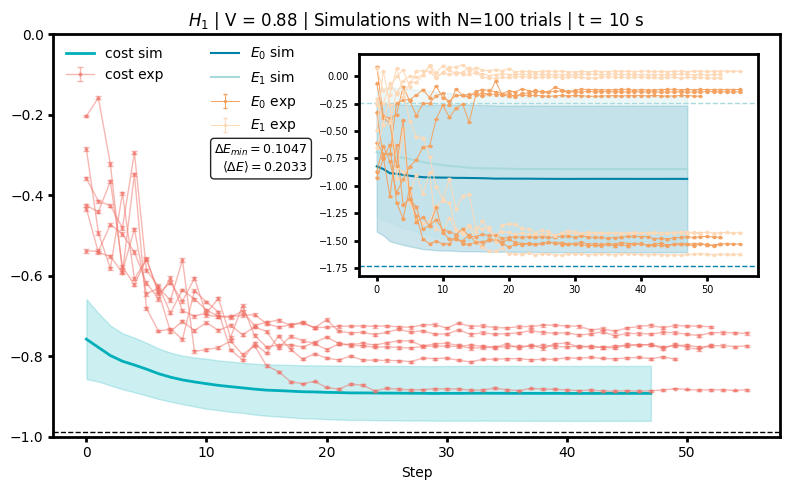

In [122]:
colors = ['#0081A7', '#00AFB9', '#A8DADC', '#FED9B7', '#F4A261', '#F07167']
N_H = 1

c_cost_sim, c_E1_sim, c_E2_sim = colors[1], colors[0], colors[2]
c_cost_exp, c_E1_exp, c_E2_exp = colors[5], colors[4], colors[3]

# ============================================================
# --- Simulation data (mean/std bands) ---
# ============================================================
sim_location = Path('../Simulations/8-mode chip/COBYLA_exp=10s/')

sim_cost_by_H = defaultdict(list)
sim_E1_by_H = defaultdict(list)
sim_E2_by_H = defaultdict(list)
sim_true_by_H = {}  # (cost_true, E1_true, E2_true)

for file in sorted(sim_location.glob('trial*.npz')):
    with np.load(file) as data:
        H = int(file.name[16:19][2]) 

        cost = np.array(data['cost'])
        E1 = np.array(data['E1'])
        E2 = np.array(data['E2'])
        energies = np.array(data['energies'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        E1_true, E2_true = energies[0], energies[1]

    sim_cost_by_H[H].append(cost)
    sim_E1_by_H[H].append(E1)
    sim_E2_by_H[H].append(E2)
    sim_true_by_H[H] = (cost_true, E1_true, E2_true)

sim_steps = {}
sim_cost_mean, sim_cost_std = {}, {}
sim_E1_mean, sim_E1_std = {}, {}
sim_E2_mean, sim_E2_std = {}, {}

for H in range(1, N_H + 1):
    cost_pad = pad_and_stack(sim_cost_by_H[H])
    E1_pad = pad_and_stack(sim_E1_by_H[H])
    E2_pad = pad_and_stack(sim_E2_by_H[H])

    sim_steps[H] = np.arange(cost_pad.shape[1])
    sim_cost_mean[H] = np.nanmean(cost_pad, axis=0)
    sim_cost_std[H] = np.nanstd(cost_pad, axis=0)
    sim_E1_mean[H] = np.nanmean(E1_pad, axis=0)
    sim_E1_std[H] = np.nanstd(E1_pad, axis=0)
    sim_E2_mean[H] = np.nanmean(E2_pad, axis=0)
    sim_E2_std[H] = np.nanstd(E2_pad, axis=0)
n_sim = len(sim_cost_by_H[1])

# ============================================================
# --- Experimental data (all runs, grouped by H) ---
# ============================================================
exp_location = Path("../measurements/reorganized_files/COBYLA exposure=10s")

exp_by_H = defaultdict(list)  # H -> list of dicts (one per run)

for file in sorted(exp_location.glob('*.npz')):
    with np.load(file) as data:
        H = int(file.name[:3][2]) +1
        run = file.name[8]

        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        E1 = np.array(data['E1'])
        E1_e = np.array(data['E1_e'])
        E2 = np.array(data['E2'])
        E2_e = np.array(data['E2_e'])
        calls = np.array(data['calls'])

    exp_by_H[H].append({
        'run': run, 'calls': calls,
        'cost': cost, 'cost_e': cost_e,
        'E1': E1, 'E1_e': E1_e,
        'E2': E2, 'E2_e': E2_e,
    })

# ============================================================
# --- Plot: simulation band + all experimental runs, cost + E1/E2 inset ---
# ============================================================
fig, ax = plt.subplots(figsize=(8,5))

final_errors_by_H = defaultdict(list)

for H in range(1, N_H + 1):
    xs = sim_steps[H]
    cost_true, E1_true, E2_true = sim_true_by_H[H]

    # --- main plot: cost ---
    ax.axhline(y=cost_true, color='k', linewidth=1, ls='--')

    ax.plot(xs, sim_cost_mean[H], color=c_cost_sim, lw=2, label='cost sim')
    ax.fill_between(xs, sim_cost_mean[H] - sim_cost_std[H], sim_cost_mean[H] + sim_cost_std[H],
                     color=c_cost_sim, alpha=0.2)

    for k, run_data in enumerate(exp_by_H[H]):
        run_xs = np.arange(len(run_data['cost']))
        ax.errorbar(run_xs, run_data['cost'], run_data['cost_e'],
                     marker='o', color=c_cost_exp, markersize=2, capsize=2,
                     lw=1, alpha=0.5, label='cost exp' if k == 0 else None)
        # --- final error for this run ---
        final_error = run_data['cost'][-1] - cost_true
        final_errors_by_H[H].append((run_data['run'], final_error))

    ax.set_xlabel("Step")
    ax.set_title(f"$H_{H}$ | V = 0.88 | Simulations with N={n_sim} trials | t = 10 s")
    ax.legend(loc='upper left', frameon=False)

    # --- box with min/mean final error for this Hamiltonian ---
    errors_this_H =[e for _, e in final_errors_by_H[H]]

    if errors_this_H:
        min_err = min(errors_this_H)
        mean_err = np.mean(errors_this_H)
        textstr = rf"$\Delta E_{{min}} = {min_err:.4f}$" +"\n" + rf"$\langle\Delta E\rangle = {mean_err:.4f}$"
        ax.text(0.35, 0.65, textstr, transform=ax.transAxes,
                fontsize=9, va='bottom', ha='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='k'))
        
    # --- inset: E1 and E2 ---
    inset = ax.inset_axes([0.42, 0.40, 0.55, 0.55])
    inset.axhline(y=E1_true, color=c_E1_sim, linewidth=1, ls='--')
    inset.axhline(y=E2_true, color=c_E2_sim, linewidth=1, ls='--')

    inset.plot(xs, sim_E1_mean[H], color=c_E1_sim, lw=1.5, label='$E_0$ sim')
    inset.fill_between(xs, sim_E1_mean[H] - sim_E1_std[H], sim_E1_mean[H] + sim_E1_std[H],
                        color=c_E1_sim, alpha=0.2)

    inset.plot(xs, sim_E2_mean[H], color=c_E2_sim, lw=1.5, label='$E_1$ sim')
    inset.fill_between(xs, sim_E2_mean[H] - sim_E2_std[H], sim_E2_mean[H] + sim_E2_std[H],
                        color=c_E2_sim, alpha=0.2)

    for k, run_data in enumerate(exp_by_H[H]):
        run_xs = np.arange(len(run_data['E1']))
        inset.errorbar(run_xs, run_data['E1'], run_data['E1_e'],
                        marker='o', color=c_E1_exp, markersize=1.5, capsize=1.5,
                        lw=0.7, alpha=1, label='$E_0$ exp' if k == 0 else None)
        inset.errorbar(run_xs, run_data['E2'], run_data['E2_e'],
                        marker='o', color=c_E2_exp, markersize=1.5, capsize=1.5,
                        lw=0.7, alpha=1, label='$E_1$ exp' if k == 0 else None)

    inset.tick_params(width=2, labelsize=7)
    inset.legend(loc='upper left',
                 bbox_to_anchor=(0.2, 1.005), bbox_transform=ax.transAxes,
                 frameon=False)
    inset.spines[:].set_linewidth(2)

ax.spines[:].set_linewidth(2)
ax.tick_params(width=2, labelbottom=True, labelleft=True)
ax.set_ylim([-1,0])

plt.tight_layout()
plt.savefig(f'../Figures/COBYLA_exp=10s_all_runs.png')
plt.savefig(f'../Figures/COBYLA_exp=10s_all_runs.pdf')

# ============================================================
# --- Print final errors for all experimental runs ---
# ============================================================
print("Final errors |cost_final - cost_true| per Hamiltonian and run:")
for H in range(1, N_H + 1):
    for run, err in final_errors_by_H[H]:
        print(f"  H{H} run {run}: {err:.6f}")
    if final_errors_by_H[H]:
        errs = [e for _, e in final_errors_by_H[H]]
        print(f"  -> H{H} min = {min(errs):.6f}, mean = {np.mean(errs):.6f}")

# $\ket{++}, \ket{--}$ COBYLA with exposure = 10 s

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_0_run_0.npz
H_0


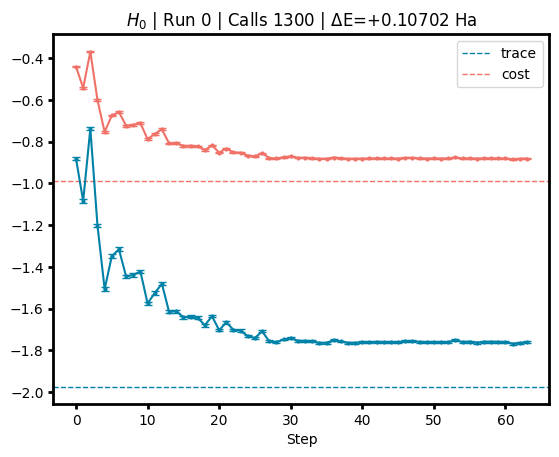

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_0_run_1.npz
H_0


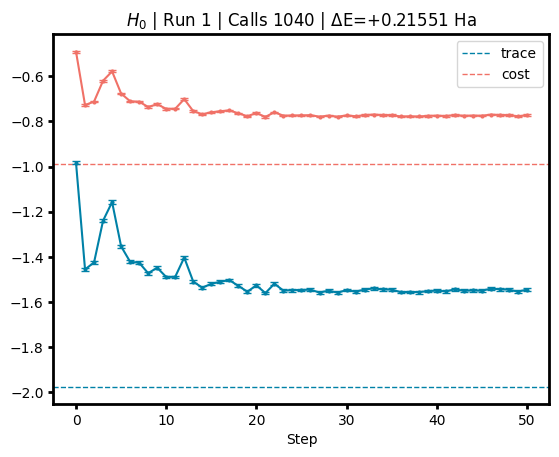

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_0_run_2.npz
H_0


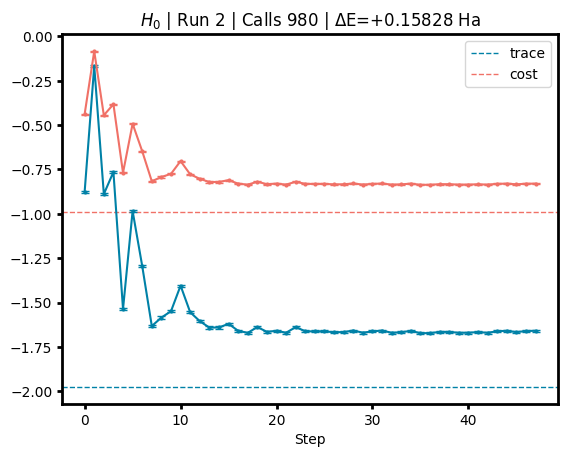

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_1_run_0.npz
H_1


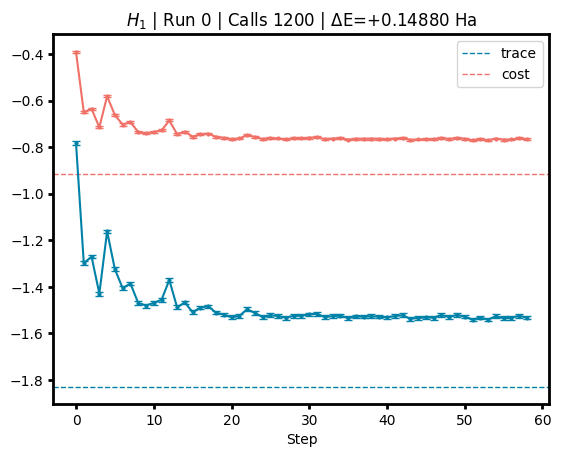

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_1_run_1.npz
H_1


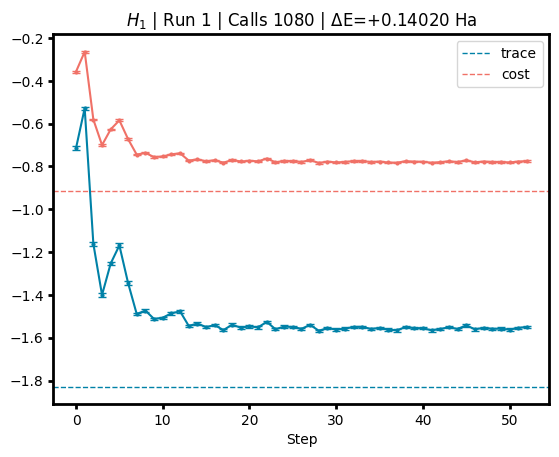

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_2_run_0.npz
H_2


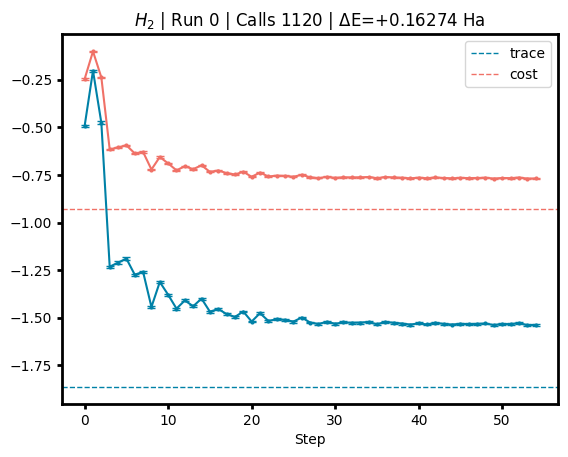

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_2_run_1.npz
H_2


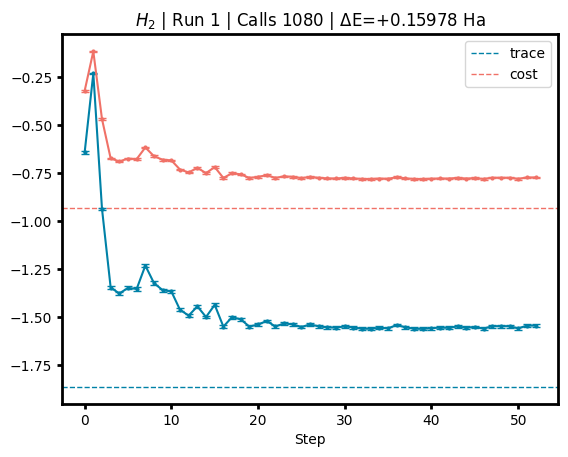

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_3_run_0.npz
H_3


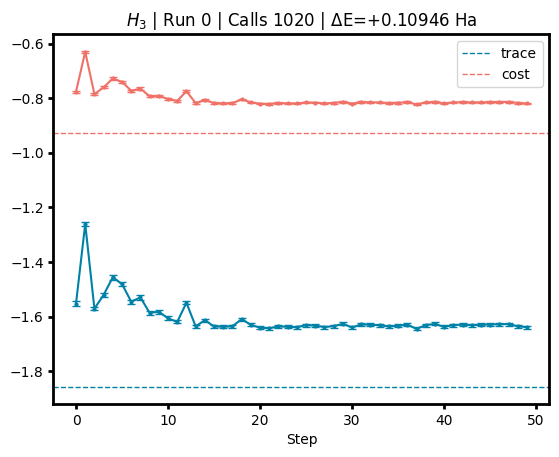

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_3_run_1.npz
H_3


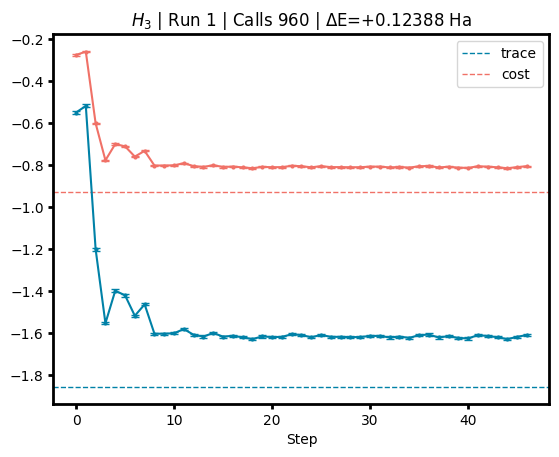

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_4_run_0.npz
H_4


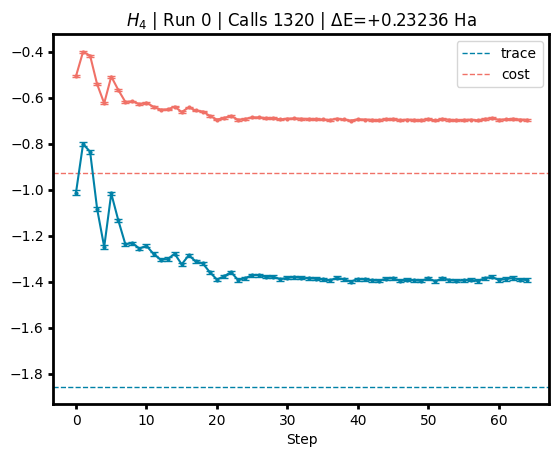

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_4_run_1.npz
H_4


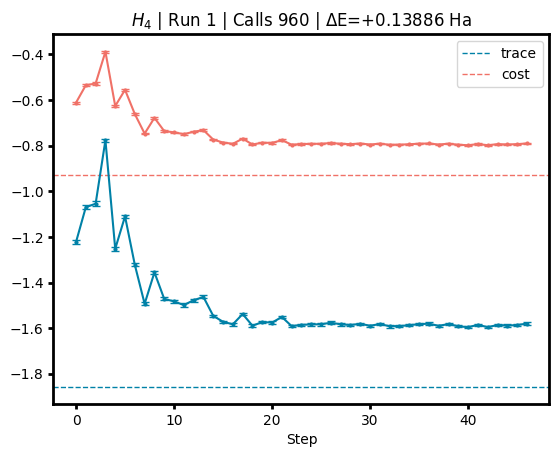

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_5_run_0.npz
H_5


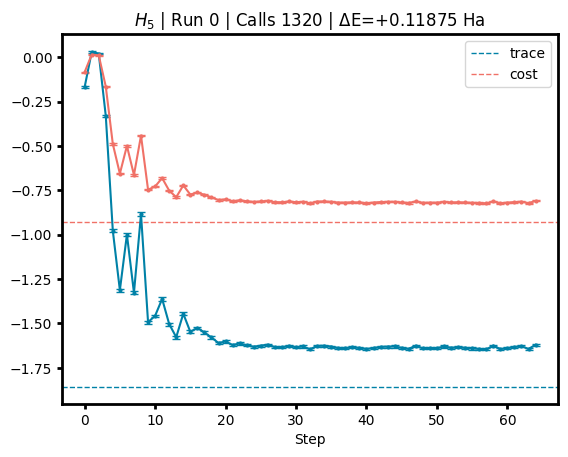

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_5_run_1.npz
H_5


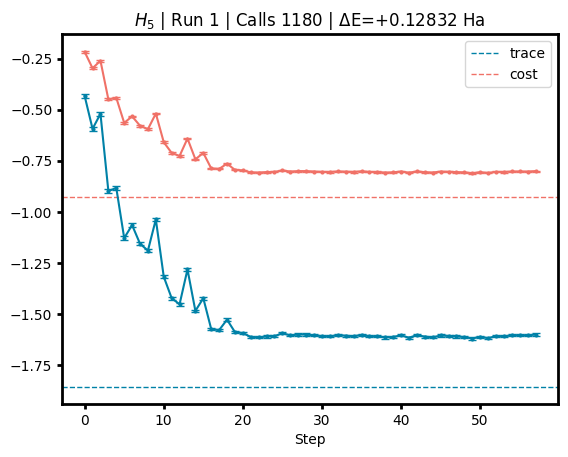

In [183]:
colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

location = Path("../measurements/reorganized_files/different_ansatz_COBYLA_exposure=10s")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        print(H)
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        density = np.array(data['density']).real
        error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[1]
        fig, ax = plt.subplots()
        ax.spines[:].set_linewidth(2)
        ax.tick_params(width=2)
        xs = np.arange(len(cost))
    
        ax.set_xlabel("Step")
        ax.axhline(y=trace_true, color=colors[0], linewidth=1, ls='--',  label='trace')
        ax.axhline(y=cost_true, color=colors[5], linewidth=1, ls='--', label='cost')
        ax.errorbar(xs, trace, trace_e, marker='o', color = colors[0], markersize=2, capsize=3)
        ax.errorbar(xs, cost, cost_e, marker='o', color = colors[5], markersize=2, capsize=3)
        ax.set_title(f"${H}$ | Run {run} | Calls {calls} | ΔE={cost[-1]-cost_true:+.5f} Ha")
        ax.legend()

        plt.show()

Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_0_run_0.npz
H_0
Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_0_run_1.npz
H_0
Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_0_run_2.npz
H_0
Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_1_run_0.npz
H_1
Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_1_run_1.npz
H_1
Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_2_run_0.npz
H_2
Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_2_run_1.npz
H_2
Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_3_run_0.npz
H_3
Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_3_run_1.npz
H_3
Loaded file ..\measurements\reorganized_files\different_ansatz_COBYLA_exposure=10s\H_4_run_

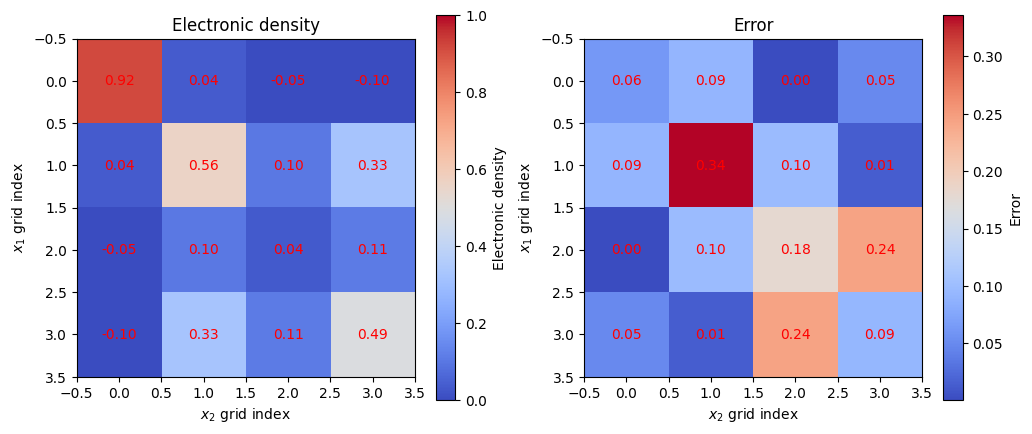

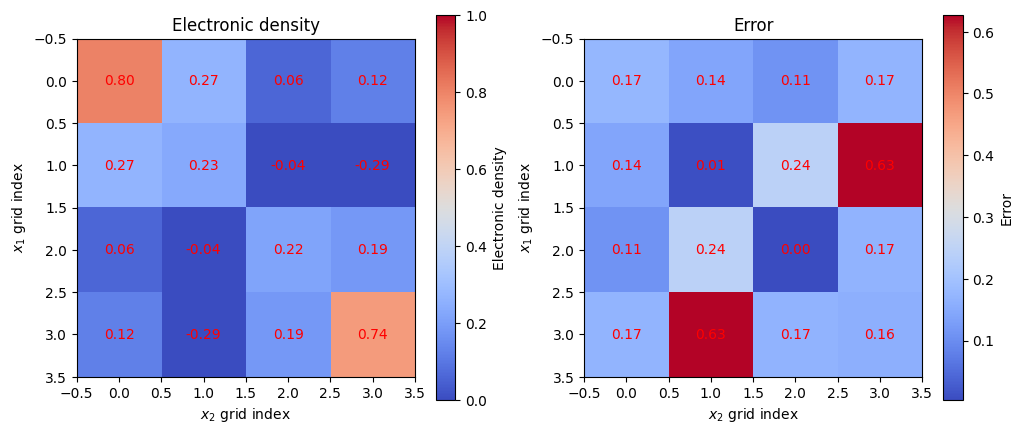

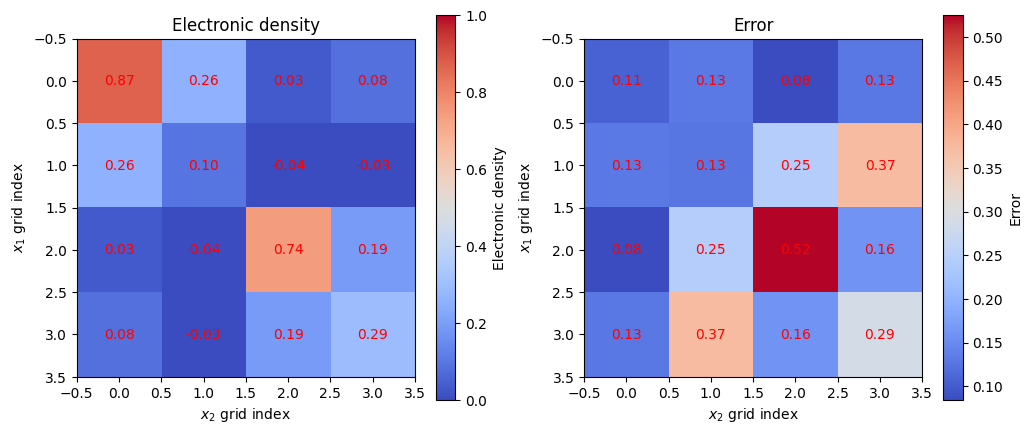

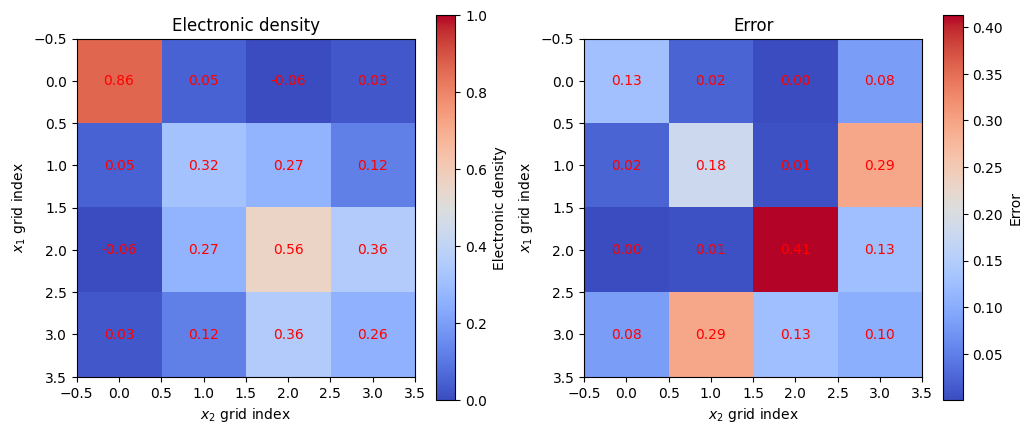

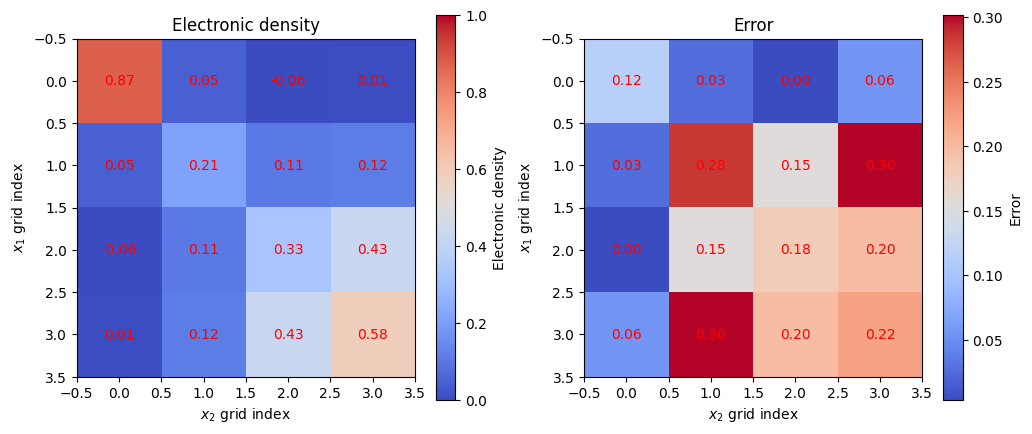

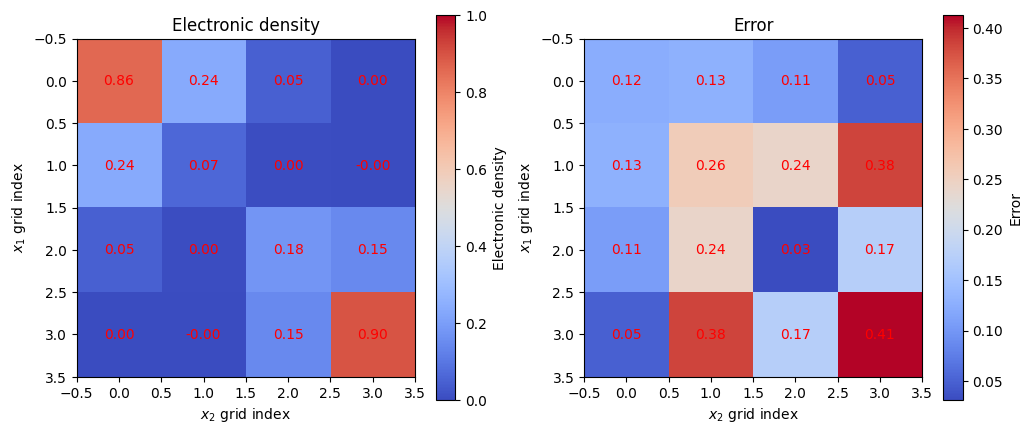

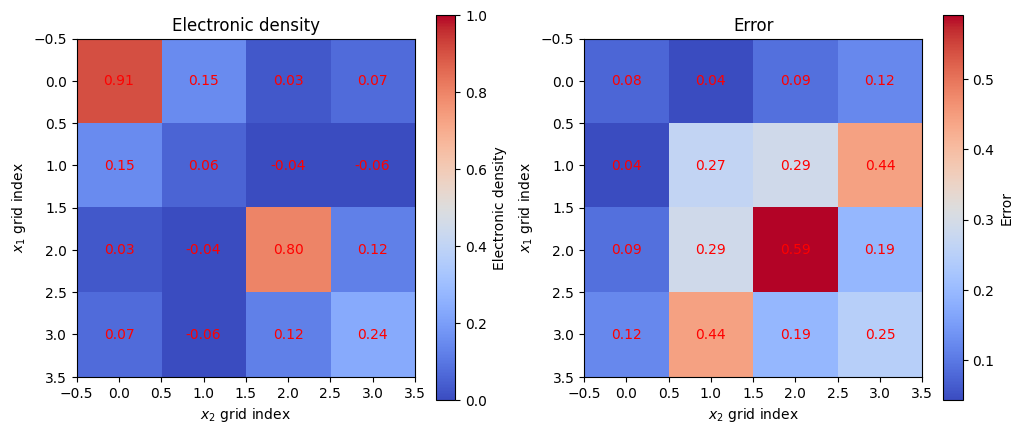

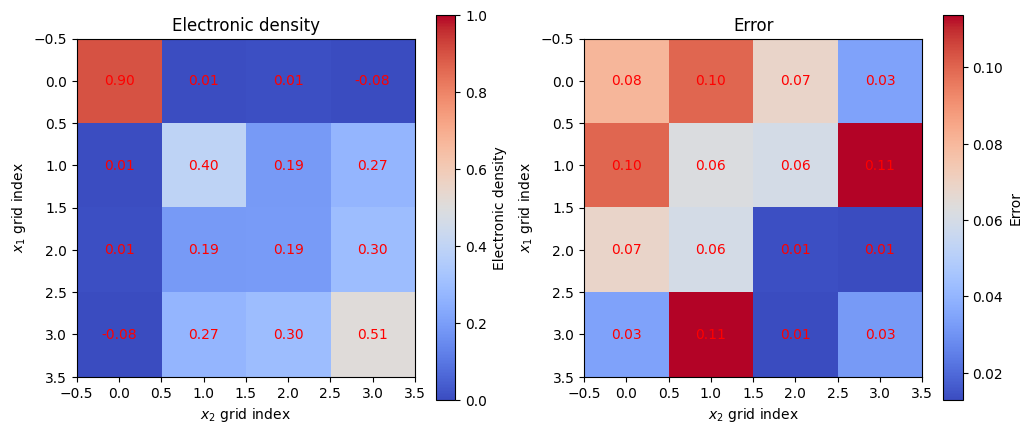

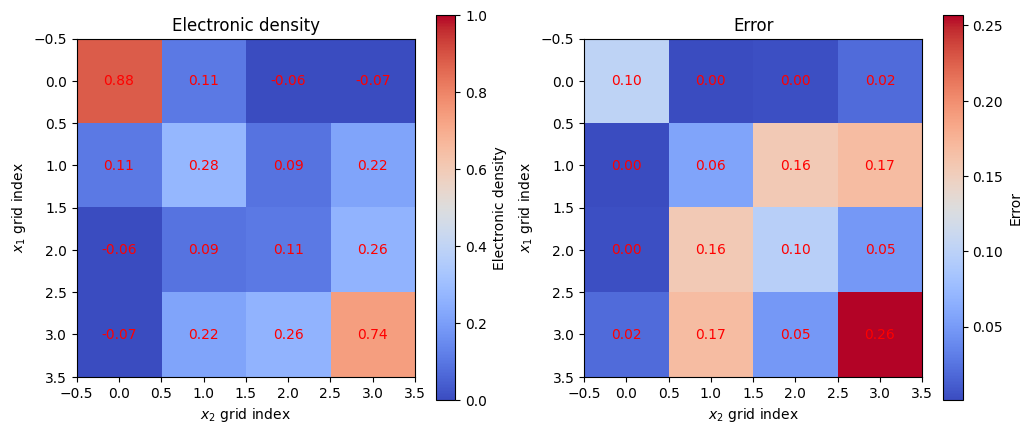

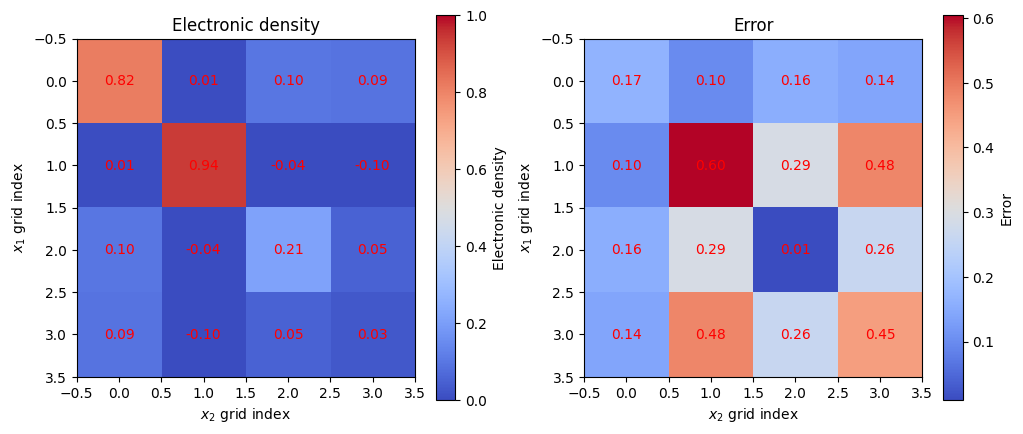

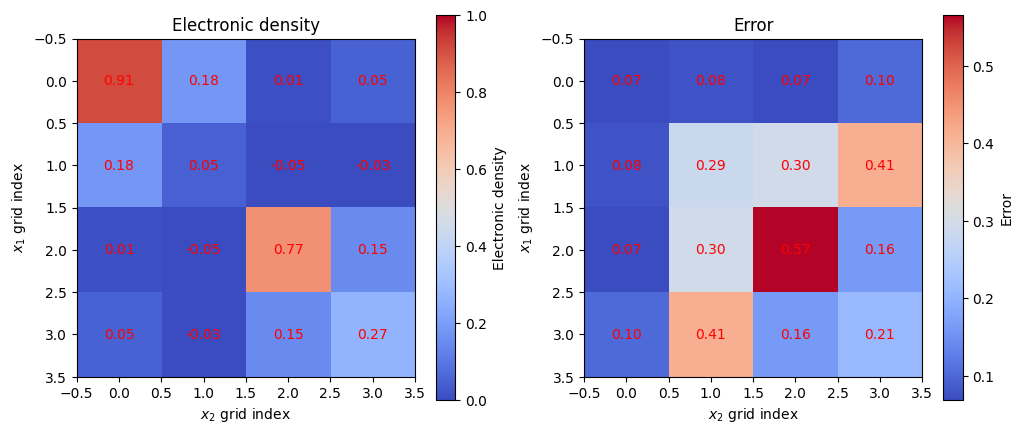

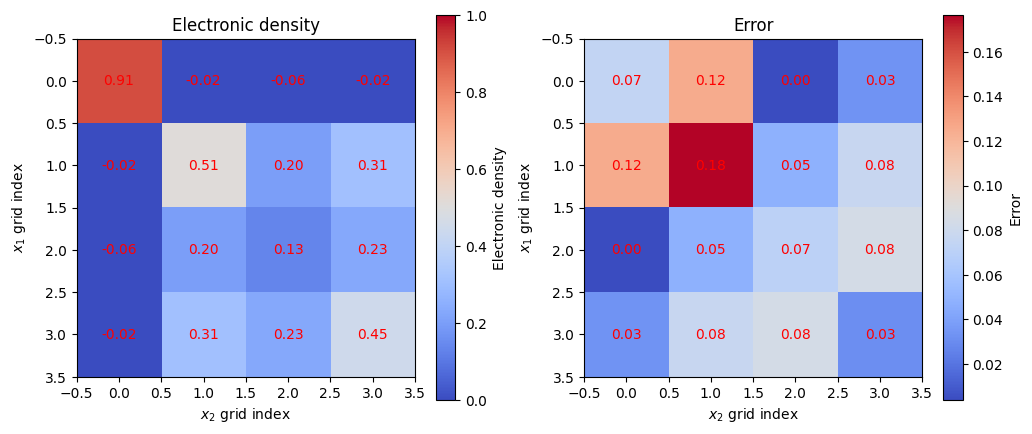

In [59]:
colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

location = Path("../measurements/reorganized_files/different_ansatz_COBYLA_exposure=10s")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        print(H)
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        density = np.array(data['density']).real
        error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[0]
        fig, axs = plt.subplots(1,2, figsize=(12,5))
        im1 = axs[0].imshow(density, cmap='coolwarm', aspect='equal', interpolation='nearest', vmin=0, vmax=1)
        for k in range(density.shape[0]):
            for l in range(density.shape[0]):
                axs[0].text(l, k, f"{density[k, l]:.2f}", ha='center', va='center', color='red')
        axs[0].set_title(f'Electronic density')
        axs[0].set_xlabel(f"$x_2$ grid index")

        im2 = axs[1].imshow(error_D, cmap='coolwarm', aspect='equal', interpolation='nearest')
        for k in range(density.shape[0]):
            for l in range(density.shape[0]):
                axs[1].text(l, k, f"{error_D[k, l]:.2f}", ha='center', va='center', color='red')
        axs[1].set_title(f'Error')
        axs[1].set_xlabel(f"$x_2$ grid index")
    
        fig.colorbar(im1, ax=axs[0], label="Electronic density")
        fig.colorbar(im2, ax=axs[1], label="Error")
        
        axs[0].set_ylabel(f"$x_1$ grid index")
        axs[1].set_ylabel(f"$x_1$ grid index")

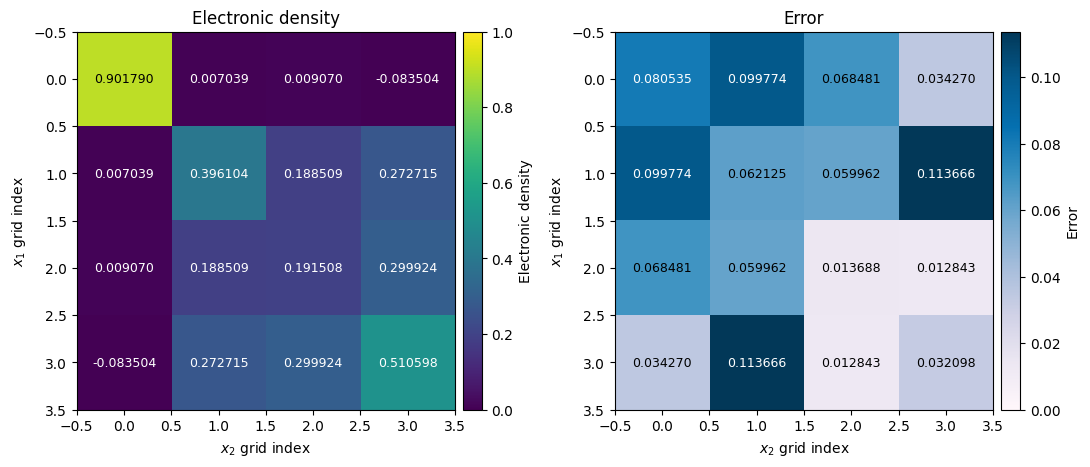

In [145]:
best_dm_file = np.load(f'../measurements/reorganized_files/different_ansatz_COBYLA_exposure=10s/H_3_run_0.npz')
density = np.array(best_dm_file['density']).real
error_D = np.array(best_dm_file['error_D'])

fig, axs = plt.subplots(1, 2, figsize=(11, 5))

def plot_matrix(ax, data, cmap, vmin, vmax, title, cbar_label):
    im = ax.imshow(data, cmap=cmap, aspect='equal', interpolation='nearest', vmin=vmin, vmax=vmax)

    # adaptive text color: light text on dark cells, dark text on light cells
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    for k in range(data.shape[0]):
        for l in range(data.shape[1]):
            rgba = im.cmap(norm(data[k, l]))
            luminance = 0.299*rgba[0] + 0.587*rgba[1] + 0.114*rgba[2]
            text_color = 'white' if luminance < 0.5 else 'black'
            ax.text(l, k, f"{data[k, l]:.6f}", ha='center', va='center',
                     color=text_color, fontsize=9)

    ax.set_title(title)
    ax.set_xlabel("$x_2$ grid index")

    # colorbar matched to axis height
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.08)
    fig.colorbar(im, cax=cax, label=cbar_label)
    return im

plot_matrix(axs[0], density, cmap='viridis', vmin=0, vmax=1,
            title='Electronic density', cbar_label='Electronic density')

# error_D can be signed, so center a diverging cmap at 0
err_max = np.max(np.abs(error_D))
plot_matrix(axs[1], error_D, cmap='PuBu', vmin=0, vmax=err_max,
            title='Error', cbar_label='Error')

axs[0].set_ylabel("$x_1$ grid index")
axs[1].set_ylabel("$x_1$ grid index")

plt.tight_layout()
plt.savefig(f'../Figures/best_density_COBYLA_10s_++--_H_3_run_0_1.png')
plt.savefig(f'../Figures/best_density_COBYLA_10s_++--_H_3_run_0_1.pdf')

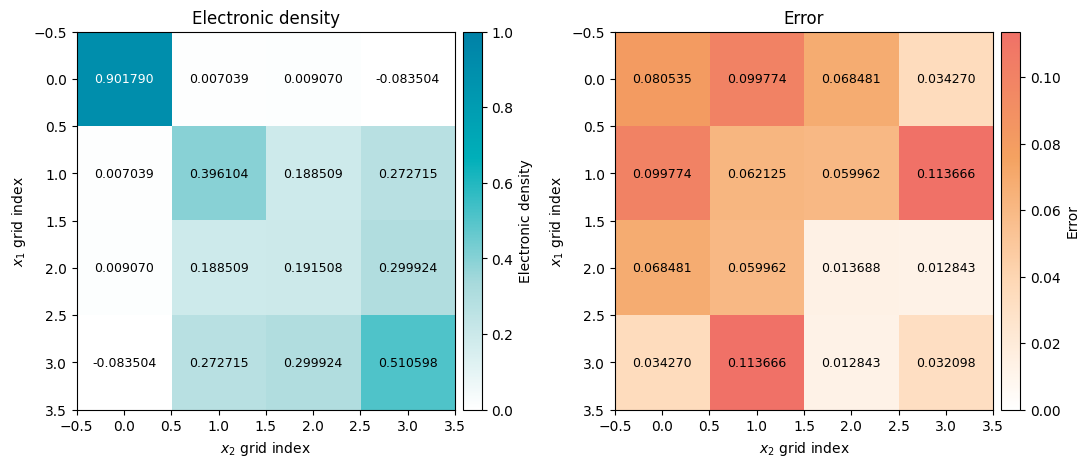

In [146]:
colors = ['#0081A7', '#00AFB9', '#A8DADC', '#FED9B7', '#F4A261', '#F07167']

# custom sequential cmaps built from your palette
cmap_density = LinearSegmentedColormap.from_list(
    'teal_seq', ['#FFFFFF', colors[2], colors[1], colors[0]], N=256
)
cmap_error = LinearSegmentedColormap.from_list(
    'warm_seq', ['#FFFFFF', colors[3], colors[4], colors[5]], N=256
)

best_dm_file = np.load(f'../measurements/reorganized_files/different_ansatz_COBYLA_exposure=10s/H_3_run_0.npz')
density = np.array(best_dm_file['density']).real
error_D = np.array(best_dm_file['error_D'])

fig, axs = plt.subplots(1, 2, figsize=(11, 5))

def plot_matrix(ax, data, cmap, vmin, vmax, title, cbar_label):
    im = ax.imshow(data, cmap=cmap, aspect='equal', interpolation='nearest', vmin=vmin, vmax=vmax)

    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    for k in range(data.shape[0]):
        for l in range(data.shape[1]):
            rgba = im.cmap(norm(data[k, l]))
            luminance = 0.299*rgba[0] + 0.587*rgba[1] + 0.114*rgba[2]
            text_color = 'white' if luminance < 0.5 else 'black'
            ax.text(l, k, f"{data[k, l]:.6f}", ha='center', va='center',
                     color=text_color, fontsize=9)

    ax.set_title(title)
    ax.set_xlabel("$x_2$ grid index")

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.08)
    fig.colorbar(im, cax=cax, label=cbar_label)
    return im

plot_matrix(axs[0], density, cmap=cmap_density, vmin=0, vmax=1,
            title='Electronic density', cbar_label='Electronic density')

plot_matrix(axs[1], error_D, cmap=cmap_error, vmin=0, vmax=np.max(error_D),
            title='Error', cbar_label='Error')

axs[0].set_ylabel("$x_1$ grid index")
axs[1].set_ylabel("$x_1$ grid index")

plt.tight_layout()

plt.savefig(f'../Figures/best_density_COBYLA_10s_++--_H_3_run_0_2.png')
plt.savefig(f'../Figures/best_density_COBYLA_10s_++--_H_3_run_0_2.pdf')

## Recap plot

Final errors |cost_final - cost_true| per Hamiltonian and run:
  H1 run 0: 0.107020
  H1 run 1: 0.215515
  H1 run 2: 0.158280
  -> H1 min = 0.107020, mean = 0.160272
  H2 run 0: 0.148800
  H2 run 1: 0.140201
  -> H2 min = 0.140201, mean = 0.144500
  H3 run 0: 0.162745
  H3 run 1: 0.159777
  -> H3 min = 0.159777, mean = 0.161261
  H4 run 0: 0.109458
  H4 run 1: 0.123879
  -> H4 min = 0.109458, mean = 0.116669
  H5 run 0: 0.232360
  H5 run 1: 0.138855
  -> H5 min = 0.138855, mean = 0.185608
  H6 run 0: 0.118751
  H6 run 1: 0.128322
  -> H6 min = 0.118751, mean = 0.123536
-0.8376404714639246


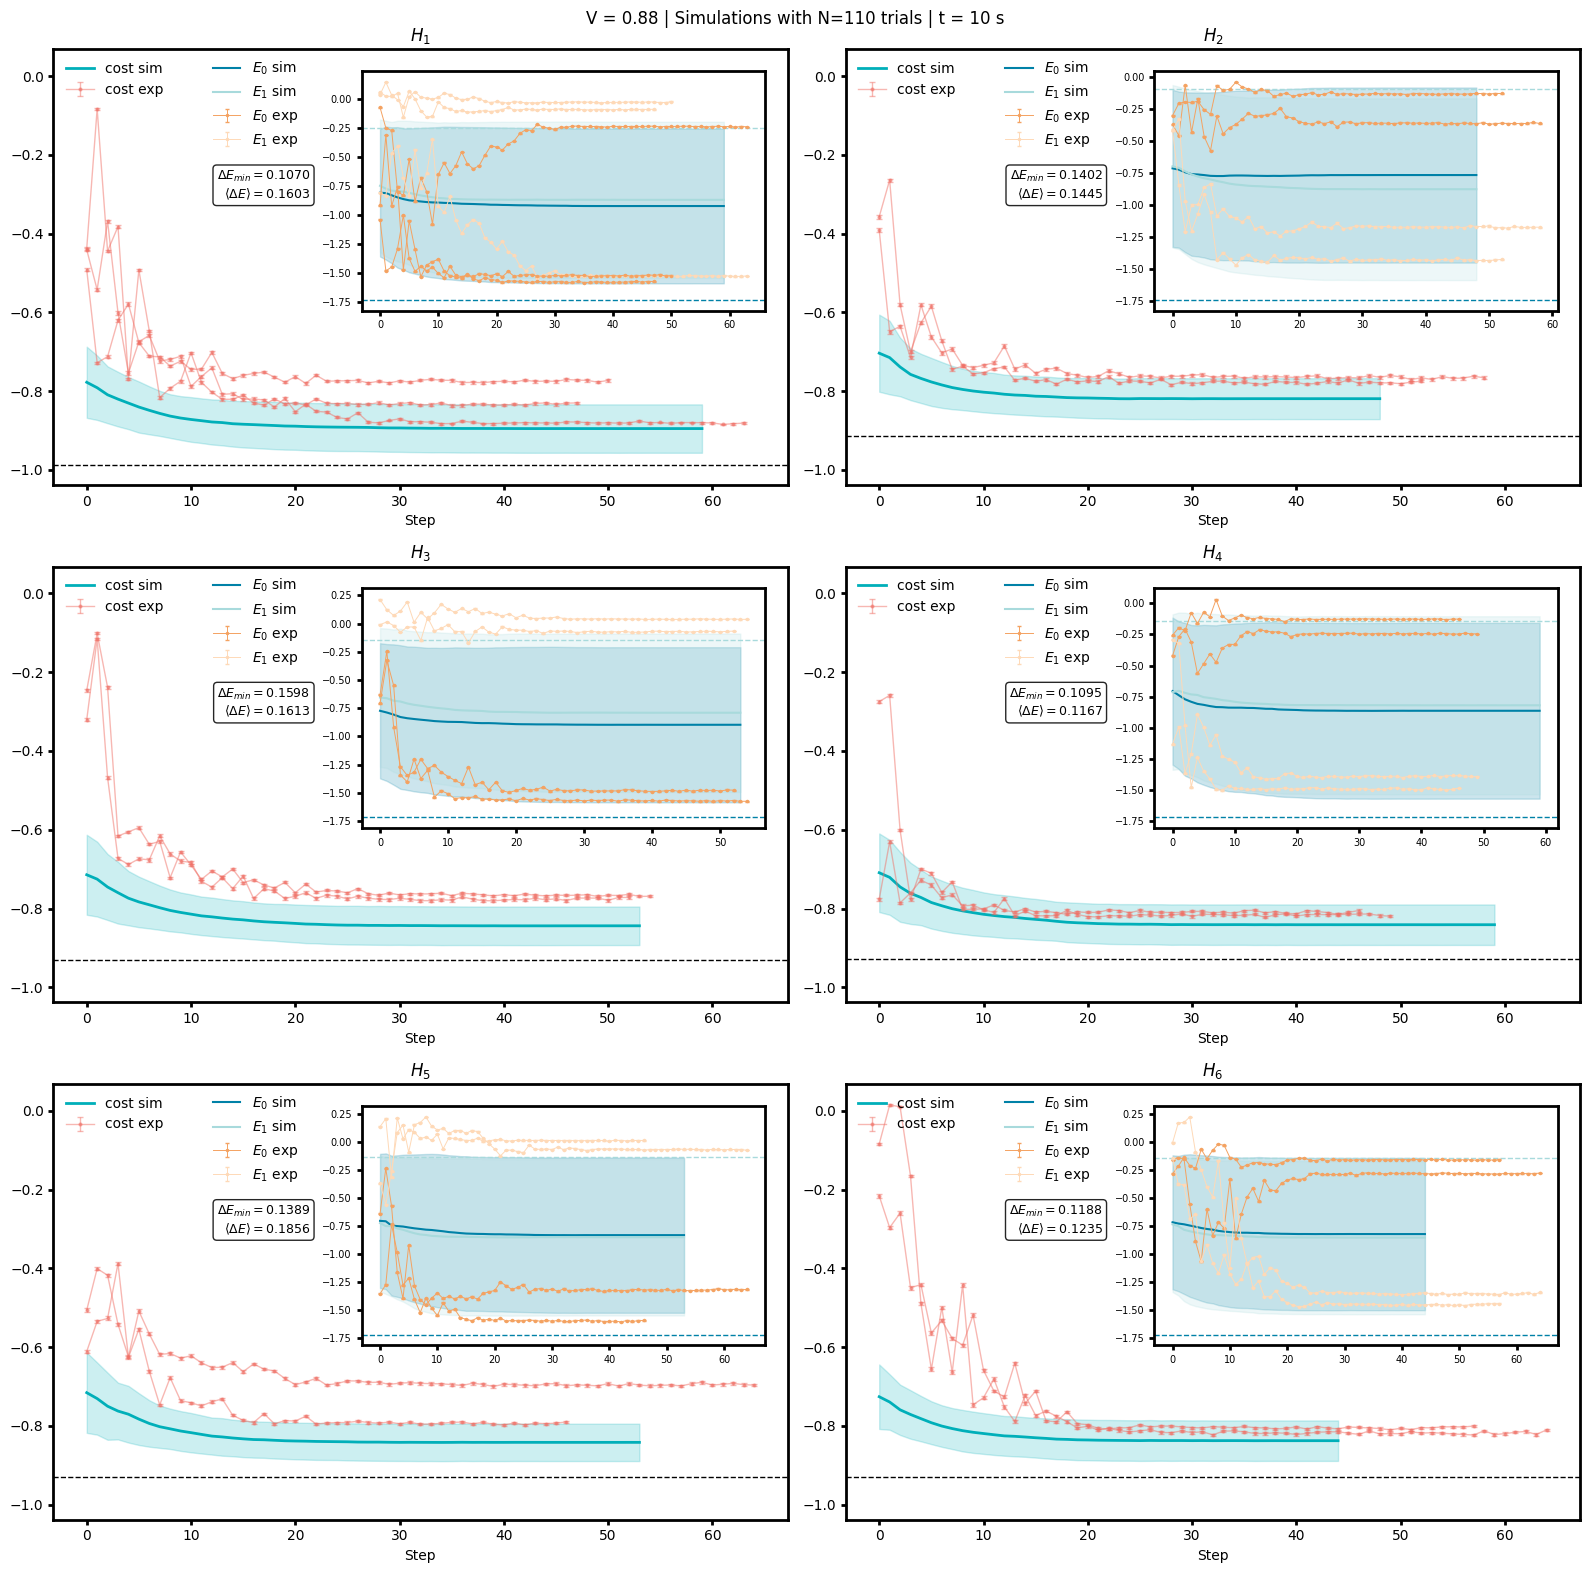

In [21]:
colors = ['#0081A7', '#00AFB9', '#A8DADC', '#FED9B7', '#F4A261', '#F07167']
N_H = 6

c_cost_sim, c_E1_sim, c_E2_sim = colors[1], colors[0], colors[2]
c_cost_exp, c_E1_exp, c_E2_exp = colors[5], colors[4], colors[3]

# ============================================================
# --- Simulation data (mean/std bands) ---
# ============================================================
sim_location = Path('../Simulations/8-mode chip/different_ansatz_COBYLA_exp=10s/')

sim_cost_by_H = defaultdict(list)
sim_E1_by_H = defaultdict(list)
sim_E2_by_H = defaultdict(list)
sim_true_by_H = {}  # (cost_true, E1_true, E2_true)

for file in sorted(sim_location.glob('trial*.npz')):
    with np.load(file) as data:
        H = int(file.name[16:19][2]) 

        cost = np.array(data['cost'])
        E1 = np.array(data['E1'])
        E2 = np.array(data['E2'])
        energies = np.array(data['energies'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        E1_true, E2_true = energies[0], energies[1]

    sim_cost_by_H[H].append(cost)
    sim_E1_by_H[H].append(E1)
    sim_E2_by_H[H].append(E2)
    sim_true_by_H[H] = (cost_true, E1_true, E2_true)

sim_steps = {}
sim_cost_mean, sim_cost_std = {}, {}
sim_E1_mean, sim_E1_std = {}, {}
sim_E2_mean, sim_E2_std = {}, {}

for H in range(1, N_H + 1):
    cost_pad = pad_and_stack(sim_cost_by_H[H])
    E1_pad = pad_and_stack(sim_E1_by_H[H])
    E2_pad = pad_and_stack(sim_E2_by_H[H])

    sim_steps[H] = np.arange(cost_pad.shape[1])
    sim_cost_mean[H] = np.nanmean(cost_pad, axis=0)
    sim_cost_std[H] = np.nanstd(cost_pad, axis=0)
    sim_E1_mean[H] = np.nanmean(E1_pad, axis=0)
    sim_E1_std[H] = np.nanstd(E1_pad, axis=0)
    sim_E2_mean[H] = np.nanmean(E2_pad, axis=0)
    sim_E2_std[H] = np.nanstd(E2_pad, axis=0)
n_sim = len(sim_cost_by_H[1])

# ============================================================
# --- Experimental data (all runs, grouped by H) ---
# ============================================================
exp_location = Path("../measurements/reorganized_files/different_ansatz_COBYLA_exposure=10s")

exp_by_H = defaultdict(list)  # H -> list of dicts (one per run)

for file in sorted(exp_location.glob('*.npz')):
    with np.load(file) as data:
        H = int(file.name[:3][2]) +1
        run = file.name[8]

        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        E1 = np.array(data['E1'])
        E1_e = np.array(data['E1_e'])
        E2 = np.array(data['E2'])
        E2_e = np.array(data['E2_e'])
        calls = np.array(data['calls'])

    exp_by_H[H].append({
        'run': run, 'calls': calls,
        'cost': cost, 'cost_e': cost_e,
        'E1': E1, 'E1_e': E1_e,
        'E2': E2, 'E2_e': E2_e,
    })

# ============================================================
# --- Plot: simulation band + all experimental runs, cost + E1/E2 inset ---
# ============================================================
fig, axs = plt.subplots(3, 2, figsize=(16,16), sharey=True, sharex=True)

final_errors_by_H = defaultdict(list)

for H in range(1, N_H + 1):
    ax = axs[(H - 1) // 2, (H - 1) % 2]
    xs = sim_steps[H]
    cost_true, E1_true, E2_true = sim_true_by_H[H]

    # --- main plot: cost ---
    ax.axhline(y=cost_true, color='k', linewidth=1, ls='--')

    ax.plot(xs, sim_cost_mean[H], color=c_cost_sim, lw=2, label='cost sim')
    ax.fill_between(xs, sim_cost_mean[H] - sim_cost_std[H], sim_cost_mean[H] + sim_cost_std[H],
                     color=c_cost_sim, alpha=0.2)

    for k, run_data in enumerate(exp_by_H[H]):
        run_xs = np.arange(len(run_data['cost']))
        ax.errorbar(run_xs, run_data['cost'], run_data['cost_e'],
                     marker='o', color=c_cost_exp, markersize=2, capsize=2,
                     lw=1, alpha=0.5, label='cost exp' if k == 0 else None)
        # --- final error for this run ---
        final_error = run_data['cost'][-1] - cost_true
        final_errors_by_H[H].append((run_data['run'], final_error))

    ax.set_xlabel("Step")
    ax.set_title(f"$H_{H}$")
    ax.legend(loc='upper left', frameon=False)

    # --- box with min/mean final error for this Hamiltonian ---
    errors_this_H =[e for _, e in final_errors_by_H[H]]

    if errors_this_H:
        min_err = min(errors_this_H)
        mean_err = np.mean(errors_this_H)
        textstr = rf"$\Delta E_{{min}} = {min_err:.4f}$" +"\n" + rf"$\langle\Delta E\rangle = {mean_err:.4f}$"
        ax.text(0.35, 0.65, textstr, transform=ax.transAxes,
                fontsize=9, va='bottom', ha='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='k'))
        
    # --- inset: E1 and E2 ---
    inset = ax.inset_axes([0.42, 0.40, 0.55, 0.55])
    inset.axhline(y=E1_true, color=c_E1_sim, linewidth=1, ls='--')
    inset.axhline(y=E2_true, color=c_E2_sim, linewidth=1, ls='--')

    inset.plot(xs, sim_E1_mean[H], color=c_E1_sim, lw=1.5, label='$E_0$ sim')
    inset.fill_between(xs, sim_E1_mean[H] - sim_E1_std[H], sim_E1_mean[H] + sim_E1_std[H],
                        color=c_E1_sim, alpha=0.2)

    inset.plot(xs, sim_E2_mean[H], color=c_E2_sim, lw=1.5, label='$E_1$ sim')
    inset.fill_between(xs, sim_E2_mean[H] - sim_E2_std[H], sim_E2_mean[H] + sim_E2_std[H],
                        color=c_E2_sim, alpha=0.2)

    # for j, run_E1 in enumerate(sim_E1_by_H[H]):
    #     run_xs = np.arange(len(run_E1))
    #     inset.plot(run_xs, run_E1, color=c_E1_sim, lw=0.6, alpha=0.25,
    #                label='$E_0$ sim (runs)' if j == 0 else None)
    # for j, run_E2 in enumerate(sim_E2_by_H[H]):
    #     run_xs = np.arange(len(run_E2))
    #     inset.plot(run_xs, run_E2, color=c_E2_sim, lw=0.6, alpha=0.25,
    #                label='$E_1$ sim (runs)' if j == 0 else None)
        
    for k, run_data in enumerate(exp_by_H[H]):
        run_xs = np.arange(len(run_data['E1']))
        inset.errorbar(run_xs, run_data['E1'], run_data['E1_e'],
                        marker='o', color=c_E1_exp, markersize=1.5, capsize=1.5,
                        lw=0.7, alpha=1, label='$E_0$ exp' if k == 0 else None)
        inset.errorbar(run_xs, run_data['E2'], run_data['E2_e'],
                        marker='o', color=c_E2_exp, markersize=1.5, capsize=1.5,
                        lw=0.7, alpha=1, label='$E_1$ exp' if k == 0 else None)

    inset.tick_params(width=2, labelsize=7)
    inset.legend(loc='upper left',
                 bbox_to_anchor=(0.2, 1.005), bbox_transform=ax.transAxes,
                 frameon=False)
    inset.spines[:].set_linewidth(2)

for ax in axs.ravel():
    ax.spines[:].set_linewidth(2)
    ax.tick_params(width=2, labelbottom=True, labelleft=True)
    # ax.set_ylim([-1,0])
plt.suptitle(f'V = 0.88 | Simulations with N={n_sim} trials | t = 10 s')
plt.tight_layout()
plt.savefig(f'../Figures/different_ansatz_COBYLA_exp=10s_all_runs.png')
plt.savefig(f'../Figures/different_ansatz_COBYLA_exp=10s_all_runs.pdf')

# ============================================================
# --- Print final errors for all experimental runs ---
# ============================================================
print("Final errors |cost_final - cost_true| per Hamiltonian and run:")
for H in range(1, N_H + 1):
    for run, err in final_errors_by_H[H]:
        print(f"  H{H} run {run}: {err:.6f}")
    if final_errors_by_H[H]:
        errs = [e for _, e in final_errors_by_H[H]]
        print(f"  -> H{H} min = {min(errs):.6f}, mean = {np.mean(errs):.6f}")
print(sim_cost_mean[6][-1])


# $\ket{++}, \ket{--}$ COBYLA with exposure = 100 s

Loaded file ..\measurements\reorganized_files\++--_COBYLA_exposure=100s\H_6_run_0.npz
H_6


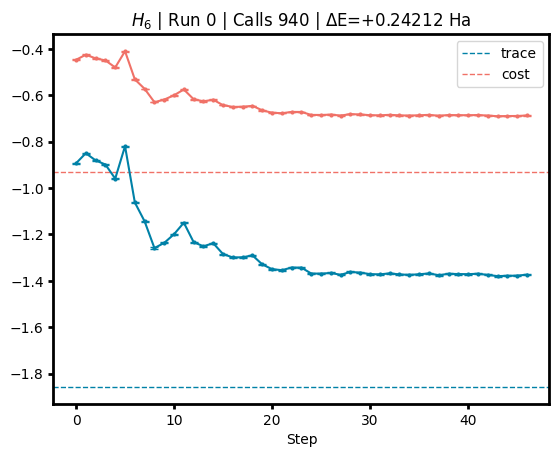

Loaded file ..\measurements\reorganized_files\++--_COBYLA_exposure=100s\H_6_run_1.npz
H_6


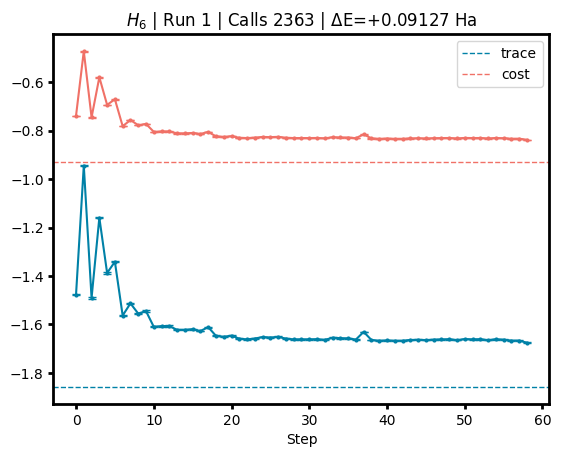

Loaded file ..\measurements\reorganized_files\++--_COBYLA_exposure=100s\H_6_run_2.npz
H_6


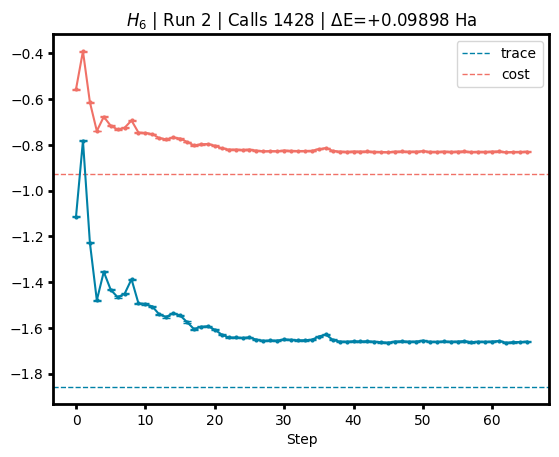

Loaded file ..\measurements\reorganized_files\++--_COBYLA_exposure=100s\H_6_run_3.npz
H_6


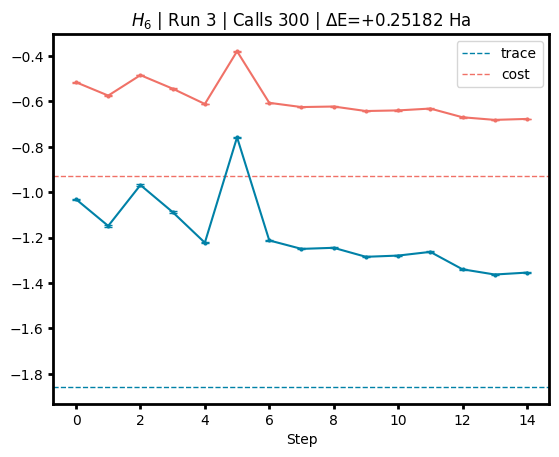

Loaded file ..\measurements\reorganized_files\++--_COBYLA_exposure=100s\H_6_run_9_interrupted.npz
H_6


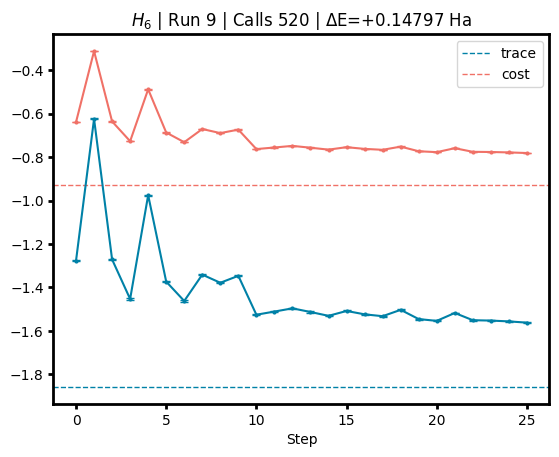

In [22]:
colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

# location = Path("../measurements/new_ansatz_COBYLA_2026-07-15_exp=100s/live saves/")
location = Path("../measurements/reorganized_files/++--_COBYLA_exposure=100s")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        print(H)
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        # density = np.array(data['density']).real
        # error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[1]
        fig, ax = plt.subplots()
        ax.spines[:].set_linewidth(2)
        ax.tick_params(width=2)
        xs = np.arange(len(cost))
    
        ax.set_xlabel("Step")
        ax.axhline(y=trace_true, color=colors[0], linewidth=1, ls='--',  label='trace')
        ax.axhline(y=cost_true, color=colors[5], linewidth=1, ls='--', label='cost')
        ax.errorbar(xs, trace, trace_e, marker='o', color = colors[0], markersize=2, capsize=3)
        ax.errorbar(xs, cost, cost_e, marker='o', color = colors[5], markersize=2, capsize=3)
        ax.set_title(f"${H}$ | Run {run} | Calls {calls} | ΔE={cost[-1]-cost_true:+.5f} Ha")
        ax.legend()

        plt.show()

Loaded file ..\measurements\reorganized_files\++--_COBYLA_exposure=100s\H_6_run_2.npz
H_6


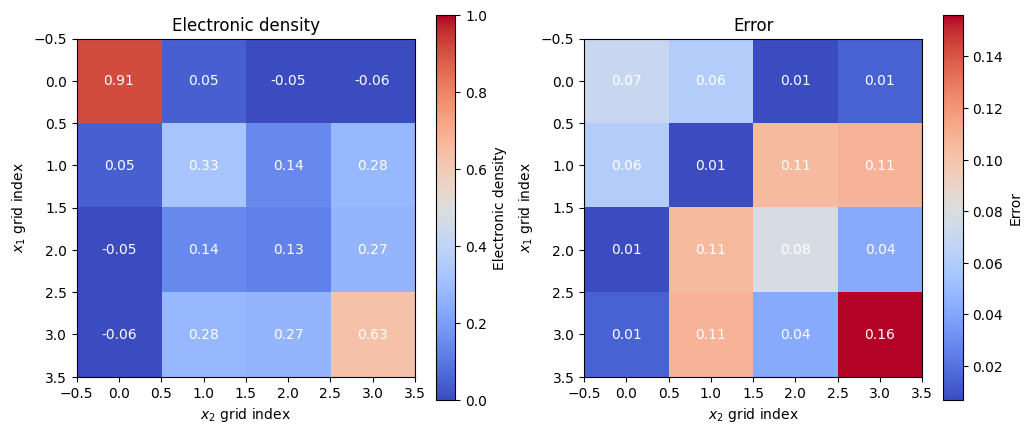

In [17]:
colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

location = Path(f"../measurements/reorganized_files/++--_COBYLA_exposure=100s")

for file in sorted(location.glob(f'*2.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        print(H)
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        density = np.array(data['density']).real
        error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[0]
        fig, axs = plt.subplots(1,2, figsize=(12,5))
        im1 = axs[0].imshow(density, cmap='coolwarm', aspect='equal', interpolation='nearest', vmin=0, vmax=1)
        for k in range(density.shape[0]):
            for l in range(density.shape[0]):
                axs[0].text(l, k, f"{density[k, l]:.2f}", ha='center', va='center', color='white')
        axs[0].set_title(f'Electronic density')
        axs[0].set_xlabel(f"$x_2$ grid index")

        im2 = axs[1].imshow(error_D, cmap='coolwarm', aspect='equal', interpolation='nearest')
        for k in range(density.shape[0]):
            for l in range(density.shape[0]):
                axs[1].text(l, k, f"{error_D[k, l]:.2f}", ha='center', va='center', color='white')
        axs[1].set_title(f'Error')
        axs[1].set_xlabel(f"$x_2$ grid index")
    
        fig.colorbar(im1, ax=axs[0], label="Electronic density")
        fig.colorbar(im2, ax=axs[1], label="Error")
        
        axs[0].set_ylabel(f"$x_1$ grid index")
        axs[1].set_ylabel(f"$x_1$ grid index")

## Recap plot

0
6
6
6
6
6
Final errors |cost_final - cost_true| per Hamiltonian and run:
  H6 run 0: 0.242117
  H6 run 1: 0.091274
  H6 run 2: 0.098983
  H6 run 3: 0.251818
  H6 run 9: 0.147972
  -> H6 min = 0.091274, mean = 0.166433
-0.8667744152442747


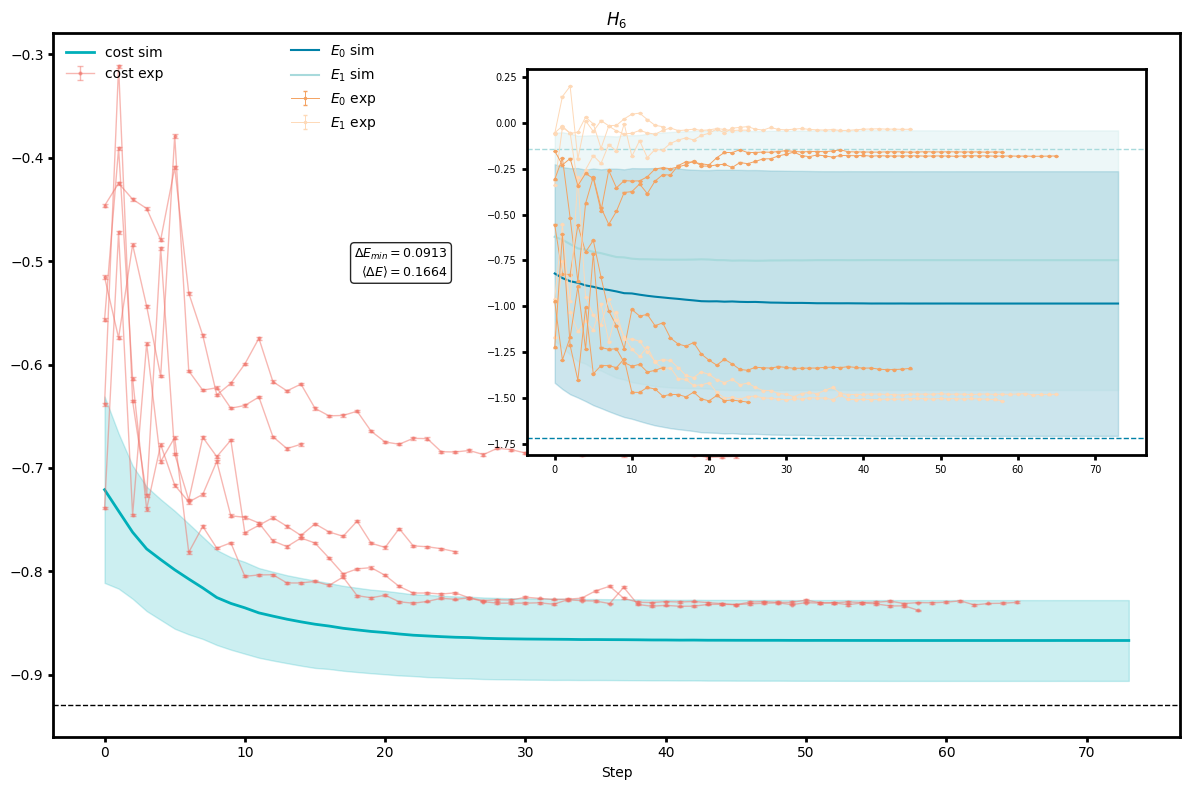

In [24]:
colors = ['#0081A7', '#00AFB9', '#A8DADC', '#FED9B7', '#F4A261', '#F07167']
N_H = 1

c_cost_sim, c_E1_sim, c_E2_sim = colors[1], colors[0], colors[2]
c_cost_exp, c_E1_exp, c_E2_exp = colors[5], colors[4], colors[3]

# ============================================================
# --- Simulation data (mean/std bands) ---
# ============================================================
sim_location = Path('../Simulations/8-mode chip/different_ansatz_COBYLA_exp=100s/')

sim_cost_by_H = defaultdict(list)
sim_E1_by_H = defaultdict(list)
sim_E2_by_H = defaultdict(list)
sim_true_by_H = {}  # (cost_true, E1_true, E2_true)

for file in sorted(sim_location.glob('trial*H_6*.npz')):
    with np.load(file) as data:
        H = int(file.name[15:18][2]) 
        # print(H)
        cost = np.array(data['cost'])
        E1 = np.array(data['E1'])
        E2 = np.array(data['E2'])
        energies = np.array(data['energies'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        E1_true, E2_true = energies[0], energies[1]

    sim_cost_by_H[H].append(cost)
    sim_E1_by_H[H].append(E1)
    sim_E2_by_H[H].append(E2)
    sim_true_by_H[H] = (cost_true, E1_true, E2_true)

sim_steps = {}
sim_cost_mean, sim_cost_std = {}, {}
sim_E1_mean, sim_E1_std = {}, {}
sim_E2_mean, sim_E2_std = {}, {}

for H in range(1, N_H + 1):
    H = 6
    cost_pad = pad_and_stack(sim_cost_by_H[H])
    E1_pad = pad_and_stack(sim_E1_by_H[H])
    E2_pad = pad_and_stack(sim_E2_by_H[H])

    sim_steps[H] = np.arange(cost_pad.shape[1])
    sim_cost_mean[H] = np.nanmean(cost_pad, axis=0)
    sim_cost_std[H] = np.nanstd(cost_pad, axis=0)
    sim_E1_mean[H] = np.nanmean(E1_pad, axis=0)
    sim_E1_std[H] = np.nanstd(E1_pad, axis=0)
    sim_E2_mean[H] = np.nanmean(E2_pad, axis=0)
    sim_E2_std[H] = np.nanstd(E2_pad, axis=0)

# ============================================================
# --- Experimental data (all runs, grouped by H) ---
# ============================================================
exp_location = Path("../measurements/reorganized_files/++--_COBYLA_exposure=100s")

exp_by_H = defaultdict(list)  # H -> list of dicts (one per run)

for file in sorted(exp_location.glob('*.npz')):
    with np.load(file) as data:
        H = int(file.name[:3][2])
        print(H)
        run = file.name[8]

        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        E1 = np.array(data['E1'])
        E1_e = np.array(data['E1_e'])
        E2 = np.array(data['E2'])
        E2_e = np.array(data['E2_e'])
        calls = np.array(data['calls'])

    exp_by_H[H].append({
        'run': run, 'calls': calls,
        'cost': cost, 'cost_e': cost_e,
        'E1': E1, 'E1_e': E1_e,
        'E2': E2, 'E2_e': E2_e,
    })

# ============================================================
# --- Plot: simulation band + all experimental runs, cost + E1/E2 inset ---
# ============================================================
fig, axs = plt.subplots(figsize=(12,8), sharey=True, sharex=True)

final_errors_by_H = defaultdict(list)

for H in range(1, N_H + 1):
    H = 6
    # ax = axs[(H - 1) // 2, (H - 1) % 2]
    ax = axs
    xs = sim_steps[H]
    cost_true, E1_true, E2_true = sim_true_by_H[H]

    # --- main plot: cost ---
    ax.axhline(y=cost_true, color='k', linewidth=1, ls='--')

    ax.plot(xs, sim_cost_mean[H], color=c_cost_sim, lw=2, label='cost sim')
    ax.fill_between(xs, sim_cost_mean[H] - sim_cost_std[H], sim_cost_mean[H] + sim_cost_std[H],
                     color=c_cost_sim, alpha=0.2)

    for k, run_data in enumerate(exp_by_H[H]):
        run_xs = np.arange(len(run_data['cost']))
        ax.errorbar(run_xs, run_data['cost'], run_data['cost_e'],
                     marker='o', color=c_cost_exp, markersize=2, capsize=2,
                     lw=1, alpha=0.5, label='cost exp' if k == 0 else None)
        # --- final error for this run ---
        final_error = run_data['cost'][-1] - cost_true
        final_errors_by_H[H].append((run_data['run'], final_error))

    ax.set_xlabel("Step")
    ax.set_title(f"$H_{H}$")
    ax.legend(loc='upper left', frameon=False)

    # --- box with min/mean final error for this Hamiltonian ---
    errors_this_H =[e for _, e in final_errors_by_H[H]]

    if errors_this_H:
        min_err = min(errors_this_H)
        mean_err = np.mean(errors_this_H)
        textstr = rf"$\Delta E_{{min}} = {min_err:.4f}$" +"\n" + rf"$\langle\Delta E\rangle = {mean_err:.4f}$"
        ax.text(0.35, 0.65, textstr, transform=ax.transAxes,
                fontsize=9, va='bottom', ha='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='k'))
        
    # --- inset: E1 and E2 ---
    inset = ax.inset_axes([0.42, 0.40, 0.55, 0.55])
    inset.axhline(y=E1_true, color=c_E1_sim, linewidth=1, ls='--')
    inset.axhline(y=E2_true, color=c_E2_sim, linewidth=1, ls='--')

    inset.plot(xs, sim_E1_mean[H], color=c_E1_sim, lw=1.5, label='$E_0$ sim')
    inset.fill_between(xs, sim_E1_mean[H] - sim_E1_std[H], sim_E1_mean[H] + sim_E1_std[H],
                        color=c_E1_sim, alpha=0.2)

    inset.plot(xs, sim_E2_mean[H], color=c_E2_sim, lw=1.5, label='$E_1$ sim')
    inset.fill_between(xs, sim_E2_mean[H] - sim_E2_std[H], sim_E2_mean[H] + sim_E2_std[H],
                        color=c_E2_sim, alpha=0.2)

    for k, run_data in enumerate(exp_by_H[H]):
        run_xs = np.arange(len(run_data['E1']))
        inset.errorbar(run_xs, run_data['E1'], run_data['E1_e'],
                        marker='o', color=c_E1_exp, markersize=1.5, capsize=1.5,
                        lw=0.7, alpha=1, label='$E_0$ exp' if k == 0 else None)
        inset.errorbar(run_xs, run_data['E2'], run_data['E2_e'],
                        marker='o', color=c_E2_exp, markersize=1.5, capsize=1.5,
                        lw=0.7, alpha=1, label='$E_1$ exp' if k == 0 else None)

    inset.tick_params(width=2, labelsize=7)
    inset.legend(loc='upper left',
                 bbox_to_anchor=(0.2, 1.005), bbox_transform=ax.transAxes,
                 frameon=False)
    inset.spines[:].set_linewidth(2)

# for ax in axs.ravel():
ax.spines[:].set_linewidth(2)
ax.tick_params(width=2, labelbottom=True, labelleft=True)
    # ax.set_ylim([-1,0])

plt.tight_layout()
plt.savefig(f'../Figures/different_ansatz_COBYLA_exp=100s_all_runs.png')
plt.savefig(f'../Figures/different_ansatz_COBYLA_exp=100s_all_runs.pdf')

# ============================================================
# --- Print final errors for all experimental runs ---
# ============================================================
print("Final errors |cost_final - cost_true| per Hamiltonian and run:")
for H in range(1, N_H + 1):
    H = 6
    for run, err in final_errors_by_H[H]:
        print(f"  H{H} run {run}: {err:.6f}")
    if final_errors_by_H[H]:
        errs = [e for _, e in final_errors_by_H[H]]
        print(f"  -> H{H} min = {min(errs):.6f}, mean = {np.mean(errs):.6f}")
print(sim_cost_mean[6][-1])

#### 